# Powering Down Carbon? Exploring the Global Electricity Transition (2000–2025)

**Data Exploration and Preparation (DEP) project**
**Domain:** Energy
**Dataset:** Our World in Data – Energy dataset (Ritchie, Rosado and Roser, 2023)

## 1. Problem domain and motivation

### 1.1 The problem domain
Electricity and heat generation is the single largest source of energy-related carbon dioxide (CO₂)
emissions in the world (IEA, 2024). At the same time, electricity is the energy carrier through which
transport (electric vehicles) and heating (heat pumps) are expected to decarbonise. How a country
*generates* its electricity therefore sits at the centre of climate policy, including the Paris Agreement
goal of limiting warming to well below 2 °C (UNFCCC, 2015) and UN Sustainable Development Goal 7,
*"affordable, reliable, sustainable and modern energy for all"* (United Nations, 2015).

Countries start from very different positions. Some are rich in hydropower, some built nuclear fleets in
the 1970s–80s, and many still depend on coal. Their wealth, population size and demand for electricity also
differ by orders of magnitude. This makes the electricity transition a good subject for data exploration:
the data are large, multi-dimensional, heavily correlated and full of real-world quality problems.

### 1.2 Motivation
* **Policy relevance.** Knowing which countries are decarbonising, and which characteristics they share,
  helps judge whether the transition is happening fast enough and where it is stalling.
* **Data-preparation challenge.** The dataset joins several sources (Energy Institute, Ember, U.S. EIA,
  UN population, Maddison Project GDP) with different time coverage, so it contains structural missing
  values, aggregate (non-country) rows and extreme values that must be handled before any analysis.
* **Dimensionality.** There are 130 indicators, many of them near-duplicates (share, per-capita value and
  absolute value of the same source). This makes it a natural candidate for Principal Component Analysis.

### 1.3 Problem statement
> *How have national electricity systems changed between 2000 and 2025, and how are wealth (GDP per
> capita), population and energy demand related to the carbon intensity and the fuel mix of a country's
> electricity?*

### 1.4 Research questions
The exploratory analysis is organised around the following supporting questions:

| # | Question |
|---|---|
| Q1 | How has the global electricity mix (coal, gas, oil, hydro, nuclear, wind, solar) changed from 2000 to 2025? |
| Q2 | How are electricity demand, population and carbon intensity distributed across countries, and which countries are unusual? |
| Q3 | Is national wealth (GDP per capita) associated with cleaner electricity (lower carbon intensity)? |
| Q4 | Which continents have decarbonised their electricity fastest? |
| Q5 | Do energy sources substitute each other — e.g. does a high share of coal go with a low share of gas or of low-carbon sources? |
| Q6 | Can the many correlated indicators be summarised by a few principal components, and what do those components represent? |

## 2. The dataset chosen

| Item | Detail |
|---|---|
| Name | Our World in Data – Energy dataset (`owid-energy-data.csv`) |
| Publisher | Our World in Data (Ritchie, Rosado and Roser, 2023) |
| Location | <https://github.com/owid/energy-data> |
| Licence | Creative Commons BY 4.0 (free to reuse with attribution) |
| Unit of observation | One **country (or region) in one year** |
| Raw size | ≈ 23,000 rows × 130 columns, years 1900–2025 |
| Underlying sources | Energy Institute *Statistical Review of World Energy* (2025); Ember electricity data (2025); U.S. EIA international data; UN population estimates; Maddison Project GDP |

**Why this dataset?** It is openly licensed, well documented, updated every year, and wide enough to answer
questions about wealth, demand and the fuel mix together. Its known weaknesses — many missing values in
early years, overlapping regional aggregates and extreme values for very small or very large countries —
are exactly the issues a data-preparation project should deal with.

**Key units used in this project**

| Indicator family | Unit |
|---|---|
| `*_share_elec` | % of electricity generation coming from a source |
| `electricity_generation`, `*_electricity` | terawatt-hours (TWh) |
| `per_capita_electricity`, `electricity_demand_per_capita` | kilowatt-hours (kWh) per person |
| `energy_per_capita` | kWh of primary energy per person |
| `carbon_intensity_elec` | grams of CO₂-equivalent per kWh of electricity (gCO₂e/kWh) |
| `gdp` | international dollars (2011 prices, Maddison Project) |

## 3. Environment set-up

The cell below imports every library used in the notebook and sets common options so that results are
reproducible (fixed random seed) and figures look consistent. A small helper, `save_fig`, writes each key
figure to the `figures/` folder so it can be reused on the poster.

In [1]:
# --- Core data handling -------------------------------------------------------
import os                      # file paths and folder creation
import urllib.request          # download the raw data if it is not on disk
import warnings

import numpy as np             # numerical arrays
import pandas as pd            # tabular data (DataFrame)

# --- Visualisation ------------------------------------------------------------
import matplotlib.pyplot as plt
import seaborn as sns

# --- Statistics and machine learning (used in later parts) ------------------------
import scipy
import sklearn

warnings.filterwarnings("ignore", category=FutureWarning)   # keep the output readable

# --- Reproducibility ----------------------------------------------------------
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# --- Display options: show more columns and round floats ----------------------
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

# --- Plot style: one consistent look for every figure ----------------------------
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12})

# --- Folders -------------------------------------------------------------------
DATA_DIR = "data"
FIG_DIR = "figures"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)


def save_fig(fig, name):
    # Save a matplotlib figure as a high-resolution PNG in figures/ (used for the poster).
    path = os.path.join(FIG_DIR, f"{name}.png")
    fig.savefig(path, dpi=200, bbox_inches="tight")
    return path


# Print library versions so the environment can be reproduced
for lib in (np, pd, plt.matplotlib, sns, scipy, sklearn):
    print(f"{lib.__name__:<12}{lib.__version__}")

numpy       2.5.4
pandas      3.1.1
matplotlib  3.11.2
seaborn     0.13.2
scipy       1.18.1
sklearn     1.9.1


## 4. Loading the raw data

The raw CSV is stored in `data/`. If it is missing (for example on a fresh clone), it is downloaded from the
official Our World in Data GitHub repository. The raw file is **never modified**; every cleaning step later
works on a copy, so the full pipeline can be rerun from scratch.

In [2]:
RAW_URL = "https://raw.githubusercontent.com/owid/energy-data/master/owid-energy-data.csv"
RAW_PATH = os.path.join(DATA_DIR, "owid-energy-data.csv")

# Download only if the file is not already available locally
if not os.path.exists(RAW_PATH):
    print("Raw file not found - downloading from Our World in Data ...")
    urllib.request.urlretrieve(RAW_URL, RAW_PATH)

# Read the CSV into a DataFrame
raw = pd.read_csv(RAW_PATH)

print(f"File size : {os.path.getsize(RAW_PATH) / 1e6:.1f} MB")
print(f"Rows      : {raw.shape[0]:,}")
print(f"Columns   : {raw.shape[1]:,}")
print(f"Years     : {raw['year'].min()} - {raw['year'].max()}")
print(f"Entities  : {raw['country'].nunique():,} countries and regions")

File size : 9.2 MB
Rows      : 23,377
Columns   : 130
Years     : 1900 - 2025
Entities  : 314 countries and regions


In [3]:
# First rows: identifiers (country, year, iso_code) followed by the energy indicators
raw.head()

,country,year,iso_code,population,gdp,biofuel_cons_change_pct,biofuel_cons_change_twh,biofuel_cons_per_capita,biofuel_consumption,biofuel_elec_per_capita,biofuel_electricity,biofuel_share_elec,biofuel_share_energy,carbon_intensity_elec,coal_cons_change_pct,coal_cons_change_twh,coal_cons_per_capita,coal_consumption,coal_elec_per_capita,coal_electricity,coal_prod_change_pct,coal_prod_change_twh,coal_prod_per_capita,coal_production,coal_share_elec,coal_share_energy,electricity_demand,electricity_demand_per_capita,electricity_generation,electricity_share_energy,...,other_renewables_energy_per_capita,other_renewables_share_elec,other_renewables_share_elec_exc_biofuel,other_renewables_share_energy,per_capita_electricity,primary_energy_consumption,renewables_cons_change_pct,renewables_cons_change_twh,renewables_consumption,renewables_elec_per_capita,renewables_electricity,renewables_energy_per_capita,renewables_share_elec,renewables_share_energy,solar_cons_change_pct,solar_cons_change_twh,solar_consumption,solar_elec_per_capita,solar_electricity,solar_energy_per_capita,solar_share_elec,solar_share_energy,wind_cons_change_pct,wind_cons_change_twh,wind_consumption,wind_elec_per_capita,wind_electricity,wind_energy_per_capita,wind_share_elec,wind_share_energy
0,ASEAN (Ember),2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.870,1.550,NaN,572.580,NaN,NaN,NaN,NaN,NaN,76.030,NaN,NaN,NaN,NaN,20.073,NaN,378.760,NaN,378.760,NaN,...,NaN,6.020,4.470,NaN,NaN,NaN,NaN,NaN,NaN,NaN,73.230,NaN,19.334,NaN,NaN,NaN,NaN,NaN,0.000,NaN,0.000,NaN,NaN,NaN,NaN,NaN,0.000,NaN,0.000,NaN
1,ASEAN (Ember),2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.460,1.595,NaN,570.270,NaN,NaN,NaN,NaN,NaN,86.260,NaN,NaN,NaN,NaN,21.294,NaN,405.090,NaN,405.090,NaN,...,NaN,5.643,4.048,NaN,NaN,NaN,NaN,NaN,NaN,NaN,77.190,NaN,19.055,NaN,NaN,NaN,NaN,NaN,0.000,NaN,0.000,NaN,NaN,NaN,NaN,NaN,0.000,NaN,0.000,NaN
2,ASEAN (Ember),2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.620,1.528,NaN,572.680,NaN,NaN,NaN,NaN,NaN,93.430,NaN,NaN,NaN,NaN,21.568,NaN,433.190,NaN,433.190,NaN,...,NaN,5.363,3.834,NaN,NaN,NaN,NaN,NaN,NaN,NaN,76.530,NaN,17.667,NaN,NaN,NaN,NaN,NaN,0.000,NaN,0.000,NaN,NaN,NaN,NaN,NaN,0.000,NaN,0.000,NaN
3,ASEAN (Ember),2003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.440,1.623,NaN,577.020,NaN,NaN,NaN,NaN,NaN,102.010,NaN,NaN,NaN,NaN,22.258,NaN,458.300,NaN,458.300,NaN,...,NaN,5.058,3.434,NaN,NaN,NaN,NaN,NaN,NaN,NaN,76.390,NaN,16.668,NaN,NaN,NaN,NaN,NaN,0.000,NaN,0.000,NaN,NaN,NaN,NaN,NaN,0.000,NaN,0.000,NaN
4,ASEAN (Ember),2004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.390,1.689,NaN,583.640,NaN,NaN,NaN,NaN,NaN,115.010,NaN,NaN,NaN,NaN,23.159,NaN,496.610,NaN,496.610,NaN,...,NaN,5.026,3.337,NaN,NaN,NaN,NaN,NaN,NaN,NaN,77.950,NaN,15.696,NaN,NaN,NaN,NaN,NaN,0.000,NaN,0.000,NaN,NaN,NaN,NaN,NaN,0.000,NaN,0.000,NaN


In [4]:
# Most recent rows for one well-known country, to see what a 'typical' record looks like
raw.loc[raw["country"] == "United Kingdom",
        ["country", "year", "iso_code", "population", "electricity_generation",
         "coal_share_elec", "gas_share_elec", "wind_share_elec", "carbon_intensity_elec"]].tail()

,country,year,iso_code,population,electricity_generation,coal_share_elec,gas_share_elec,wind_share_elec,carbon_intensity_elec
21868,United Kingdom,2021,GBR,"67,668,788.000",307.900,2.205,39.896,21.088,267.100
21869,United Kingdom,2022,GBR,"68,179,315.000",324.580,1.830,38.545,24.712,254.980
21870,United Kingdom,2023,GBR,"68,682,965.000",292.530,1.292,34.752,28.083,235.630
21871,United Kingdom,2024,GBR,"69,138,185.000",284.160,0.669,30.370,29.307,216.500
21872,United Kingdom,2025,GBR,"69,551,334.000",292.310,0.113,31.101,29.366,217.410


### 4.1 First impressions
* The raw table is large (≈ 23,000 rows × 130 columns) and already in a **long, tidy format**: one row per
  entity per year.
* The column names follow a clear pattern, `<source>_<measure>` (e.g. `coal_share_elec`,
  `solar_electricity`), so the 130 columns are really a handful of measures repeated for each energy source.
* Even the first rows show many `NaN` values: they belong to a regional aggregate (*ASEAN (Ember)*) that has
  no population or GDP, only electricity figures. Missing data will be the main cleaning challenge.
* The `country` column contains not only countries but also regions and income groups (e.g. *World*,
  *Africa*, *High-income countries*). These must be separated from true countries to avoid double counting.

The next part characterises the raw data in detail and selects the subset of rows and columns used in the
rest of the project.

## 5. Data characterisation

Before cleaning, we describe the raw data: its structure and data types, how the 130 columns are organised,
what kinds of entities the rows represent, and how complete the data is over time. These facts drive every
preparation decision that follows.

### 5.1 Structure and data types

In [5]:
# Count columns by data type and measure the memory footprint of the raw table
print("Columns by data type:")
print(raw.dtypes.value_counts().to_string())
print(f"\nMemory usage: {raw.memory_usage(deep=True).sum() / 1e6:.1f} MB")

# Only three columns are non-numeric identifiers; everything else is a numeric indicator
print("\nNon-numeric columns:", raw.select_dtypes(exclude="number").columns.tolist())

Columns by data type:
float64    127
str          2
int64        1

Memory usage: 26.4 MB

Non-numeric columns: ['country', 'iso_code']


In [6]:
# Column-level profile: type, number of non-missing values, % missing and number of distinct values
profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "non_null": raw.notna().sum(),
    "pct_missing": (raw.isna().mean() * 100).round(1),
    "n_unique": raw.nunique(),
})
print(f"Average share of missing cells across all columns: {raw.isna().mean().mean() * 100:.1f}%")
profile.sort_values("pct_missing").head(12)

Average share of missing cells across all columns: 65.7%


,dtype,non_null,pct_missing,n_unique
country,str,23377,0.000,314
year,int64,23377,0.000,126
population,float64,18894,19.200,18833
oil_production,float64,17992,23.000,8392
oil_prod_change_twh,float64,17729,24.200,7051
iso_code,str,17265,26.100,220
gas_production,float64,17251,26.200,7026
gas_prod_change_twh,float64,16990,27.300,5904
coal_production,float64,16822,28.000,8229
coal_prod_change_twh,float64,16562,29.200,6911


Only `country`, `year` and `iso_code` are identifiers; the other 127 columns are numeric indicators. On
average more than half of all cells are empty, so the raw table cannot be analysed as it is.

### 5.2 How the 130 columns are organised
Column names follow the pattern `<source>_<measure>`. Splitting the names shows that the table is really a
small number of **measures** repeated for each **energy source**.

In [7]:
# Energy sources and measures that appear in the column names.
# Longer names are listed first so that e.g. 'low_carbon' is matched before 'carbon'.
SOURCES = ["other_renewables", "other_renewable", "low_carbon", "renewables", "fossil",
           "biofuel", "coal", "gas", "hydro", "nuclear", "oil", "solar", "wind"]
MEASURES = ["share_elec", "share_energy", "elec_per_capita", "electricity", "energy_per_capita",
            "cons_per_capita", "consumption", "cons_change_pct", "cons_change_twh",
            "prod_per_capita", "production", "prod_change_pct", "prod_change_twh"]


def split_column(col):
    # Return (source, measure) for an indicator column, or ('total / other', col) if no source matches
    for src in SOURCES:
        if col.startswith(src + "_"):
            rest = col[len(src) + 1:]
            for m in MEASURES:
                if rest == m or rest.startswith(m):
                    return src, m
            return src, rest
    return "total / other", col


families = pd.DataFrame([split_column(c) for c in raw.columns], columns=["source", "measure"],
                        index=raw.columns)

# Source x measure grid: a 1 means that combination exists as a column
grid = pd.crosstab(families.loc[families["source"] != "total / other", "source"],
                   families.loc[families["source"] != "total / other", "measure"])
print(f"Source-specific columns: {grid.values.sum()}  |  other columns: "
      f"{(families['source'] == 'total / other').sum()}")
grid

Source-specific columns: 111  |  other columns: 19


measure,cons_change_pct,cons_change_twh,cons_per_capita,consumption,elec_per_capita,electricity,energy_per_capita,exc_biofuel_electricity,fuel_consumption,prod_change_pct,prod_change_twh,prod_per_capita,production,share_elec,share_energy
source,,,,,,,,,,,,,,,
biofuel,1,1,1,1,1,1,0,0,0,0,0,0,0,1,1
coal,1,1,1,1,1,1,0,0,0,1,1,1,1,1,1
fossil,1,1,0,0,1,1,1,0,1,0,0,0,0,1,1
gas,1,1,0,1,1,1,1,0,0,1,1,1,1,1,1
hydro,1,1,0,1,1,1,1,0,0,0,0,0,0,1,1
low_carbon,1,1,0,1,1,1,1,0,0,0,0,0,0,1,1
nuclear,1,1,0,1,1,1,1,0,0,0,0,0,0,1,1
oil,1,1,0,1,1,1,1,0,0,1,1,1,1,1,1
other_renewable,0,0,0,1,0,1,0,1,0,0,0,0,0,0,0


In [8]:
# The remaining columns are identifiers, socio-economic variables and country totals
families.index[families["source"] == "total / other"].tolist()

['country',
 'year',
 'iso_code',
 'population',
 'gdp',
 'carbon_intensity_elec',
 'electricity_demand',
 'electricity_demand_per_capita',
 'electricity_generation',
 'electricity_share_energy',
 'energy_cons_change_pct',
 'energy_cons_change_twh',
 'energy_per_capita',
 'energy_per_gdp',
 'greenhouse_gas_emissions',
 'net_elec_imports',
 'net_elec_imports_share_demand',
 'per_capita_electricity',
 'primary_energy_consumption']

**Observations**
* 111 of the 130 columns are the same handful of measures repeated for each of 13 sources
  (share of electricity, share of primary energy, TWh, per-capita value, year-on-year change, production).
  The other 19 are identifiers, socio-economic variables and country totals.
* Many columns are therefore **mathematically dependent** on each other: e.g.
  `coal_electricity` (TWh) = `coal_share_elec` × `electricity_generation` / 100, and
  `renewables_share_elec` is the sum of hydro, wind, solar and other renewables. Keeping all of them would
  add redundancy rather than information. This is checked numerically in Section 6.

### 5.3 What does a row represent? Countries versus aggregates
The `country` column mixes real countries with continents, income groups, economic blocs and historical
states. A missing `iso_code` is a reliable marker of a non-country row.

In [9]:
# Flag entities that have an ISO 3166 code (countries/territories) versus those that do not (aggregates)
entity_type = np.where(raw["iso_code"].notna(), "Country / territory", "Aggregate or historical")
entities = raw.assign(entity_type=entity_type).groupby("entity_type").agg(
    rows=("country", "size"), entities=("country", "nunique"))
print(entities, "\n")

aggregates = sorted(raw.loc[raw["iso_code"].isna(), "country"].unique())
print("Examples of entities without an ISO code:")
print(aggregates[:12], "...")

                          rows  entities
entity_type                             
Aggregate or historical   6112        94
Country / territory      17265       220 

Examples of entities without an ISO code:
['ASEAN (Ember)', 'Africa', 'Africa (EI)', 'Africa (EIA)', 'Africa (Ember)', 'Africa (Shift)', 'Asia', 'Asia (Ember)', 'Asia Pacific (EI)', 'Asia and Oceania (EIA)', 'Asia and Oceania (Shift)', 'Australia and New Zealand (EIA)'] ...


In [10]:
# Special cases found while inspecting the entity list
special = ["Kosovo", "Serbia and Montenegro", "USSR", "Antarctica"]
(raw[raw["country"].isin(special)]
    .groupby("country")
    .agg(iso_code=("iso_code", "first"), first_year=("year", "min"), last_year=("year", "max"),
         rows_with_population=("population", "count"), rows_with_generation=("electricity_generation", "count")))

,iso_code,first_year,last_year,rows_with_population,rows_with_generation
country,,,,,
Antarctica,ATA,1980,2023,0,0
Kosovo,NaN,2000,2025,26,26
Serbia and Montenegro,NaN,1992,2005,14,0
USSR,NaN,1900,1991,92,0


* **Aggregates** (e.g. *World*, *Africa (EI)*, *High-income countries*, *OPEC (EIA)*) are sums of the
  countries and would **double count** if kept. Several bodies (EI, EIA, Ember, Shift) publish overlapping
  regional totals, which is why there are 94 such entities.
* **Historical states** (*USSR*, *Yugoslavia*, *Serbia and Montenegro*, *East/West Germany*) have no
  ISO code and end before or shortly after 2000.
* **Kosovo** is a real country but has no ISO code in the file, and it has no GDP data, so it is excluded
  with the aggregates (a minor, documented loss).
* **Antarctica** has an ISO code (`ATA`) but no population or electricity data; it is not a country and is
  removed explicitly.

### 5.4 Completeness over time
The data come from different sources that start in different years. The heat map shows the percentage of
countries with a value for key indicators in each year.

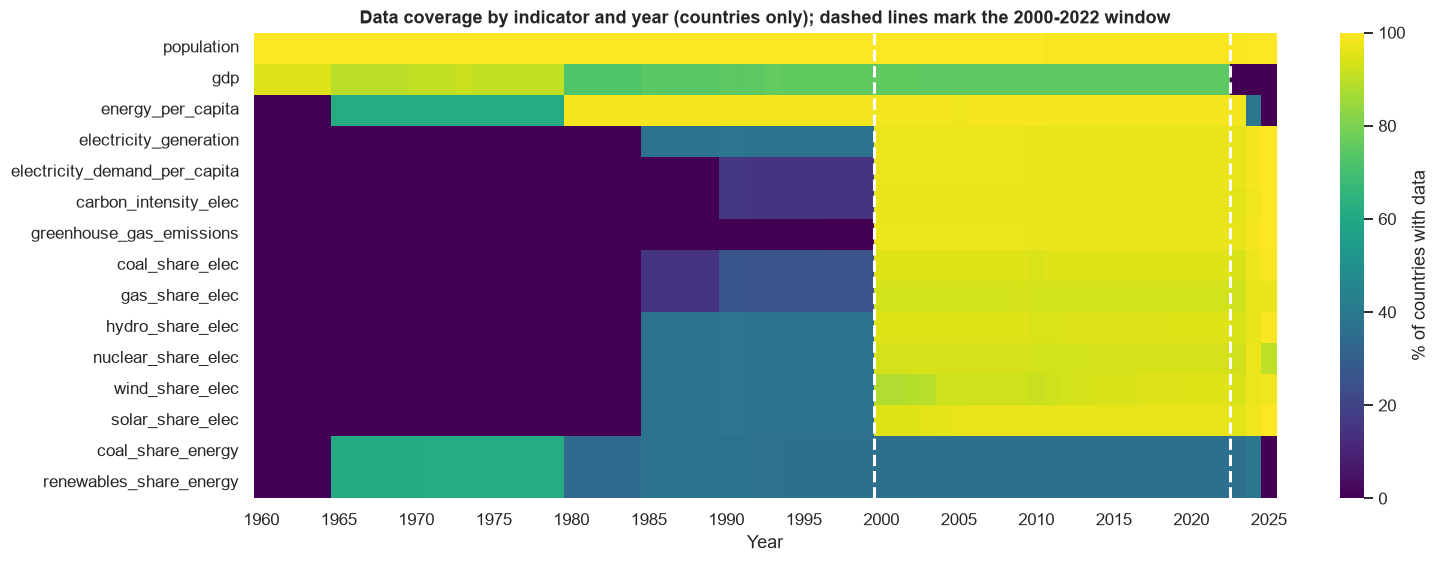

In [11]:
# Indicators that are candidates for the analysis
key_cols = ["population", "gdp", "energy_per_capita", "electricity_generation",
            "electricity_demand_per_capita", "carbon_intensity_elec", "greenhouse_gas_emissions",
            "coal_share_elec", "gas_share_elec", "hydro_share_elec", "nuclear_share_elec",
            "wind_share_elec", "solar_share_elec", "coal_share_energy", "renewables_share_energy"]

countries_only = raw[raw["iso_code"].notna()]
coverage = (countries_only[countries_only["year"] >= 1960]
            .groupby("year")[key_cols]
            .apply(lambda g: g.notna().mean() * 100)
            .T)

fig, ax = plt.subplots(figsize=(15, 5.5))
sns.heatmap(coverage, cmap="viridis", vmin=0, vmax=100, ax=ax,
            cbar_kws={"label": "% of countries with data"})
ax.set_xticks(np.arange(0.5, coverage.shape[1], 5))
ax.set_xticklabels(coverage.columns[::5], rotation=0)
ax.axvline(coverage.columns.get_loc(2000), color="white", lw=2, ls="--")
ax.axvline(coverage.columns.get_loc(2022) + 1, color="white", lw=2, ls="--")
ax.set_title("Data coverage by indicator and year (countries only); dashed lines mark the 2000-2022 window")
ax.set_xlabel("Year"); ax.set_ylabel("")
save_fig(fig, "fig01_coverage_by_year")
plt.show()

In [12]:
# Number of countries reporting electricity generation and GDP in recent years
recent = countries_only[countries_only["year"] >= 1995].groupby("year").agg(
    rows=("country", "size"),
    with_generation=("electricity_generation", "count"),
    with_gdp=("gdp", "count"))
recent.T

year,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
rows,216,216,217,217,217,217,217,217,218,218,219,219,219,219,219,219,219,220,220,220,220,220,220,220,220,220,220,220,220,199,90
with_generation,81,81,81,81,81,211,211,211,212,212,213,213,213,213,213,212,212,213,213,213,213,213,213,213,213,213,213,213,212,196,90
with_gdp,163,163,164,164,164,164,164,164,164,164,165,165,165,165,165,165,165,165,165,165,165,165,165,165,165,165,165,165,0,0,0


**Observations**
* Before **2000**, electricity-mix indicators exist for only a minority of countries (the Energy Institute
  covers about 80 large economies; Ember's country-level electricity data begin in 2000).
* From 2000 onwards, electricity generation is reported for about 211–213 of the roughly 220 countries
  (over 95 %), compared with only 81 in 1999.
* **GDP stops in 2022** (no country has a GDP value from 2023), and the 2024–2025 rows are incomplete
  (199 and 90 countries) because the latest figures had not yet been published everywhere.
* Primary-energy shares (`*_share_energy`) cover only about a third of countries even after 2000, so
  they are not suitable for a cross-country analysis.

The analysis window is therefore **2000–2022**: the longest period in which wealth, demand, emissions and
the electricity mix are all observed together.

### 5.5 Duplicate records

In [13]:
# Each (country, year) pair should appear once; check for exact and key-level duplicates
print("Fully duplicated rows        :", raw.duplicated().sum())
print("Duplicated (country, year)    :", raw.duplicated(subset=["country", "year"]).sum())

Fully duplicated rows        : 0
Duplicated (country, year)    : 0


No duplicates exist, so every row is a unique country-year observation.

## 6. Feature selection

### 6.1 Checking redundancy before dropping columns
Before discarding the derived columns, we confirm numerically that they can be rebuilt from the columns we
keep.

In [14]:
chk = countries_only[countries_only["year"].between(2000, 2022)]

# (a) renewables share should equal hydro + wind + solar + other renewables
renew_sum = chk[["hydro_share_elec", "wind_share_elec", "solar_share_elec",
                 "other_renewables_share_elec"]].sum(axis=1, min_count=4)
diff_a = (chk["renewables_share_elec"] - renew_sum).abs()

# (b) coal TWh should equal coal share x total generation / 100
coal_twh = chk["coal_share_elec"] * chk["electricity_generation"] / 100
diff_b = (chk["coal_electricity"] - coal_twh).abs()

# (c) fossil share + low-carbon share should equal 100 %
diff_c = (chk["fossil_share_elec"] + chk["low_carbon_share_elec"] - 100).abs()

print(f"(a) renewables share vs sum of parts : median |diff| = {diff_a.median():.3f} pp, "
      f"95th pct = {diff_a.quantile(0.95):.3f} pp")
print(f"(b) coal TWh vs share x generation   : median |diff| = {diff_b.median():.4f} TWh, "
      f"95th pct = {diff_b.quantile(0.95):.4f} TWh")
print(f"(c) fossil + low-carbon - 100        : median |diff| = {diff_c.median():.3f} pp, "
      f"95th pct = {diff_c.quantile(0.95):.3f} pp")
print(f"\nCorrelation of generation per capita with demand per capita: "
      f"{chk[['per_capita_electricity', 'electricity_demand_per_capita']].corr().iloc[0, 1]:.3f}")

(a) renewables share vs sum of parts : median |diff| = 0.000 pp, 95th pct = 0.001 pp
(b) coal TWh vs share x generation   : median |diff| = 0.0000 TWh, 95th pct = 0.0009 TWh
(c) fossil + low-carbon - 100        : median |diff| = 0.000 pp, 95th pct = 0.000 pp

Correlation of generation per capita with demand per capita: 0.978


The differences are essentially zero (rounding only), confirming that the aggregate shares, the
absolute TWh values per source and generation per capita add no new information. They are dropped.

### 6.2 Selected features

| Group | Column | Unit | Why it is kept |
|---|---|---|---|
| Identifier | `country`, `iso_code`, `year` | – | Identify each country-year (not used as model inputs) |
| Size & wealth | `population` | people | Scale of the country (Q2, Q3) |
| | `gdp` | int. $ (2011) | Wealth; converted to GDP per capita in Part 3 (Q3) |
| Demand | `energy_per_capita` | kWh/person | Total primary energy use per person |
| | `electricity_demand_per_capita` | kWh/person | Electricity use per person (Q2) |
| | `electricity_generation` | TWh | Size of the power system |
| | `net_elec_imports_share_demand` | % of demand | Import dependence (positive = net importer) |
| Emissions | `carbon_intensity_elec` | gCO₂e/kWh | **Main outcome**: how clean the electricity is (Q3, Q4) |
| | `greenhouse_gas_emissions` | MtCO₂e | Total power-sector emissions |
| Electricity mix | `coal_share_elec`, `gas_share_elec`, `oil_share_elec` | % | Fossil sources (Q1, Q5) |
| | `hydro_share_elec`, `nuclear_share_elec` | % | Established low-carbon sources (Q1, Q5) |
| | `wind_share_elec`, `solar_share_elec`, `other_renewables_share_elec` | % | Newer renewables and bioenergy (Q1, Q5) |

The eight source shares together describe the complete electricity mix and should sum to about 100 %;
this is used as a consistency check in Part 4.

**Excluded column families:** absolute TWh and per-capita values by source (redundant with the shares),
aggregate shares (`fossil_`, `low_carbon_`, `renewables_share_elec`, which are sums of the kept shares),
year-on-year change columns (derived; they can be recomputed if needed), primary-energy shares (poor
coverage) and fossil-fuel production (describes resource extraction rather than the electricity system).

In [15]:
ID_COLS = ["country", "iso_code", "year"]
NUM_COLS = ["population", "gdp",
            "energy_per_capita", "electricity_demand_per_capita", "electricity_generation",
            "net_elec_imports_share_demand",
            "carbon_intensity_elec", "greenhouse_gas_emissions",
            "coal_share_elec", "gas_share_elec", "oil_share_elec",
            "hydro_share_elec", "nuclear_share_elec",
            "wind_share_elec", "solar_share_elec", "other_renewables_share_elec"]
SHARE_COLS = [c for c in NUM_COLS if c.endswith("_share_elec")]
YEAR_MIN, YEAR_MAX = 2000, 2022

# Keep a log of how each step changes the size of the data
size_log = [("Raw file", *raw.shape)]

# Step 1: keep countries only (rows with an ISO code), and drop Antarctica (not a country)
df = raw[raw["iso_code"].notna() & (raw["country"] != "Antarctica")].copy()
size_log.append(("Countries only (drop aggregates, Antarctica)", *df.shape))

# Step 2: restrict to the 2000-2022 analysis window
df = df[df["year"].between(YEAR_MIN, YEAR_MAX)]
size_log.append((f"Years {YEAR_MIN}-{YEAR_MAX}", *df.shape))

# Step 3: keep only the selected columns
df = df[ID_COLS + NUM_COLS].reset_index(drop=True)
size_log.append(("Selected features", *df.shape))

pd.DataFrame(size_log, columns=["step", "rows", "columns"])

,step,rows,columns
0,Raw file,23377,130
1,"Countries only (drop aggregates, Antarctica)",17221,130
2,Years 2000-2022,5017,130
3,Selected features,5017,19


In [16]:
# Structure of the working dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5017 entries, 0 to 5016
Data columns (total 19 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   country                        5017 non-null   str    
 1   iso_code                       5017 non-null   str    
 2   year                           5017 non-null   int64  
 3   population                     5005 non-null   float64
 4   gdp                            3790 non-null   float64
 5   energy_per_capita              4952 non-null   float64
 6   electricity_demand_per_capita  4889 non-null   float64
 7   electricity_generation         4889 non-null   float64
 8   net_elec_imports_share_demand  4866 non-null   float64
 9   carbon_intensity_elec          4866 non-null   float64
 10  greenhouse_gas_emissions       4889 non-null   float64
 11  coal_share_elec                4786 non-null   float64
 12  gas_share_elec                 4696 non-null   float64
 13 

In [17]:
# Descriptive statistics of the selected numerical features (before any cleaning)
desc = df[NUM_COLS].describe().T
desc["missing"] = df[NUM_COLS].isna().sum()
desc["skew"] = df[NUM_COLS].skew()
desc

,count,mean,std,min,25%,50%,75%,max,missing,skew
population,"5,005.000","32,646,374.592","129,945,297.761","1,776.000","709,387.000","5,728,196.000","21,378,123.000","1,426,437,269.000",12,8.930
gdp,"3,790.000","569,702,956,099.186","1,921,935,720,268.344","312,853,560.000","23,664,833,206.250","77,276,510,484.000","351,581,500,321.250","26,966,016,991,166.000",1227,7.776
energy_per_capita,"4,952.000","26,971.664","42,982.767",0.000,"3,077.780","12,913.438","35,098.061","651,836.562",65,5.376
electricity_demand_per_capita,"4,889.000","3,846.924","5,162.362",0.000,531.868,"2,174.034","5,398.860","56,048.727",128,4.016
electricity_generation,"4,889.000",102.571,474.212,0.000,0.680,6.970,43.570,"8,848.710",128,10.457
net_elec_imports_share_demand,"4,866.000",0.806,44.639,-772.594,0.000,0.000,2.132,98.690,151,-8.470
carbon_intensity_elec,"4,866.000",477.593,248.256,0.000,285.912,533.285,653.850,"1,306.720",151,-0.140
greenhouse_gas_emissions,"4,889.000",54.270,288.846,0.000,0.220,1.850,18.600,"5,191.990",128,11.075
coal_share_elec,"4,786.000",11.616,21.882,0.000,0.000,0.000,13.089,100.000,231,2.079
gas_share_elec,"4,696.000",19.117,29.065,0.000,0.000,0.962,28.175,100.000,321,1.544


### 6.3 Summary of the working dataset
* **5,017 rows × 19 columns** (219 countries × 23 years, minus a few countries that did not exist for
  the whole period) — well above the required minimum of 3,000 rows and 7 columns.
* **Very different scales:** population ranges from under 2,000 people to 1.43 billion and
  generation from almost 0 TWh to about 8,850 TWh (China, 2022). Features must be **scaled** before PCA (Part 7).
* **Strong right skew** (skewness between about 4 and 11) for population, GDP, demand, generation and
  emissions: the mean
  is far above the median because a few very large countries (China, the USA, India) dominate. These are
  candidates for a **log transformation** when outliers are treated (Part 4).
* **Suspicious values:** some rows have an energy use, demand or carbon intensity of exactly **0**, and
  `net_elec_imports_share_demand` reaches **−773 %** (a country exporting about eight times the electricity
  it uses). These are examined as outliers in Part 4.
* **Missing values** remain in every indicator, most of all in GDP (1,227 rows, 24 %). Part 3 analyses
  these gaps and treats them.

## 7. Handling missing values

Missing data are handled in three stages: **measure** how much is missing, **diagnose** why it is missing
(the mechanism decides which treatment is valid), then **treat** each type of gap with a method that
suits its cause.

### 7.1 How much is missing?

Rows with at least one missing value: 1,470 of 5,017
Missing cells in total             : 3,934 (4.9% of all numeric cells)



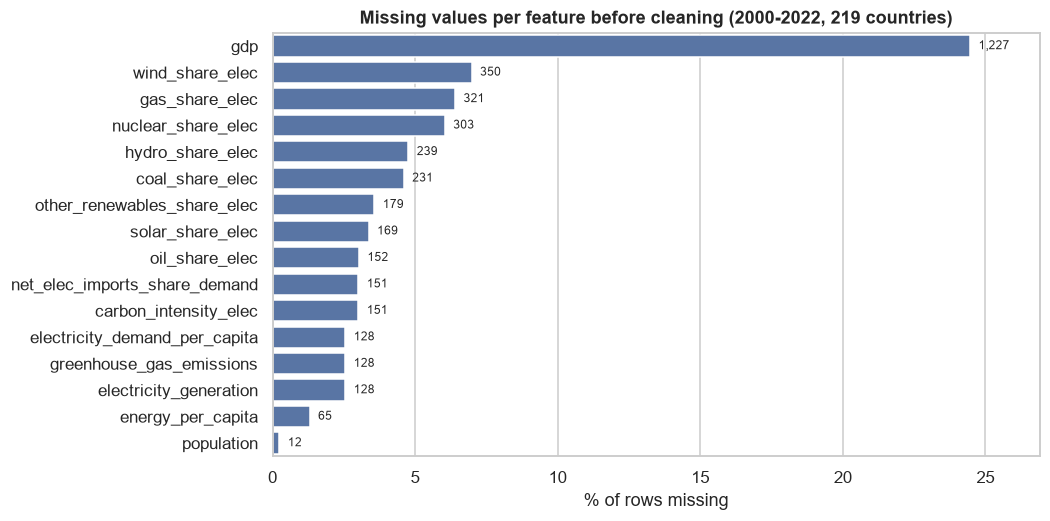

In [18]:
# Missing values per selected column, as a count and as a percentage of rows
missing = pd.DataFrame({"missing": df[NUM_COLS].isna().sum(),
                        "pct": (df[NUM_COLS].isna().mean() * 100).round(2)}
                       ).sort_values("missing", ascending=False)
print(f"Rows with at least one missing value: {df[NUM_COLS].isna().any(axis=1).sum():,} of {len(df):,}")
print(f"Missing cells in total             : {df[NUM_COLS].isna().sum().sum():,} "
      f"({df[NUM_COLS].isna().mean().mean() * 100:.1f}% of all numeric cells)\n")

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=missing["pct"], y=missing.index, color="#4C72B0", ax=ax)
for i, (n, p) in enumerate(zip(missing["missing"], missing["pct"])):
    ax.text(p + 0.3, i, f"{n:,}", va="center", fontsize=8)
ax.set_xlim(0, missing["pct"].max() * 1.1)          # leave room for the count labels
ax.set_xlabel("% of rows missing"); ax.set_ylabel("")
ax.set_title("Missing values per feature before cleaning (2000-2022, 219 countries)")
save_fig(fig, "fig02_missing_values_before")
plt.show()

GDP is by far the most incomplete feature (about a quarter of rows), followed by the source shares and a
block of electricity indicators that are missing together (≈ 128–151 rows each).

### 7.2 Why is it missing? (missingness mechanism)

#### (a) GDP: whole countries are missing

In [19]:
# For every country, count the years with a GDP value (out of the years the country is in the data)
gdp_years = df.groupby("country").agg(years=("year", "size"), gdp_years=("gdp", "count"))
gdp_years["status"] = np.select(
    [gdp_years["gdp_years"] == 0, gdp_years["gdp_years"] < gdp_years["years"]],
    ["no GDP at all", "partly missing"], default="complete")
print(gdp_years["status"].value_counts().to_string(), "\n")

no_gdp = gdp_years.index[gdp_years["status"] == "no GDP at all"].tolist()
print(f"{len(no_gdp)} countries never have a GDP value:\n", no_gdp)

status
complete         165
no GDP at all     54 

54 countries never have a GDP value:
 ['American Samoa', 'Antigua and Barbuda', 'Aruba', 'Bahamas', 'Belize', 'Bermuda', 'Bhutan', 'British Virgin Islands', 'Brunei', 'Cayman Islands', 'Cook Islands', 'Curacao', 'East Timor', 'Eritrea', 'Falkland Islands', 'Faroe Islands', 'Fiji', 'French Guiana', 'French Polynesia', 'Gibraltar', 'Greenland', 'Grenada', 'Guadeloupe', 'Guam', 'Guyana', 'Kiribati', 'Macao', 'Maldives', 'Martinique', 'Micronesia (country)', 'Montserrat', 'Nauru', 'Netherlands Antilles', 'New Caledonia', 'Niue', 'Northern Mariana Islands', 'Papua New Guinea', 'Reunion', 'Saint Helena', 'Saint Kitts and Nevis', 'Saint Pierre and Miquelon', 'Saint Vincent and the Grenadines', 'Samoa', 'Solomon Islands', 'Somalia', 'South Sudan', 'Sudan', 'Suriname', 'Tonga', 'Turks and Caicos Islands', 'Tuvalu', 'United States Virgin Islands', 'Vanuatu', 'Western Sahara']


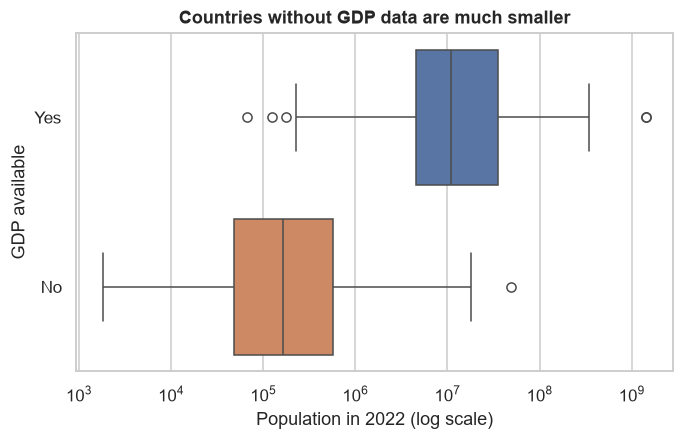

GDP available
No        165,193
Yes    11,059,822
Name: population_2022, dtype: str


In [20]:
# Is the absence of GDP related to the size of the country? Compare median population (2022)
pop22 = df[df["year"] == 2022].set_index("country")["population"]
size_cmp = pd.DataFrame({"population_2022": pop22,
                         "GDP available": np.where(pop22.index.isin(no_gdp), "No", "Yes")})

fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=size_cmp, x="population_2022", y="GDP available", log_scale=True, ax=ax,
            hue="GDP available", palette={"No": "#DD8452", "Yes": "#4C72B0"},
            order=["Yes", "No"], legend=False)
ax.set_xlabel("Population in 2022 (log scale)")
ax.set_title("Countries without GDP data are much smaller")
save_fig(fig, "fig03_gdp_missingness_vs_population")
plt.show()

print(size_cmp.groupby("GDP available")["population_2022"].median().map("{:,.0f}".format))

GDP is missing for **54 entire countries**, not for scattered years. They are mostly small island states and
overseas territories (e.g. *Aruba*, *Guam*, *Tuvalu*) plus a few countries affected by conflict or
secession (*Somalia*, *Sudan*, *South Sudan*, *Eritrea*). Their median population in 2022 (≈ 165,000) is
about 65 times smaller than that of countries with GDP (≈ 11 million). The values are therefore **not missing completely at random**:
missingness depends on country size and status (*missing at random* given population, and arguably *not
at random* for conflict states). Because there is no GDP value at all for these countries, there is nothing
within the country to interpolate from, and filling them from other countries would invent the wealth
of an entire nation.

#### (b) Electricity-mix shares: "missing" that really means zero

In [21]:
# Singapore as an example: it has no hydro, wind or nuclear plants, but those cells are NaN rather than 0
df.loc[df["country"] == "Singapore", ["year"] + SHARE_COLS].head(4)

,year,coal_share_elec,gas_share_elec,oil_share_elec,hydro_share_elec,nuclear_share_elec,wind_share_elec,solar_share_elec,other_renewables_share_elec
4063,2000,0.000,18.503,79.949,NaN,0.000,NaN,0.000,1.547
4064,2001,0.000,47.822,50.091,NaN,0.000,NaN,0.000,2.087
4065,2002,0.000,53.866,43.912,NaN,0.000,NaN,0.000,2.222
4066,2003,0.000,60.730,36.467,NaN,0.000,NaN,0.000,2.803


In [22]:
# Across all rows where at least one share is missing but others are present,
# what do the reported shares add up to?
partial = df[SHARE_COLS].isna().any(axis=1) & df[SHARE_COLS].notna().any(axis=1)
reported_total = df.loc[partial, SHARE_COLS].sum(axis=1)
print(f"Rows with some (not all) shares missing: {partial.sum()}")
print("Sum of the shares that ARE reported in those rows:")
print(reported_total.describe().round(3).to_string())

Rows with some (not all) shares missing: 335
Sum of the shares that ARE reported in those rows:
count   335.000
mean    100.000
std       0.001
min      99.998
25%     100.000
50%     100.000
75%     100.000
max     100.002


In every one of these rows the reported shares **already add up to 100 %**. A missing share is therefore a
**structural zero**: the country simply does not generate electricity from that source, and the source
did not record a 0. This is a case where domain knowledge gives the exact value, so no statistical
imputation is needed.

#### (c) The remaining gaps

In [23]:
# After removing the no-GDP countries, which other gaps are left (apart from the share columns)?
other_cols = [c for c in NUM_COLS if c not in SHARE_COLS + ["gdp"]]
left = df[~df["country"].isin(no_gdp)]
left.loc[left[other_cols].isna().any(axis=1), ["country", "year"] + other_cols[:3]]

,country,year,population,energy_per_capita,electricity_demand_per_capita
2964,Montenegro,2005,"634,059.000",NaN,"7,349.474"
3994,Serbia,2000,"7,694,608.000",NaN,"4,543.441"
3995,Serbia,2001,"7,651,927.000",NaN,"4,784.416"
3996,Serbia,2002,"7,616,741.000",NaN,"4,952.250"
3997,Serbia,2003,"7,590,946.000",NaN,"4,880.814"
3998,Serbia,2004,"7,565,843.000",NaN,"4,879.826"
3999,Serbia,2005,"7,539,139.000",NaN,"4,499.188"


Only seven `energy_per_capita` values remain missing, for *Serbia* (2000–2005) and *Montenegro* (2005).
These two countries were one state (*Serbia and Montenegro*) until 2006, so their separate energy figures
start later. These gaps sit at the start of each country's time series.

### 7.3 Treatment strategy

| Type of gap | Cause | Rows affected | Treatment | Justification |
|---|---|---|---|---|
| GDP missing for the whole country | Country not covered by the GDP source (small territories, conflict states) | 1,227 rows / 54 countries | **Drop the country** (listwise deletion at country level) | No value to anchor an estimate; GDP is central to Q3; 3,790 rows remain |
| Source share missing, other shares sum to 100 % | Structural zero (source not used) | 243 rows | **Replace with 0** | Exact value known from domain logic |
| `energy_per_capita` at the start of a series | Country split in 2006 | 7 rows | **Within-country interpolation / nearest-year fill** | Chosen by the validation experiment in 7.6 |

### 7.4 Step A – drop countries that have no GDP at all

In [24]:
before = df.shape
df = df[~df["country"].isin(no_gdp)].reset_index(drop=True)
size_log.append(("Drop 54 countries without any GDP value", *df.shape))

print(f"Before: {before[0]:,} rows | after: {df.shape[0]:,} rows | countries left: {df['country'].nunique()}")
print("GDP values still missing:", df["gdp"].isna().sum())

Before: 5,017 rows | after: 3,790 rows | countries left: 165
GDP values still missing: 0


### 7.5 Step B – structural zeros in the electricity mix

In [25]:
# Fill a missing share with 0 only when the shares that are present already total (about) 100 %.
# A tolerance of 0.5 percentage points allows for rounding in the source data.
reported_total = df[SHARE_COLS].sum(axis=1)                 # NaN is skipped in the sum
can_fill = df[SHARE_COLS].isna().any(axis=1) & (reported_total.sub(100).abs() <= 0.5)

n_cells = df.loc[can_fill, SHARE_COLS].isna().sum().sum()
df.loc[can_fill, SHARE_COLS] = df.loc[can_fill, SHARE_COLS].fillna(0)

print(f"Rows treated: {can_fill.sum()} | cells set to 0: {n_cells}")
print("Shares still missing:", df[SHARE_COLS].isna().sum().sum())

Rows treated: 243 | cells set to 0: 429
Shares still missing: 0


### 7.6 Step C – choosing an imputation method by validation

Rather than picking an imputation method by habit, the candidate methods are **tested on values we
already know**. 10 % of the observed `energy_per_capita` values are hidden at random, each method fills
them in, and the estimates are compared with the true values:

1. **Global median** – one value for every gap.
2. **Median of the same year** – accounts for change over time.
3. **K-nearest neighbours (KNN, k = 5)** – borrows from the five most similar country-years, judged on
   demand, GDP per capita and carbon intensity.
4. **Within-country linear interpolation** – uses the same country's neighbouring years
   (nearest available year at the edges of a series).

In [26]:
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

TARGET = "energy_per_capita"
df = df.sort_values(["country", "year"]).reset_index(drop=True)


def interpolate_within_country(frame, col):
    # Linear interpolation along the years of each country; edge gaps take the nearest observed year
    return frame.groupby("country")[col].transform(
        lambda s: s.interpolate(method="linear", limit_direction="both"))


# Hide 10 % of the known values (fixed seed for reproducibility)
known_idx = df.index[df[TARGET].notna()]
rng = np.random.default_rng(RANDOM_STATE)
mask_idx = rng.choice(known_idx, size=int(0.10 * len(known_idx)), replace=False)
truth = df.loc[mask_idx, TARGET]
test = df.copy()
test.loc[mask_idx, TARGET] = np.nan

estimates = {}
# 1. Global median
estimates["Global median"] = pd.Series(test[TARGET].median(), index=mask_idx)
# 2. Median of the same year
estimates["Year median"] = test.groupby("year")[TARGET].transform("median").loc[mask_idx]
# 3. KNN on log-scaled, standardised helper features
helpers = pd.DataFrame({
    "log_demand": np.log1p(test["electricity_demand_per_capita"]),
    "log_gdp_pc": np.log1p(test["gdp"] / test["population"]),
    "carbon": test["carbon_intensity_elec"],
    "log_target": np.log1p(test[TARGET])})
scaled = StandardScaler().fit_transform(helpers)          # NaN is ignored when fitting
knn_out = KNNImputer(n_neighbors=5).fit_transform(scaled)
log_target_hat = knn_out[:, 3] * helpers["log_target"].std(ddof=0) + helpers["log_target"].mean()
estimates["KNN (k=5)"] = pd.Series(np.expm1(log_target_hat), index=test.index).loc[mask_idx]
# 4. Within-country linear interpolation
estimates["Within-country interpolation"] = interpolate_within_country(test, TARGET).loc[mask_idx]

results = pd.DataFrame({
    name: {"MAE (kWh/person)": (est - truth).abs().mean(),
           "Median abs. % error": ((est - truth).abs() / truth.replace(0, np.nan)).median() * 100}
    for name, est in estimates.items()}).T.sort_values("MAE (kWh/person)")
results

,MAE (kWh/person),Median abs. % error
Within-country interpolation,"1,065.586",2.484
KNN (k=5),"3,610.216",8.494
Global median,"21,305.848",77.212
Year median,"21,605.647",77.237


Within-country interpolation is far more accurate than the alternatives: a country's energy use in one
year is very close to its use in the neighbouring years, while medians ignore which country a row
belongs to and KNN only partly recovers it. It is therefore used for the seven real gaps.

In [27]:
# Apply the winning method to the real gaps
n_before = df[TARGET].isna().sum()
df[TARGET] = interpolate_within_country(df, TARGET)
print(f"{TARGET}: {n_before} gaps filled, {df[TARGET].isna().sum()} remaining")

# Serbia's imputed early years (taken from its nearest observed year, 2006)
df.loc[df["country"] == "Serbia", ["country", "year", TARGET]].head(8)

energy_per_capita: 7 gaps filled, 0 remaining


,country,year,energy_per_capita
3008,Serbia,2000,"24,499.482"
3009,Serbia,2001,"24,499.482"
3010,Serbia,2002,"24,499.482"
3011,Serbia,2003,"24,499.482"
3012,Serbia,2004,"24,499.482"
3013,Serbia,2005,"24,499.482"
3014,Serbia,2006,"24,499.482"
3015,Serbia,2007,"24,744.312"


### 7.7 Verification

In [28]:
# Every numeric feature must now be complete
remaining = df[NUM_COLS].isna().sum()
print("Missing values remaining per column:")
print(remaining.to_string())
assert remaining.sum() == 0, "There are still missing values"

pd.DataFrame(size_log, columns=["step", "rows", "columns"])

Missing values remaining per column:
population                       0
gdp                              0
energy_per_capita                0
electricity_demand_per_capita    0
electricity_generation           0
net_elec_imports_share_demand    0
carbon_intensity_elec            0
greenhouse_gas_emissions         0
coal_share_elec                  0
gas_share_elec                   0
oil_share_elec                   0
hydro_share_elec                 0
nuclear_share_elec               0
wind_share_elec                  0
solar_share_elec                 0
other_renewables_share_elec      0


,step,rows,columns
0,Raw file,23377,130
1,"Countries only (drop aggregates, Antarctica)",17221,130
2,Years 2000-2022,5017,130
3,Selected features,5017,19
4,Drop 54 countries without any GDP value,3790,19


The dataset now has **no missing values** and keeps **3,790 rows** for **165 countries** (164 countries ×
23 years, plus Montenegro from 2005). Of all the cells in the 2000–2022 data, only 7 values were estimated
statistically, 429 were set to a known zero, and the rest are original values.

**Limitation:** dropping countries without GDP removes most small island states, so conclusions apply to
countries covered by the GDP source and may not hold for very small economies.

## 8. Feature engineering

New features are derived from the cleaned columns to answer the research questions directly and to give
the categorical variables needed for encoding in Part 7.

| New feature | Type | Definition | Purpose |
|---|---|---|---|
| `gdp_per_capita` | numeric | `gdp / population` (int. $ per person) | Wealth independent of country size (Q3) |
| `low_carbon_share_elec` | numeric | hydro + nuclear + wind + solar + other renewables | Overall cleanliness of the mix (Q1, Q4) |
| `continent` | nominal (6 levels) | Continent of the country | Regional comparison (Q4); one-hot encoding |
| `dominant_source` | nominal | Source with the largest share in that country-year | Type of power system (Q5); label encoding |
| `income_group` | ordinal (4 levels) | Quartile of GDP per capita across the panel | Wealth bands (Q3); ordinal encoding |

In [29]:
# --- GDP per capita -----------------------------------------------------------------
df["gdp_per_capita"] = df["gdp"] / df["population"]

# --- Low-carbon share: recomputed from the cleaned components so it stays consistent --------
LOW_CARBON = ["hydro_share_elec", "nuclear_share_elec", "wind_share_elec",
              "solar_share_elec", "other_renewables_share_elec"]
df["low_carbon_share_elec"] = df[LOW_CARBON].sum(axis=1)

df[["gdp_per_capita", "low_carbon_share_elec"]].describe().T

,count,mean,std,min,25%,50%,75%,max
gdp_per_capita,"3,790.000","16,369.636","18,021.873",421.565,"3,429.116","10,079.781","23,658.138","163,531.400"
low_carbon_share_elec,"3,790.000",39.151,34.048,0.000,6.722,32.984,66.336,100.001


In [30]:
# --- Continent ------------------------------------------------------------------------
# ISO 3166 alpha-3 code -> continent, following Our World in Data's continent definitions
# (e.g. Russia and Cyprus in Europe; Turkey and the Caucasus in Asia; Central America and the
# Caribbean in North America).
CONTINENTS = {
    "Africa": ["AGO", "BDI", "BEN", "BFA", "BWA", "CAF", "CIV", "CMR", "COD", "COG", "COM", "CPV",
               "DJI", "DZA", "EGY", "ETH", "GAB", "GHA", "GIN", "GMB", "GNB", "GNQ", "KEN", "LBR",
               "LBY", "LSO", "MAR", "MDG", "MLI", "MOZ", "MRT", "MUS", "MWI", "NAM", "NER", "NGA",
               "RWA", "SEN", "SLE", "STP", "SWZ", "SYC", "TCD", "TGO", "TUN", "TZA", "UGA", "ZAF",
               "ZMB", "ZWE"],
    "Asia": ["AFG", "ARE", "ARM", "AZE", "BGD", "BHR", "CHN", "GEO", "HKG", "IDN", "IND", "IRN",
             "IRQ", "ISR", "JOR", "JPN", "KAZ", "KGZ", "KHM", "KOR", "KWT", "LAO", "LBN", "LKA",
             "MMR", "MNG", "MYS", "NPL", "OMN", "PAK", "PHL", "PRK", "PSE", "QAT", "SAU", "SGP",
             "SYR", "THA", "TJK", "TKM", "TUR", "TWN", "UZB", "VNM", "YEM"],
    "Europe": ["ALB", "AUT", "BEL", "BGR", "BIH", "BLR", "CHE", "CYP", "CZE", "DEU", "DNK", "ESP",
               "EST", "FIN", "FRA", "GBR", "GRC", "HRV", "HUN", "IRL", "ISL", "ITA", "LTU", "LUX",
               "LVA", "MDA", "MKD", "MLT", "MNE", "NLD", "NOR", "POL", "PRT", "ROU", "RUS", "SRB",
               "SVK", "SVN", "SWE", "UKR"],
    "North America": ["BRB", "CAN", "CRI", "CUB", "DMA", "DOM", "GTM", "HND", "HTI", "JAM", "LCA",
                      "MEX", "NIC", "PAN", "PRI", "SLV", "TTO", "USA"],
    "South America": ["ARG", "BOL", "BRA", "CHL", "COL", "ECU", "PER", "PRY", "URY", "VEN"],
    "Oceania": ["AUS", "NZL"],
}
iso_to_continent = {iso: cont for cont, codes in CONTINENTS.items() for iso in codes}
df["continent"] = df["iso_code"].map(iso_to_continent)

unmapped = df.loc[df["continent"].isna(), "country"].unique()
assert len(unmapped) == 0, f"Countries without a continent: {unmapped}"
df.groupby("continent")["country"].nunique().rename("countries").to_frame().T

continent,Africa,Asia,Europe,North America,Oceania,South America
countries,50,45,40,18,2,10


In [31]:
# --- Dominant source: the source with the largest share of generation in that country-year ---
df["dominant_source"] = (df[SHARE_COLS].idxmax(axis=1)
                         .str.replace("_share_elec", "", regex=False)
                         .str.replace("other_renewables", "bioenergy & other", regex=False))

# --- Income group: quartiles of GDP per capita over the whole 2000-2022 panel ---------------
# (a relative, data-driven banding; it is not the official World Bank classification)
INCOME_LEVELS = ["Low", "Lower-middle", "Upper-middle", "High"]
df["income_group"] = pd.qcut(df["gdp_per_capita"], q=4, labels=INCOME_LEVELS)

print("Dominant source (rows):")
print(df["dominant_source"].value_counts().to_string())
print("\nIncome group boundaries (int. $ per person):")
print(df.groupby("income_group", observed=True)["gdp_per_capita"].agg(["min", "max", "size"])
      .round(0).to_string())

Dominant source (rows):
dominant_source
hydro                1142
gas                   920
oil                   854
coal                  622
nuclear               198
bioenergy & other      35
wind                   19

Income group boundaries (int. $ per person):
                    min         max  size
income_group                             
Low             422.000   3,428.000   948
Lower-middle  3,433.000  10,076.000   947
Upper-middle 10,083.000  23,599.000   947
High         23,678.000 163,531.000   948


**Notes on the engineered features**
* `continent` is imbalanced: *Oceania* has only two countries (Australia and New Zealand) after cleaning,
  which must be kept in mind when comparing continents.
* `dominant_source` is dominated by hydro, gas, oil and coal; nuclear leads in about 200 country-years,
  wind and bioenergy in only a few dozen, and solar is never the largest source. This imbalance is
  explored in Part 6.
* `income_group` is relative to this panel. Because the quartiles pool all years, a country can move up a
  group as it grows richer, which lets us follow development over time.

In [32]:
CAT_COLS = ["continent", "dominant_source", "income_group"]
ENG_NUM_COLS = ["gdp_per_capita", "low_carbon_share_elec"]

print(f"Working dataset: {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"  identifiers : {ID_COLS}")
print(f"  numeric     : {len(NUM_COLS) + len(ENG_NUM_COLS)} features")
print(f"  categorical : {CAT_COLS}")
df[ID_COLS + ["gdp_per_capita", "carbon_intensity_elec", "low_carbon_share_elec"] + CAT_COLS].sample(
    6, random_state=RANDOM_STATE)

Working dataset: 3,790 rows x 24 columns
  identifiers : ['country', 'iso_code', 'year']
  numeric     : 18 features
  categorical : ['continent', 'dominant_source', 'income_group']


,country,iso_code,year,gdp_per_capita,carbon_intensity_elec,low_carbon_share_elec,continent,dominant_source,income_group
1580,Indonesia,IDN,2016,"10,656.076",689.030,15.368,Asia,coal,Upper-middle
2257,Mongolia,MNG,2003,"3,813.152",909.970,0.000,Asia,coal,Lower-middle
263,Barbados,BRB,2010,"12,421.158",660.190,0.000,North America,oil,Upper-middle
1837,Kuwait,KWT,2020,"45,406.860",650.190,0.120,Asia,gas,High
3654,Uzbekistan,UZB,2002,"4,832.988","1,049.390",12.186,Asia,gas,Lower-middle
1674,Israel,ISR,2018,"33,484.633",643.580,2.724,Asia,gas,High


## 9. Outliers and consistency checks

An outlier is not automatically an error. Each extreme value is placed in one of three groups, and each
group is treated differently:

| Group | Example | Treatment |
|---|---|---|
| **Genuine extreme** – real, explainable value | Iceland's electricity demand | Keep; reduce skew with a log transform |
| **Data error / inconsistency** – breaks a physical or accounting rule | Zero emissions from a hydro system | Correct, then re-derive dependent columns |
| **Contextual outlier** – sudden change in a country's own series | A nuclear plant closing | Keep; note as an event |

### 9.1 Statistical detection: IQR rule and z-scores
Two standard rules are applied to every numeric feature:
* **IQR rule (Tukey's fences):** a value is an outlier if it lies below Q1 − 1.5·IQR or above Q3 + 1.5·IQR.
* **z-score rule:** a value is an outlier if it lies more than 3 standard deviations from the mean.

In [33]:
ALL_NUM = NUM_COLS + ENG_NUM_COLS        # 16 original + 2 engineered numeric features


def iqr_outliers(s):
    # Boolean mask of values outside Tukey's fences
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)


def z_outliers(s, threshold=3):
    # Boolean mask of values more than `threshold` standard deviations from the mean
    return ((s - s.mean()) / s.std()).abs() > threshold


outlier_table = pd.DataFrame({
    "IQR outliers": {c: iqr_outliers(df[c]).sum() for c in ALL_NUM},
    "z-score outliers": {c: z_outliers(df[c]).sum() for c in ALL_NUM},
    "% zeros": {c: round((df[c] == 0).mean() * 100, 1) for c in ALL_NUM},
    "skewness": {c: round(df[c].skew(), 2) for c in ALL_NUM},
})
outlier_table["IQR %"] = (outlier_table["IQR outliers"] / len(df) * 100).round(1)
outlier_table.sort_values("IQR outliers", ascending=False)

,IQR outliers,z-score outliers,% zeros,skewness,IQR %
net_elec_imports_share_demand,961,41,31.100,-8.700,25.400
wind_share_elec,750,97,58.000,4.970,19.800
solar_share_elec,725,89,57.600,5.860,19.100
nuclear_share_elec,717,120,81.100,3.200,18.900
other_renewables_share_elec,577,88,42.500,4.870,15.200
greenhouse_gas_emissions,563,52,0.600,9.760,14.900
electricity_generation,535,44,0.000,9.230,14.100
gdp,504,54,0.000,7.780,13.300
population,438,46,0.000,7.800,11.600
coal_share_elec,419,76,52.500,1.780,11.100


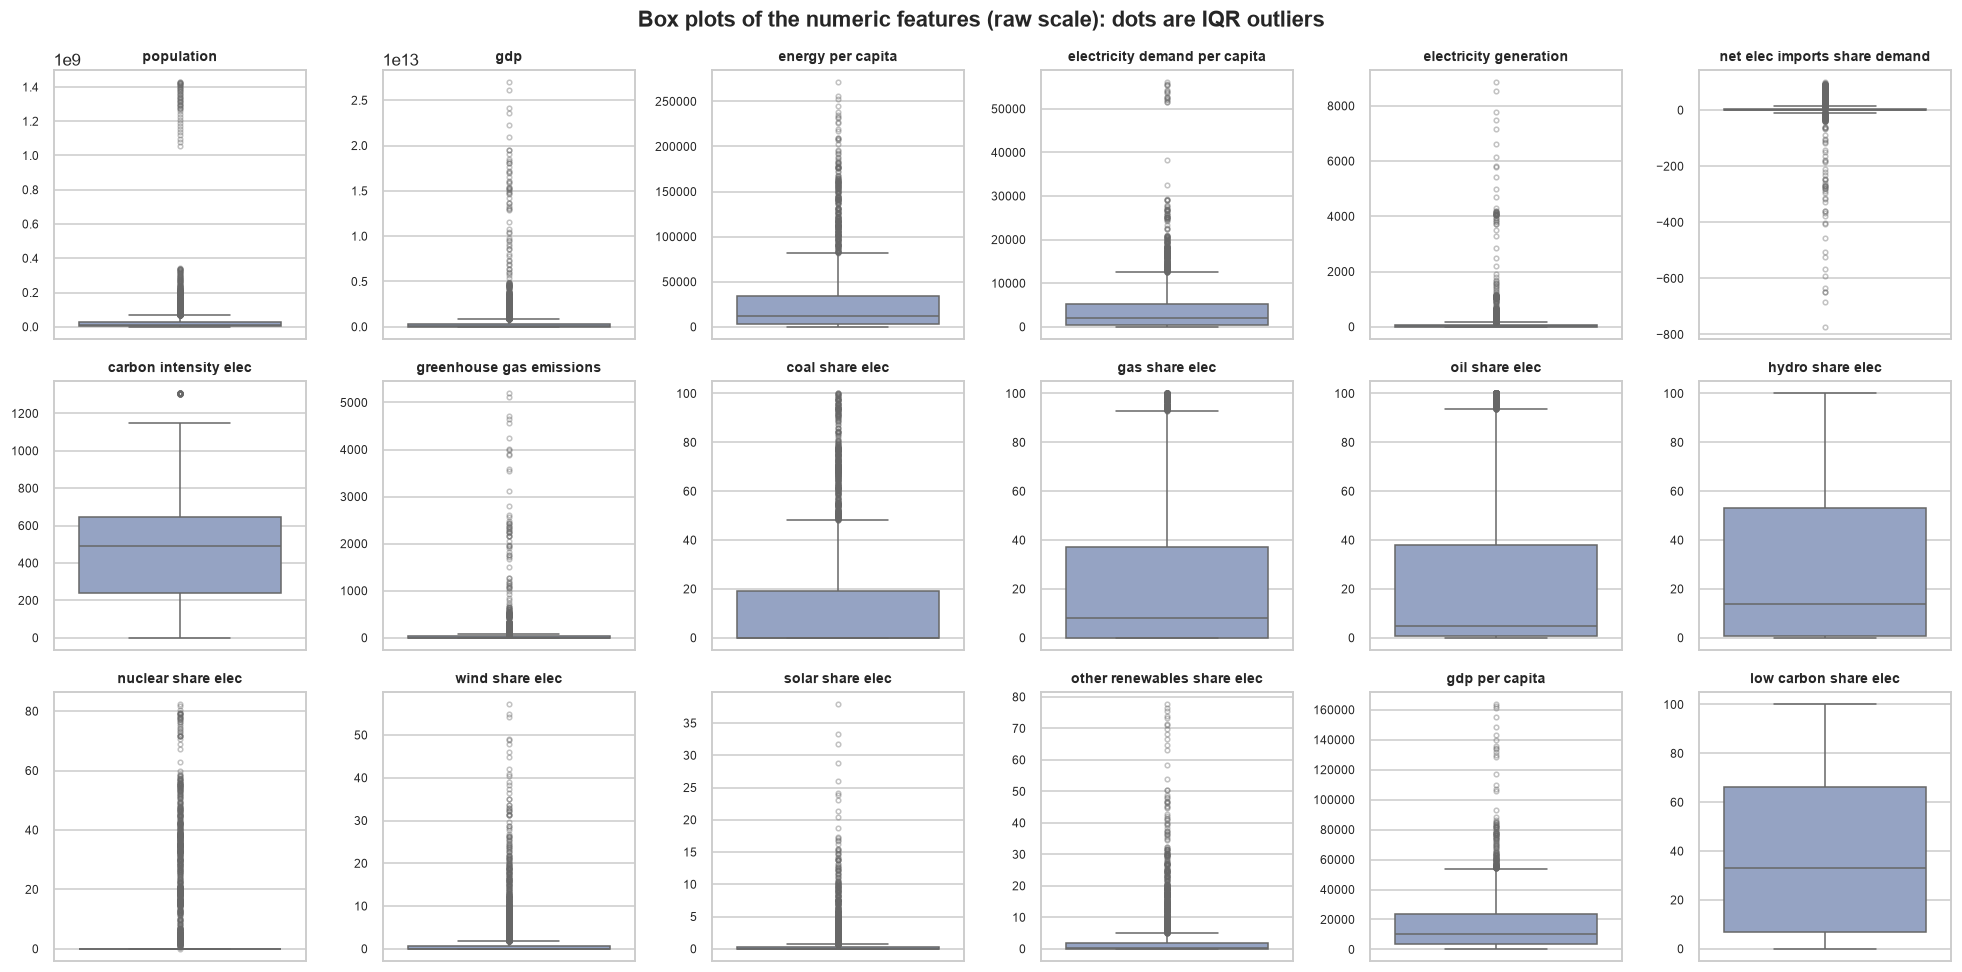

In [34]:
# Box plot of every numeric feature on its own scale
fig, axes = plt.subplots(3, 6, figsize=(18, 9))
for ax, col in zip(axes.ravel(), ALL_NUM):
    sns.boxplot(y=df[col], ax=ax, color="#8DA0CB", flierprops={"marker": ".", "alpha": 0.4})
    ax.set_title(col.replace("_", " "), fontsize=9)
    ax.set_ylabel(""); ax.tick_params(labelsize=8)
fig.suptitle("Box plots of the numeric features (raw scale): dots are IQR outliers", fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig04_boxplots_raw")
plt.show()

**Why the counts are misleading on their own**
* For **size variables** (population, GDP, generation, emissions) the IQR rule flags 10–15 % of rows.
  These variables are strongly right-skewed: the distribution is roughly log-normal, so large countries
  look extreme on a linear scale even though they are perfectly valid.
* For **nuclear, wind and solar shares** most values are exactly zero (the median is 0), so the IQR is
  close to 0 and *any* country that uses the source is flagged. These are zero-inflated variables, and
  the IQR rule is simply not suitable for them.
* The z-score rule flags fewer values, but it assumes a symmetric, roughly normal distribution, which
  none of the size variables have.

A better test is to apply the rules **after a log transform**, which turns multiplicative differences
between countries into additive ones.

### 9.2 Effect of a log transform on skewed features

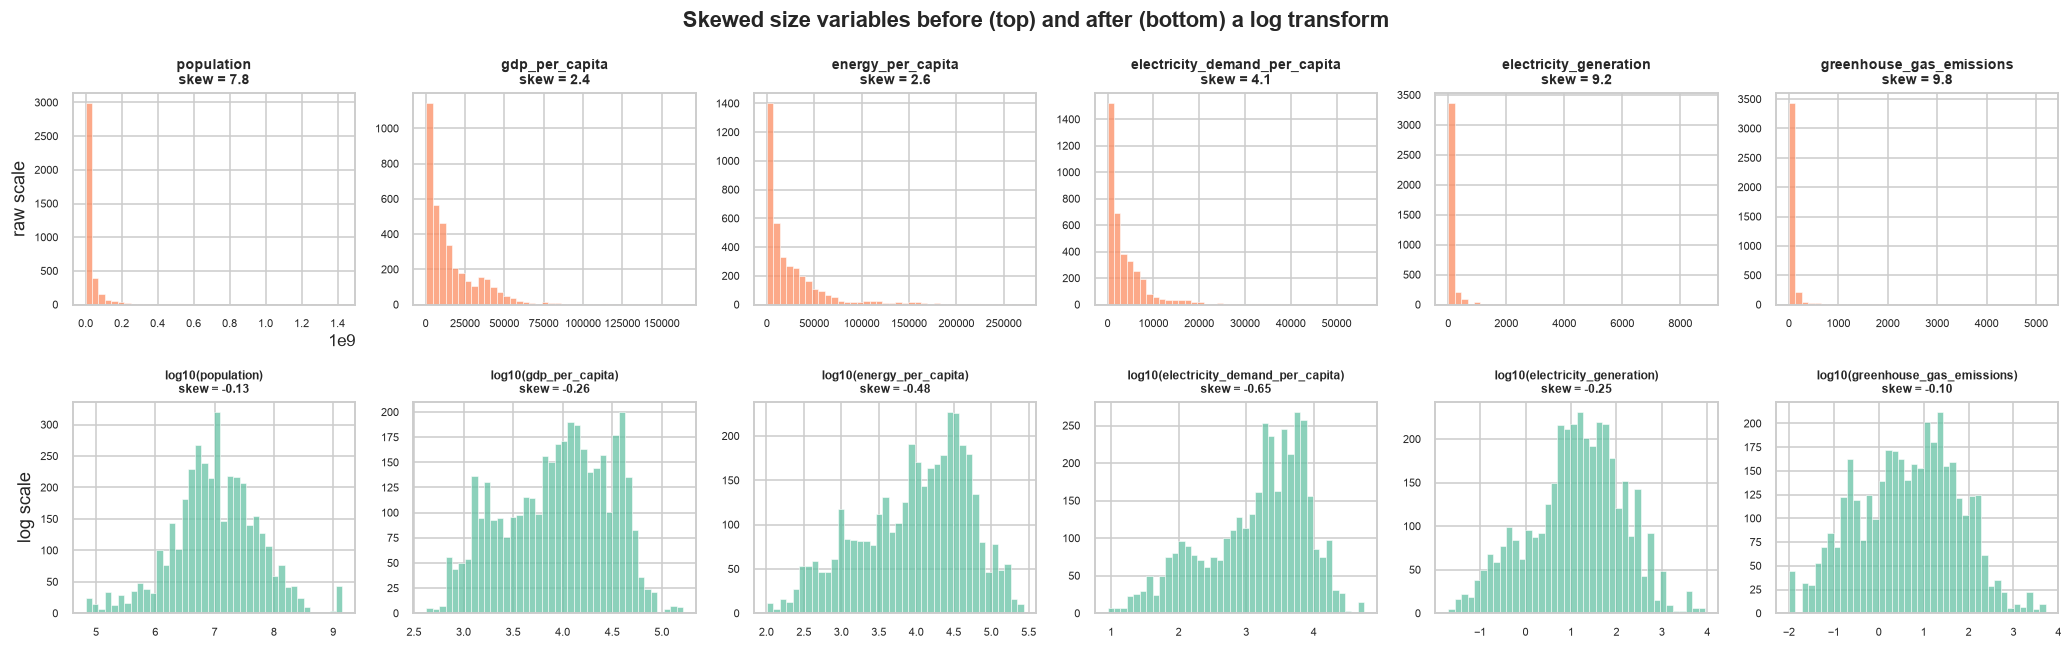

,IQR outliers (raw),IQR outliers (log)
population,438,126
gdp_per_capita,132,0
energy_per_capita,260,0
electricity_demand_per_capita,237,14
electricity_generation,535,27
greenhouse_gas_emissions,563,0


In [35]:
# Heavily right-skewed size variables. A base-10 logarithm is used: one unit on the log scale is a
# factor of 10 (an "order of magnitude"). The 21 rows with zero emissions are errors that are
# corrected in Section 9.6, so they are left out of this preview (log10(0) is undefined).
SKEWED = ["population", "gdp_per_capita", "energy_per_capita", "electricity_demand_per_capita",
          "electricity_generation", "greenhouse_gas_emissions"]

fig, axes = plt.subplots(2, len(SKEWED), figsize=(19, 6))
for i, col in enumerate(SKEWED):
    sns.histplot(df[col], bins=40, ax=axes[0, i], color="#FC8D62")
    positive = df.loc[df[col] > 0, col]
    sns.histplot(np.log10(positive), bins=40, ax=axes[1, i], color="#66C2A5")
    axes[0, i].set_title(f"{col}\nskew = {df[col].skew():.1f}", fontsize=9)
    axes[1, i].set_title(f"log10({col})\nskew = {np.log10(positive).skew():.2f}", fontsize=8)
    for ax in axes[:, i]:
        ax.set_xlabel(""); ax.set_ylabel(""); ax.tick_params(labelsize=7)
axes[0, 0].set_ylabel("raw scale"); axes[1, 0].set_ylabel("log scale")
fig.suptitle("Skewed size variables before (top) and after (bottom) a log transform", fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig05_log_transform")
plt.show()

# Outlier counts before and after the log transform
pd.DataFrame({"IQR outliers (raw)": [iqr_outliers(df[c]).sum() for c in SKEWED],
              "IQR outliers (log)": [iqr_outliers(np.log10(df.loc[df[c] > 0, c])).sum() for c in SKEWED]},
             index=SKEWED)

After the log transform the distributions become close to symmetric (skewness near 0) and most
"outliers" disappear. They were an artefact of the scale, not unusual observations.

### 9.3 Who are the extreme values?

In [36]:
# The single most extreme country-year for several features, with the country's value
extremes = []
for col, how in [("energy_per_capita", "max"), ("electricity_demand_per_capita", "max"),
                 ("electricity_generation", "max"), ("gdp_per_capita", "max"),
                 ("net_elec_imports_share_demand", "min"), ("net_elec_imports_share_demand", "max"),
                 ("carbon_intensity_elec", "max"), ("carbon_intensity_elec", "min")]:
    idx = df[col].idxmax() if how == "max" else df[col].idxmin()
    extremes.append({"feature": col, "extreme": how, "country": df.at[idx, "country"],
                     "year": df.at[idx, "year"], "value": df.at[idx, col],
                     "median of all rows": df[col].median()})
pd.DataFrame(extremes)

,feature,extreme,country,year,value,median of all rows
0,energy_per_capita,max,Qatar,2005,"270,980.625","12,476.094"
1,electricity_demand_per_capita,max,Iceland,2015,"56,048.727","2,056.884"
2,electricity_generation,max,China,2022,"8,848.710",15.455
3,gdp_per_capita,max,Qatar,2011,"163,531.400","10,079.781"
4,net_elec_imports_share_demand,min,Paraguay,2000,-772.594,0.000
5,net_elec_imports_share_demand,max,Palestine,2000,98.690,0.000
6,carbon_intensity_elec,max,Turkmenistan,2010,"1,306.720",492.000
7,carbon_intensity_elec,min,Burundi,2000,0.000,492.000


Most extremes have a clear real-world explanation and are **genuine**:
* **Qatar** – highest energy use per person: a small population and an energy-intensive oil and gas
  industry.
* **Iceland** – highest electricity demand per person (≈ 56,000 kWh, about 27 × the median): cheap
  hydro and geothermal power attracts aluminium smelting.
* **China** – largest power system in the world.
* **Paraguay** – net imports of **−773 %** of demand: it exports most of its share of the giant
  Itaipú and Yacyretá hydro dams to Brazil and Argentina.
* **Palestine** – imports almost all its electricity.

The carbon-intensity extremes, however, look suspicious: a minimum of **0** (Burundi) and a maximum of
**1,307 gCO₂e/kWh** (Turkmenistan). These are tested against domain rules below.

### 9.4 Consistency checks based on domain rules

In [37]:
checks = {}

# (a) The eight source shares must add up to 100 %
share_total = df[SHARE_COLS].sum(axis=1)
checks["Shares sum to 100 % (±0.5 pp)"] = ((share_total - 100).abs() <= 0.5).mean()

# (b) Power-sector emissions (Mt) = carbon intensity (g/kWh) x generation (TWh) / 1000
implied_ghg = df["carbon_intensity_elec"] * df["electricity_generation"] / 1000
checks["Emissions = intensity x generation (±1 %)"] = (
    (df["greenhouse_gas_emissions"] - implied_ghg).abs() <= 0.01 * implied_ghg + 0.01).mean()

# (c) Generation = demand - net imports
demand_twh = df["electricity_demand_per_capita"] * df["population"] / 1e9
implied_gen = demand_twh * (1 - df["net_elec_imports_share_demand"] / 100)
checks["Generation = demand - net imports (±1 %)"] = (
    (df["electricity_generation"] - implied_gen).abs() <= 0.01 * df["electricity_generation"] + 0.01).mean()

# (d) Quantities that cannot be negative
non_negative = [c for c in ALL_NUM if c != "net_elec_imports_share_demand"]
checks["No negative values (all but net imports)"] = (df[non_negative] >= 0).all(axis=1).mean()

# (e) Any electricity system has some life-cycle emissions, so carbon intensity should be > 0
checks["Carbon intensity > 0"] = (df["carbon_intensity_elec"] > 0).mean()

# (f) No system should be dirtier per kWh than the dirtiest coal-dominated (>= 90 % coal) system,
#     unless it burns a lot of coal itself
COAL_MAX = df.loc[df["coal_share_elec"] >= 90, "carbon_intensity_elec"].max()
too_dirty = (df["carbon_intensity_elec"] > COAL_MAX) & (df["coal_share_elec"] < 50)
checks[f"Intensity <= dirtiest coal system ({COAL_MAX:.0f} g/kWh)"] = (~too_dirty).mean()

pd.Series(checks, name="% of rows passing").mul(100).round(2).to_frame()

,% of rows passing
Shares sum to 100 % (±0.5 pp),100.000
Emissions = intensity x generation (±1 %),100.000
Generation = demand - net imports (±1 %),100.000
No negative values (all but net imports),100.000
Carbon intensity > 0,99.450
Intensity <= dirtiest coal system (955 g/kWh),98.790


The accounting identities (a)–(d) hold for every row, which confirms the internal consistency of the
data. Only the two plausibility checks (e) and (f) fail. To see which values are implausible, carbon intensity is compared across
countries whose electricity comes almost entirely from **one** source: their intensity should sit
close to that source's typical emission factor.

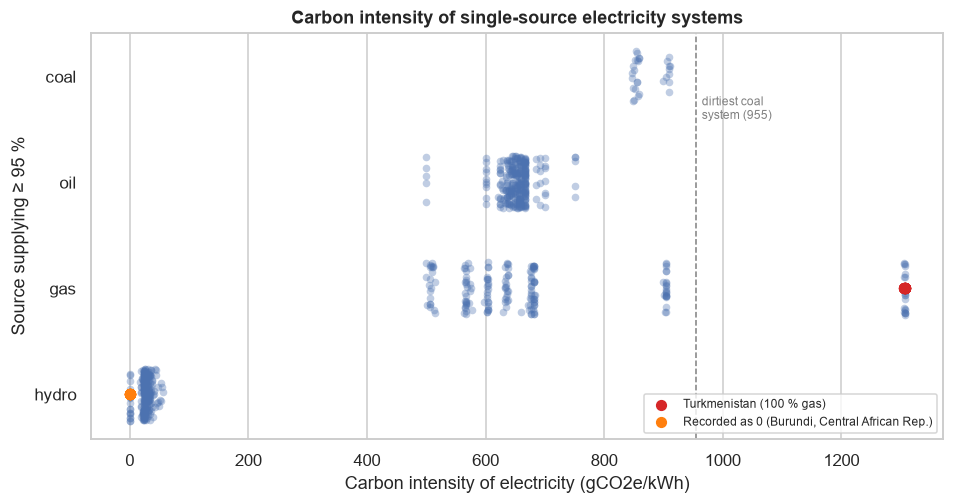

,count,min,50%,max
single_source,,,,
coal,29.000,847.390,857.140,910.350
gas,190.000,498.760,637.700,"1,306.720"
hydro,256.000,0.000,25.165,56.850
oil,290.000,500.000,656.250,750.000


In [38]:
# Country-years where one source supplies at least 95 % of electricity
single = df[df[SHARE_COLS].max(axis=1) >= 95].copy()
single["single_source"] = single["dominant_source"]

fig, ax = plt.subplots(figsize=(10, 4.8))
order = ["coal", "oil", "gas", "hydro"]
sns.stripplot(data=single[single["single_source"].isin(order)], x="carbon_intensity_elec",
              y="single_source", order=order, alpha=0.35, jitter=0.25, ax=ax, color="#4C72B0")

# Highlight the suspicious values
tkm = single[single["country"] == "Turkmenistan"]
zero = single[single["carbon_intensity_elec"] == 0]
ax.scatter(tkm["carbon_intensity_elec"], [2] * len(tkm), color="#D62728", s=40, zorder=3,
           label="Turkmenistan (100 % gas)")
ax.scatter(zero["carbon_intensity_elec"], [3] * len(zero), color="#FF7F0E", s=40, zorder=3,
           label="Recorded as 0 (Burundi, Central African Rep.)")
ax.set_xlabel("Carbon intensity of electricity (gCO2e/kWh)"); ax.set_ylabel("Source supplying ≥ 95 %")
ax.set_title("Carbon intensity of single-source electricity systems")
ax.axvline(COAL_MAX, color="grey", ls="--", lw=1)
ax.text(COAL_MAX + 10, 0.4, f"dirtiest coal\nsystem ({COAL_MAX:.0f})", fontsize=8, color="grey")
ax.legend(loc="lower right", fontsize=8)
save_fig(fig, "fig06_carbon_intensity_consistency")
plt.show()

single.groupby("single_source")["carbon_intensity_elec"].describe()[["count", "min", "50%", "max"]]

Two problems stand out:

1. **Zero intensity for hydro systems (21 rows – Burundi and the Central African Republic).** Every other
   hydro-only country (Norway, Paraguay, Nepal, Zambia, …) has an intensity of about **25 gCO₂e/kWh**,
   which matches the IPCC life-cycle median for hydropower of 24 gCO₂e/kWh (Schlömer *et al.*, 2014).
   A value of exactly 0 is therefore a recording error, not a real measurement.
2. **Turkmenistan and Uzbekistan (46 rows).** Turkmenistan's electricity is 100 % natural gas and
   Uzbekistan's is about 83 % gas and 11 % hydro, yet their intensities (≈ 1,307 and ≈ 1,110 gCO₂e/kWh)
   are higher than that of the dirtiest coal-dominated system in the data (≈ 955). Gas emits roughly
   half as much CO₂ per kWh as coal, so these values are physically implausible. Turkmenistan's value is
   also identical to within 0.2 g for 23 years, which suggests a fixed estimate rather than a
   measurement. Both are treated as errors. (Bahrain, also gas-only, has a high but possible ≈ 905 and is
   kept.)

### 9.5 Contextual outliers: sudden changes within a country

In [39]:
# Largest year-on-year changes in carbon intensity within the same country
df = df.sort_values(["country", "year"]).reset_index(drop=True)
df["ci_change"] = df.groupby("country")["carbon_intensity_elec"].diff()
jumps = df.loc[df["ci_change"].abs().nlargest(6).index,
               ["country", "year", "carbon_intensity_elec", "ci_change", "electricity_generation"]]
df = df.drop(columns="ci_change")
jumps

,country,year,carbon_intensity_elec,ci_change,electricity_generation
3064,Sierra Leone,2010,71.430,-428.570,0.140
2011,Lithuania,2010,368.000,263.490,5.000
2944,Sao Tome and Principe,2005,750.000,250.000,0.040
964,Djibouti,2021,450.000,-242.310,0.200
2283,Montenegro,2011,566.040,227.730,2.650
1931,Lebanon,2022,379.860,-219.750,4.370


The largest jumps occur mostly in **small power systems** (well under 1 TWh), where a single new plant
changes the whole mix — e.g. Sierra Leone's drop in 2010 follows the opening of the Bumbuna hydro dam,
and Lithuania's rise in 2010 follows the closure of the Ignalina nuclear plant at the end of 2009.
These are **real events**, so they are kept; they are a reminder that small countries have volatile
indicators.

### 9.6 Treatment

**Errors → corrected.** Each erroneous value is treated as missing and re-estimated from countries with
a **similar electricity mix**: the median carbon intensity of the 10 nearest country-years (Euclidean
distance on the eight source shares, plus any rows tied with the 10th) among rows that passed all
checks. Because carbon intensity is
driven by the mix, this gives a realistic value for each case (a hydro-only system gets the intensity of
other hydro-only systems, a gas-only system that of other gas-only systems). Power-sector emissions are
then recomputed from identity (b) so each row stays consistent.

In [40]:
from sklearn.neighbors import NearestNeighbors

# Rows that failed check (e) or (f)
is_error = (df["carbon_intensity_elec"] <= 0) | (
    (df["carbon_intensity_elec"] > COAL_MAX) & (df["coal_share_elec"] < 50))
reference = df[~is_error]

# Find the 10 most similar electricity mixes among the valid rows. Many mixes are identical
# (e.g. 100 % gas), so every row tied with the 10th neighbour is included as well; otherwise the
# choice among tied rows would be arbitrary.
X_err = df.loc[is_error, SHARE_COLS].to_numpy()
ref_ci = reference["carbon_intensity_elec"].to_numpy()
nn = NearestNeighbors(n_neighbors=10).fit(reference[SHARE_COLS].to_numpy())
dist, _ = nn.kneighbors(X_err)
estimates, n_used = [], []
for x, r in zip(X_err, dist[:, -1] + 1e-6):
    idx = nn.radius_neighbors([x], radius=r, return_distance=False)[0]
    estimates.append(np.median(ref_ci[idx]))
    n_used.append(len(idx))
estimates = np.array(estimates)

corrections = df.loc[is_error, ["country", "year", "carbon_intensity_elec"]].rename(
    columns={"carbon_intensity_elec": "old_intensity"})
corrections["new_intensity"] = estimates
corrections["neighbours_used"] = n_used
df.loc[is_error, "carbon_intensity_elec"] = estimates

# Recompute power-sector emissions for the corrected rows (identity b)
df.loc[is_error, "greenhouse_gas_emissions"] = (df.loc[is_error, "carbon_intensity_elec"]
                                                * df.loc[is_error, "electricity_generation"] / 1000)

print(f"Values corrected: {len(corrections)} rows in {corrections['country'].nunique()} countries\n")
corrections.groupby("country").agg(rows=("year", "size"), old_mean=("old_intensity", "mean"),
                                   new_mean=("new_intensity", "mean"),
                                   neighbours=("neighbours_used", "median")).round(1)

Values corrected: 67 rows in 4 countries



,rows,old_mean,new_mean,neighbours
country,,,,
Burundi,11,0.000,25.400,63.000
Central African Republic,10,0.000,23.800,63.000
Turkmenistan,23,"1,306.500",676.800,33.000
Uzbekistan,23,"1,097.100",599.800,10.000


**Genuine extremes → kept, but transformed.** Removing Iceland, Qatar or China would delete exactly the
cases that make the data interesting. Instead:
* the six skewed size variables get a **base-10 log-transformed copy** (`log_…`) for the EDA plots and for PCA,
  so that very large countries do not dominate the variance;
* `net_elec_imports_share_demand` has extreme tails on **both** sides and negative values (so a log cannot
  be used). It is **winsorised** (capped) at its 1st and 99th percentiles in a copy,
  `net_imports_capped`, which limits the influence of Paraguay and Palestine on PCA while keeping their
  direction (big exporter / big importer).
* the **share** variables are bounded between 0 and 100 and are left unchanged.

In [41]:
# Base-10 log-transformed copies of the skewed size variables
# (re-checked here because emissions were recomputed for the corrected rows)
assert (df[SKEWED] > 0).all().all()
LOG_COLS = []
for col in SKEWED:
    new = f"log_{col}"
    df[new] = np.log10(df[col])
    LOG_COLS.append(new)

# Winsorise net imports at the 1st and 99th percentiles
lo, hi = df["net_elec_imports_share_demand"].quantile([0.01, 0.99])
df["net_imports_capped"] = df["net_elec_imports_share_demand"].clip(lower=lo, upper=hi)
n_capped = ((df["net_elec_imports_share_demand"] < lo) | (df["net_elec_imports_share_demand"] > hi)).sum()
print(f"Net imports capped to [{lo:.1f}%, {hi:.1f}%]; {n_capped} values changed")

# Skewness before and after treatment
treated = {**{c: f"log_{c}" for c in SKEWED}, "net_elec_imports_share_demand": "net_imports_capped"}
pd.DataFrame({"skew before": {k: df[k].skew() for k in treated},
              "skew after": {k: df[v].skew() for k, v in treated.items()},
              "treated column": treated}).round(2)

Net imports capped to [-163.7%, 86.5%]; 76 values changed


,skew before,skew after,treated column
population,7.800,-0.130,log_population
gdp_per_capita,2.370,-0.260,log_gdp_per_capita
energy_per_capita,2.600,-0.480,log_energy_per_capita
electricity_demand_per_capita,4.060,-0.650,log_electricity_demand_per_capita
electricity_generation,9.230,-0.250,log_electricity_generation
greenhouse_gas_emissions,9.760,-0.160,log_greenhouse_gas_emissions
net_elec_imports_share_demand,-8.700,-1.870,net_imports_capped


The log-transformed features now have a skewness close to zero (|skew| < 1), compared with values up
to about 10 before treatment. Capping reduces the skewness of net imports from −8.7 to about −1.9; the
remaining left tail reflects the genuine group of large electricity exporters.

## 10. The final clean dataset

In [42]:
# Re-run the plausibility checks on carbon intensity after the corrections
assert (df["carbon_intensity_elec"] > 0).all()
assert not ((df["carbon_intensity_elec"] > COAL_MAX) & (df["coal_share_elec"] < 50)).any()
assert df.isna().sum().sum() == 0

FINAL_COLS = (ID_COLS + CAT_COLS + NUM_COLS + ENG_NUM_COLS + LOG_COLS + ["net_imports_capped"])
clean = df[FINAL_COLS].sort_values(["country", "year"]).reset_index(drop=True)

# Project requirement: at least 3,000 rows and 7 columns after cleaning
assert clean.shape[0] >= 3000 and clean.shape[1] >= 7

size_log.append(("Outlier treatment + engineered/transformed features", *clean.shape))
CLEAN_PATH = os.path.join(DATA_DIR, "energy_clean.csv")
clean.to_csv(CLEAN_PATH, index=False)
print(f"Saved {CLEAN_PATH}: {clean.shape[0]:,} rows x {clean.shape[1]} columns, "
      f"{clean['country'].nunique()} countries, {clean['year'].min()}-{clean['year'].max()}")

pd.DataFrame(size_log, columns=["step", "rows", "columns"])

Saved data\energy_clean.csv: 3,790 rows x 31 columns, 165 countries, 2000-2022


,step,rows,columns
0,Raw file,23377,130
1,"Countries only (drop aggregates, Antarctica)",17221,130
2,Years 2000-2022,5017,130
3,Selected features,5017,19
4,Drop 54 countries without any GDP value,3790,19
5,Outlier treatment + engineered/transformed fea...,3790,31


In [43]:
# Data dictionary of the final dataset: role, type and range of every column
def role(c):
    if c in ID_COLS: return "identifier"
    if c in CAT_COLS: return "categorical (engineered)"
    if c in ENG_NUM_COLS: return "numeric (engineered)"
    if c in LOG_COLS or c == "net_imports_capped": return "numeric (transformed copy)"
    return "numeric (original)"

pd.DataFrame({
    "role": [role(c) for c in clean.columns],
    "dtype": clean.dtypes.astype(str).values,
    "unique": clean.nunique().values,
    "min": [clean[c].min() if c not in CAT_COLS else "" for c in clean.columns],
    "max": [clean[c].max() if c not in CAT_COLS else "" for c in clean.columns],
}, index=clean.columns)

,role,dtype,unique,min,max
country,identifier,str,165,Afghanistan,Zimbabwe
iso_code,identifier,str,165,AFG,ZWE
year,identifier,int64,23,2000,2022
continent,categorical (engineered),str,6,,
dominant_source,categorical (engineered),str,7,,
income_group,categorical (engineered),category,4,,
population,numeric (original),float64,3790,"66,847.000","1,426,437,269.000"
gdp,numeric (original),float64,3790,"312,853,560.000","26,966,016,991,166.000"
energy_per_capita,numeric (original),float64,3783,101.881,"270,980.625"
electricity_demand_per_capita,numeric (original),float64,3788,8.890,"56,048.727"


### 10.1 Summary of data preparation

| Stage | What was done | Rows | Columns |
|---|---|---|---|
| Raw data | OWID energy dataset | 23,377 | 130 |
| Characterisation & selection | Countries only, 2000–2022, 16 non-redundant indicators | 5,017 | 19 |
| Missing values | Dropped 54 countries with no GDP, 429 structural zeros, 7 values interpolated | 3,790 | 19 |
| Feature engineering | GDP per capita, low-carbon share, continent, dominant source, income group | 3,790 | 24 |
| Outliers | 67 implausible carbon intensities corrected; genuine extremes kept, log-transformed or winsorised in copies | **3,790** | **31** |

The final dataset (`data/energy_clean.csv`) has **3,790 rows × 31 columns** (165 countries × 2000–2022),
no missing values, internally consistent emissions, and both raw and transformed versions of the
skewed features. It meets the project requirement of at least 3,000 rows and 7 columns after cleaning.

**Challenges faced during preparation**
* Separating the 94 regional and historical aggregates from real countries to avoid double counting.
* Different source coverage over time, which forced a choice of analysis window (2000–2022).
* Telling apart "missing" from "zero" in the electricity mix.
* Deciding which extreme values were real (Iceland, Paraguay, Qatar) and which were errors (zero
  emissions for hydro, implausible gas intensities in Turkmenistan and Uzbekistan), which needed domain knowledge, not just statistics.
* Statistical outlier rules (IQR, z-score) over-flagging skewed and zero-inflated variables.

## 11. Exploratory Data Analysis I – Variation

**Variation** is the tendency of a variable's values to change from one measurement to the next; studying
it shows the typical values, the spread, the shape of the distribution and any unusual values
(Wickham, Çetinkaya-Rundel and Grolemund, 2023). This part looks at one variable at a time, across
countries and over time, and answers the first two research questions:

* **Q1** – How has the global electricity mix changed from 2000 to 2022?
* **Q2** – How are demand, wealth and carbon intensity distributed across countries, and which countries
  are unusual?

All analysis from here on uses the clean dataset produced in Part 4.

In [44]:
# Work on a copy of the final clean dataset
eda = clean.copy()
eda["income_group"] = pd.Categorical(eda["income_group"], categories=INCOME_LEVELS, ordered=True)

# One fixed colour per energy source, reused in every chart of the EDA
SOURCE_LABELS = {"coal_share_elec": "coal", "oil_share_elec": "oil", "gas_share_elec": "gas",
                 "nuclear_share_elec": "nuclear", "hydro_share_elec": "hydro",
                 "other_renewables_share_elec": "bioenergy & other",
                 "wind_share_elec": "wind", "solar_share_elec": "solar"}
SOURCE_COLORS = {"coal": "#3B3B3B", "oil": "#8C6D31", "gas": "#E6550D", "nuclear": "#9467BD",
                 "hydro": "#1F77B4", "bioenergy & other": "#2CA02C", "wind": "#17BECF",
                 "solar": "#F2B701"}
print(f"{len(eda):,} rows | {eda['country'].nunique()} countries | {eda['year'].min()}-{eda['year'].max()}")

3,790 rows | 165 countries | 2000-2022


### 11.1 Summary of variation for the key numeric features
Besides the mean and median, the table reports the **coefficient of variation** (CV = standard deviation /
mean, a unit-free measure of spread), **skewness** (asymmetry) and **excess kurtosis** (how heavy the
tails are compared with a normal distribution, for which it is 0).

In [45]:
KEY_NUM = ["carbon_intensity_elec", "low_carbon_share_elec", "gdp_per_capita", "log_gdp_per_capita",
           "electricity_demand_per_capita", "log_electricity_demand_per_capita",
           "energy_per_capita", "population", "coal_share_elec", "gas_share_elec",
           "hydro_share_elec", "wind_share_elec", "solar_share_elec"]

variation = pd.DataFrame({
    "mean": eda[KEY_NUM].mean(),
    "median": eda[KEY_NUM].median(),
    "std": eda[KEY_NUM].std(),
    "IQR": eda[KEY_NUM].quantile(0.75) - eda[KEY_NUM].quantile(0.25),
    "CV": eda[KEY_NUM].std() / eda[KEY_NUM].mean(),
    "skew": eda[KEY_NUM].skew(),
    "kurtosis": eda[KEY_NUM].kurt(),
    "min": eda[KEY_NUM].min(),
    "max": eda[KEY_NUM].max(),
})
variation.round(2)

,mean,median,std,IQR,CV,skew,kurtosis,min,max
carbon_intensity_elec,442.180,492.000,239.570,401.470,0.540,-0.290,-1.020,17.240,954.600
low_carbon_share_elec,39.150,32.980,34.050,59.610,0.870,0.450,-1.170,0.000,100.000
gdp_per_capita,"16,369.640","10,079.780","18,021.870","20,229.020",1.100,2.370,9.940,421.560,"163,531.400"
log_gdp_per_capita,3.940,4.000,0.530,0.840,0.130,-0.260,-0.860,2.620,5.210
electricity_demand_per_capita,"3,886.050","2,056.880","5,569.080","4,794.060",1.430,4.060,26.730,8.890,"56,048.730"
log_electricity_demand_per_capita,3.150,3.310,0.750,1.030,0.240,-0.650,-0.330,0.950,4.750
energy_per_capita,"26,134.370","12,476.090","35,984.330","31,484.890",1.380,2.600,8.190,101.880,"270,980.620"
population,"42,642,494.460","10,063,070.500","147,915,410.980","25,455,679.000",3.470,7.800,64.390,"66,847.000","1,426,437,269.000"
coal_share_elec,14.130,0.000,23.610,19.330,1.670,1.780,2.280,0.000,100.000
gas_share_elec,22.780,7.940,30.150,37.160,1.320,1.290,0.450,0.000,100.000


* **Carbon intensity** has a CV of about 0.55 and almost no skew, but a *negative* kurtosis (≈ −1):
  its distribution is flatter than a normal curve, a first sign that it may contain more than one group.
* **Population, demand and GDP per capita** vary enormously (CV well above 1 on the raw scale). On the
  log scale their skew falls close to 0, as expected after Part 4.
* **Wind and solar shares** have medians near 0 but maxima above 35 %: a few countries are far ahead of
  the rest.

### 11.2 Variation in the categorical features

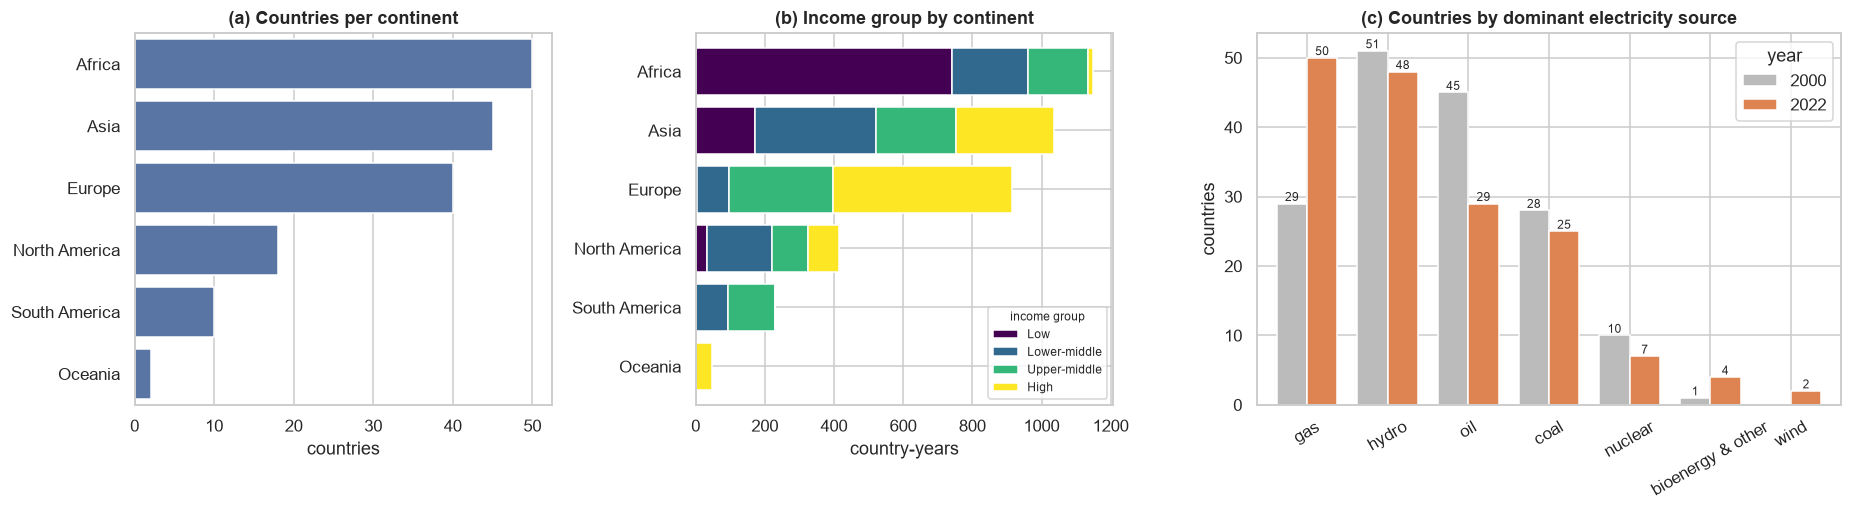

year,2000,2022
dominant_source,,
gas,29,50
hydro,51,48
oil,45,29
coal,28,25
nuclear,10,7
bioenergy & other,1,4
wind,0,2


In [46]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1, 1, 1.4]})

# (a) Countries per continent
cont = eda.groupby("continent")["country"].nunique().sort_values(ascending=False)
sns.barplot(x=cont.values, y=cont.index, ax=axes[0], color="#4C72B0")
axes[0].set_title("(a) Countries per continent"); axes[0].set_xlabel("countries"); axes[0].set_ylabel("")

# (b) Income group by continent (rows = country-years)
ct = pd.crosstab(eda["continent"], eda["income_group"]).loc[cont.index]
ct.plot(kind="barh", stacked=True, ax=axes[1], colormap="viridis", width=0.8)
axes[1].invert_yaxis()
axes[1].set_title("(b) Income group by continent"); axes[1].set_xlabel("country-years"); axes[1].set_ylabel("")
axes[1].legend(title="income group", fontsize=8, title_fontsize=8)

# (c) Number of countries by dominant source, 2000 versus 2022
dom = (eda[eda["year"].isin([2000, 2022])]
       .groupby(["year", "dominant_source"]).size().unstack(0, fill_value=0)
       .sort_values(2022, ascending=False))
dom.plot(kind="bar", ax=axes[2], color=["#BBBBBB", "#DD8452"], width=0.75)
axes[2].set_title("(c) Countries by dominant electricity source")
axes[2].set_xlabel(""); axes[2].set_ylabel("countries"); axes[2].tick_params(axis="x", rotation=30)
for p in axes[2].patches:
    if p.get_height() > 0:
        axes[2].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                         ha="center", va="bottom", fontsize=8)
fig.tight_layout()
save_fig(fig, "fig07_categorical_variation")
plt.show()

dom

* **Continents:** Africa (50 countries) and Asia (45) contribute the most rows; Oceania only two.
* **Income:** the income groups are strongly tied to geography. Most African country-years fall in the
  *Low* group, most European ones in *High*; every Oceania row is *High*. Continent and income will
  therefore partly carry the same information — a point to remember when interpreting both.
* **Dominant source:** between 2000 and 2022 the number of countries whose largest source is **gas** rose
  from 29 to 50, while **oil** fell from 45 to 29. Hydro stays the most common dominant source, and in 2022
  **wind** became the largest source in two countries for the first time.

### 11.3 Shape of the distributions

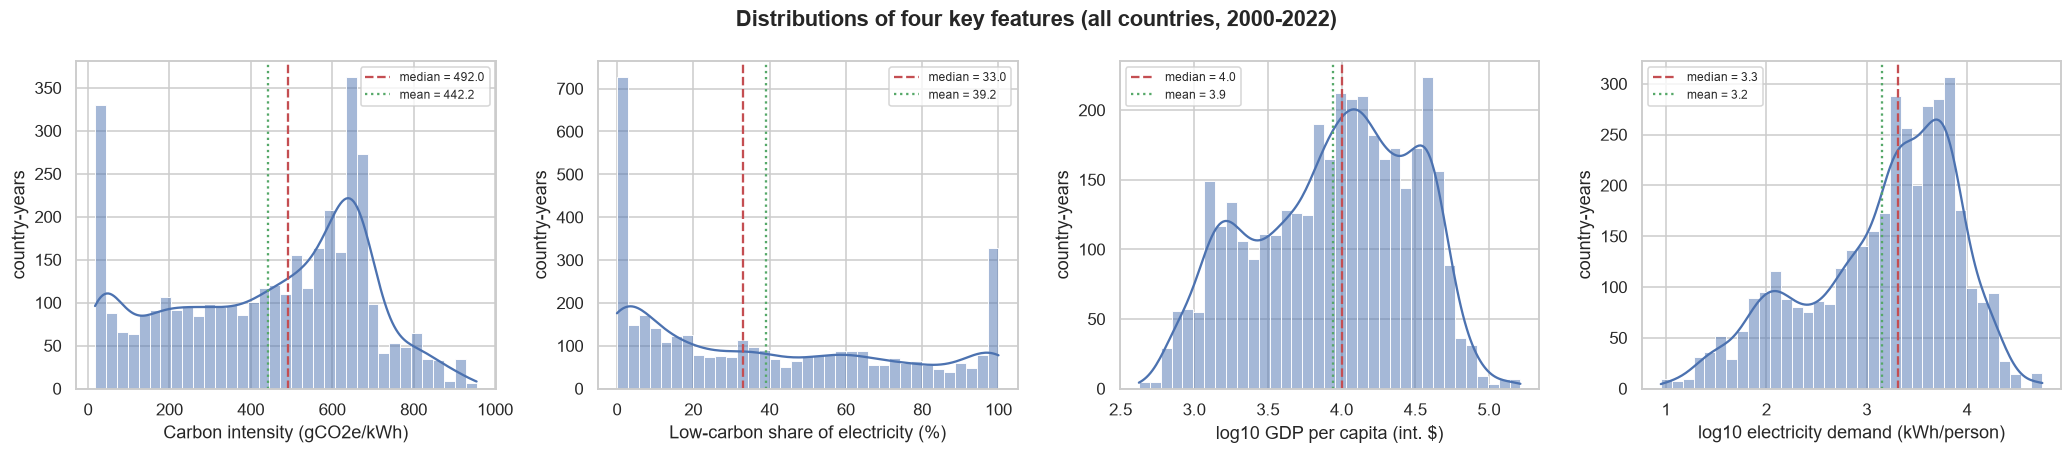

In [47]:
DIST = [("carbon_intensity_elec", "Carbon intensity (gCO2e/kWh)"),
        ("low_carbon_share_elec", "Low-carbon share of electricity (%)"),
        ("log_gdp_per_capita", "log10 GDP per capita (int. $)"),
        ("log_electricity_demand_per_capita", "log10 electricity demand (kWh/person)")]

fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
for ax, (col, label) in zip(axes, DIST):
    sns.histplot(eda[col], bins=35, kde=True, ax=ax, color="#4C72B0", edgecolor="white")
    ax.axvline(eda[col].median(), color="#C44E52", ls="--", lw=1.5, label=f"median = {eda[col].median():.1f}")
    ax.axvline(eda[col].mean(), color="#55A868", ls=":", lw=1.5, label=f"mean = {eda[col].mean():.1f}")
    ax.set_xlabel(label); ax.set_ylabel("country-years"); ax.legend(fontsize=8)
fig.suptitle("Distributions of four key features (all countries, 2000-2022)", fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig08_distributions")
plt.show()

In [48]:
# How many country-years sit at the two ends of the low-carbon share?
lc = eda["low_carbon_share_elec"]
print(f"Low-carbon share < 10 %  : {(lc < 10).mean() * 100:.1f}% of country-years")
print(f"Low-carbon share > 90 %  : {(lc > 90).mean() * 100:.1f}% of country-years")
print(f"Between 40 % and 60 %    : {lc.between(40, 60).mean() * 100:.1f}% of country-years")

# Carbon intensity of hydro-dominated systems versus all others
hydro_dom = eda["dominant_source"] == "hydro"
print(f"\nMedian carbon intensity - hydro-dominated: {eda.loc[hydro_dom, 'carbon_intensity_elec'].median():.0f}"
      f" | others: {eda.loc[~hydro_dom, 'carbon_intensity_elec'].median():.0f} gCO2e/kWh")

Low-carbon share < 10 %  : 29.8% of country-years
Low-carbon share > 90 %  : 12.8% of country-years
Between 40 % and 60 %    : 13.3% of country-years

Median carbon intensity - hydro-dominated: 151 | others: 597 gCO2e/kWh


**What the distributions show**
* **Carbon intensity is bimodal.** A sharp peak lies close to 25 gCO₂e/kWh (hydro-dominated systems)
  and the main peak around 600–700 gCO₂e/kWh (fossil-based systems), with a long plateau of mixed systems
  in between. The mean (≈ 442) and median (≈ 492) both fall between the two peaks and describe neither
  group well: the median intensity of hydro-dominated country-years is ≈ 151 against ≈ 597 for all
  others. This is a case where a single average is misleading.
* **The low-carbon share is U-shaped.** About 30 % of country-years generate less than 10 % of their
  electricity from low-carbon sources and about 13 % generate more than 90 %, while far fewer sit in the
  middle. Countries tend to be either "fossil systems" or "clean systems", with relatively few in between.
* **GDP per capita and demand** are roughly symmetric on the log scale, but both show **two peaks**.
  GDP per capita peaks around 10^3.2 ≈ \$1,600 and 10^4.6 ≈ \$40,000 per person, echoing the gap between
  low- and high-income economies. Demand has its main peak around 10^3.7 ≈ 5,000 kWh per person and a
  smaller one around 10^2 = 100 kWh, made up of very poor countries with little access to electricity.

### 11.4 Q1 – How has the global electricity mix changed?
A simple average of country shares would give Tuvalu-sized and China-sized systems the same weight. The
**global** mix is therefore computed by weighting each country by its generation (TWh):
`global share = Σ (share × generation) / Σ generation`.

In [49]:
# Electricity generated by each source (TWh) = share x total generation / 100, summed over countries
twh = eda[list(SOURCE_LABELS)].mul(eda["electricity_generation"], axis=0) / 100
twh["year"] = eda["year"]
twh_year = twh.groupby("year").sum().rename(columns=SOURCE_LABELS)
global_mix = twh_year.div(twh_year.sum(axis=1), axis=0) * 100

# Unweighted mean: what the electricity mix of a *typical country* looks like
country_mix = eda.groupby("year")[list(SOURCE_LABELS)].mean().rename(columns=SOURCE_LABELS)

# How much of the world's electricity do our 165 countries cover? (World row of the raw data)
world = raw[raw["country"] == "World"].set_index("year")
coverage_share = twh_year.sum(axis=1) / world["electricity_generation"].reindex(twh_year.index)
print(f"Our 165 countries generate {coverage_share.min() * 100:.1f}-{coverage_share.max() * 100:.1f}% "
      f"of the world's electricity in every year.\n")

pd.DataFrame({"global 2000 (%)": global_mix.loc[2000], "global 2022 (%)": global_mix.loc[2022],
              "change (pp)": global_mix.loc[2022] - global_mix.loc[2000],
              "typical country 2000 (%)": country_mix.loc[2000],
              "typical country 2022 (%)": country_mix.loc[2022]}).round(1)

Our 165 countries generate 99.7-99.8% of the world's electricity in every year.



,global 2000 (%),global 2022 (%),change (pp),typical country 2000 (%),typical country 2022 (%)
coal,38.100,35.500,-2.600,14.100,12.300
oil,8.600,3.000,-5.600,29.300,17.700
gas,18.000,23.000,5.000,17.900,25.500
nuclear,16.700,9.200,-7.500,5.200,4.400
hydro,17.200,14.900,-2.300,31.300,27.100
bioenergy & other,1.300,2.600,1.300,2.000,3.900
wind,0.200,7.300,7.100,0.200,4.800
solar,0.000,4.600,4.600,0.000,4.300


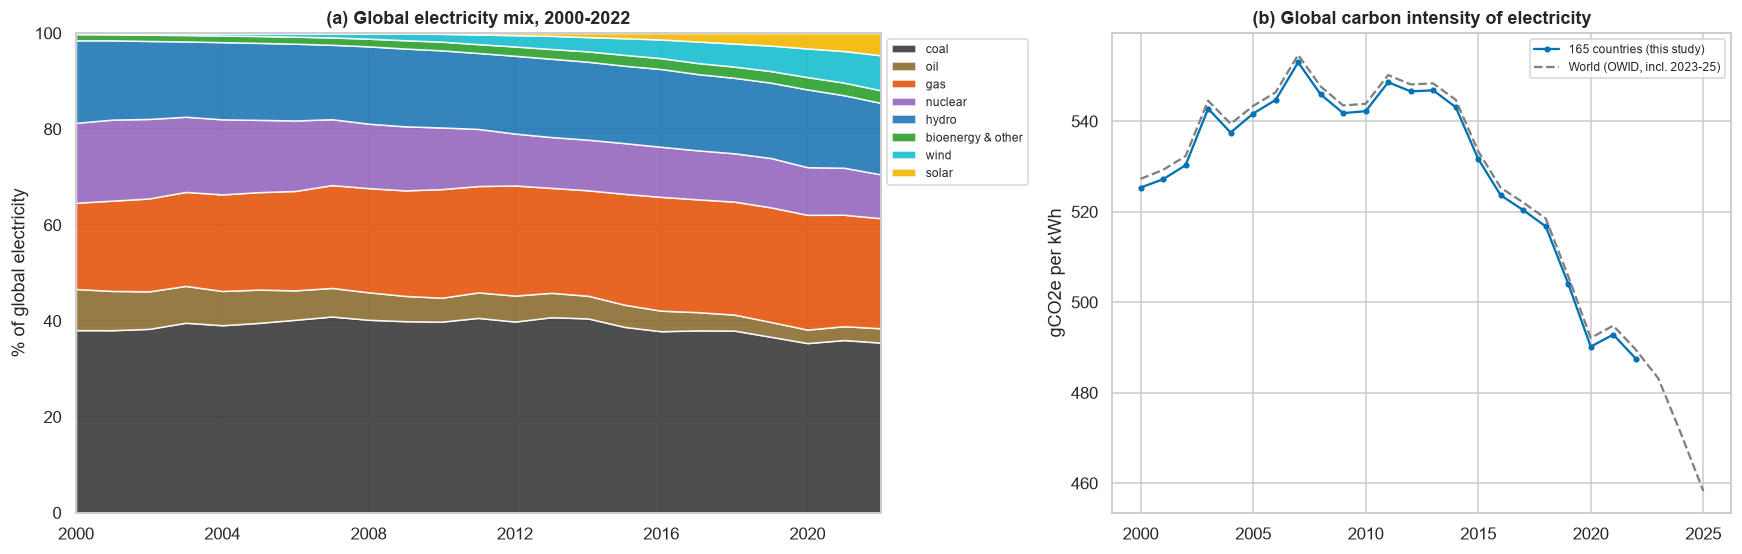

Weighted carbon intensity: 525 (2000) -> 488 (2022) gCO2e/kWh (-7.2%)
World series 2025: 458 gCO2e/kWh


In [50]:
ORDER = ["coal", "oil", "gas", "nuclear", "hydro", "bioenergy & other", "wind", "solar"]

fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw={"width_ratios": [1.3, 1]})

# (a) Stacked area chart of the generation-weighted global mix
axes[0].stackplot(global_mix.index, [global_mix[s] for s in ORDER], labels=ORDER,
                  colors=[SOURCE_COLORS[s] for s in ORDER], alpha=0.9)
axes[0].set_xlim(2000, 2022); axes[0].set_ylim(0, 100)
axes[0].set_xticks(range(2000, 2023, 4))
axes[0].set_ylabel("% of global electricity"); axes[0].set_title("(a) Global electricity mix, 2000-2022")
axes[0].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8)

# (b) Global carbon intensity: our panel (weighted) and OWID's World series up to 2025
panel_ci = (eda["carbon_intensity_elec"] * eda["electricity_generation"]).groupby(eda["year"]).sum() \
           / eda.groupby("year")["electricity_generation"].sum()
axes[1].plot(panel_ci.index, panel_ci, marker="o", ms=3, label="165 countries (this study)")
world_ci = world.loc[2000:, "carbon_intensity_elec"]
axes[1].plot(world_ci.index, world_ci, ls="--", color="grey", label="World (OWID, incl. 2023-25)")
axes[1].set_ylabel("gCO2e per kWh"); axes[1].set_title("(b) Global carbon intensity of electricity")
axes[1].legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "fig09_global_mix")
plt.show()

print(f"Weighted carbon intensity: {panel_ci.loc[2000]:.0f} (2000) -> {panel_ci.loc[2022]:.0f} (2022) gCO2e/kWh "
      f"({(panel_ci.loc[2022] / panel_ci.loc[2000] - 1) * 100:.1f}%)")
print(f"World series 2025: {world_ci.loc[2025]:.0f} gCO2e/kWh")

**Answer to Q1**
* The 165 countries cover more than 99 % of world electricity generation, so the weighted mix is a good
  picture of the global system.
* **Wind and solar** grew from almost nothing (0.2 % together in 2000) to about **12 %** in 2022 — the
  largest change of any source.
* **Coal remains the largest single source** (38 % → 35.5 %); its share fell only slightly because total
  demand grew so much. **Gas** gained about 5 percentage points; **oil** halved.
* **Nuclear** lost almost half of its share (16.7 % → 9.2 %), so much of the growth in renewables only
  replaced the decline of another low-carbon source. The total low-carbon share therefore rose only from
  about 35 % to 39 %.
* As a result, global carbon intensity fell by only **about 7 %** in 22 years (≈ 525 → 488 gCO₂e/kWh),
  and the path was not steady: it **rose** to a peak of about 553 in 2007, when coal-fired generation was
  expanding fastest, stayed high until 2014, and has fallen since. OWID's World series shows the decline
  continuing after 2022 (≈ 458 in 2025) as solar expands. The panel line and the World line almost
  overlap, confirming that dropping the 54 countries without GDP does not bias the global picture.
* The **typical country** looks very different from the global total: oil and hydro dominate the
  unweighted averages, because many small countries burn oil for power or rely on a single dam, while the
  global total is driven by large coal-based systems (China, India, the USA).

### 11.5 Q2 – How does carbon intensity vary across countries and over time?

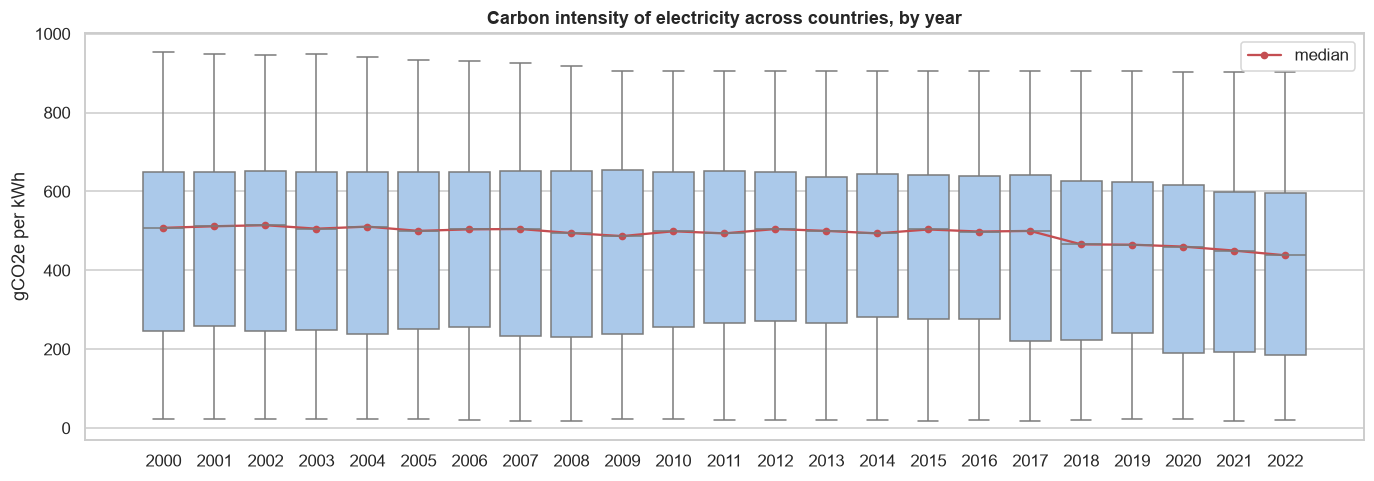

,median,IQR,std
year,,,
2000,508.000,405.000,253.000
2005,500.000,399.000,246.000
2010,499.000,394.000,239.000
2015,504.000,366.000,233.000
2022,438.000,412.000,230.000


In [51]:
fig, ax = plt.subplots(figsize=(15, 4.8))
sns.boxplot(data=eda, x="year", y="carbon_intensity_elec", ax=ax, color="#A1C9F4",
            flierprops={"marker": ".", "alpha": 0.5})
medians = eda.groupby("year")["carbon_intensity_elec"].median()
ax.plot(range(len(medians)), medians.values, color="#C44E52", marker="o", ms=4, label="median")
ax.set_xlabel(""); ax.set_ylabel("gCO2e per kWh")
ax.set_title("Carbon intensity of electricity across countries, by year")
ax.legend()
save_fig(fig, "fig10_carbon_intensity_by_year")
plt.show()

spread = eda.groupby("year")["carbon_intensity_elec"].agg(
    median="median", IQR=lambda s: s.quantile(0.75) - s.quantile(0.25), std="std")
spread.loc[[2000, 2005, 2010, 2015, 2022]].round(0)

The **median** country's carbon intensity fell from about 508 to 438 gCO₂e/kWh (−14 %), a faster fall
than the generation-weighted global value (−7 %): smaller countries decarbonised faster than the large
coal-based systems. However, the **spread did not narrow** — the inter-quartile range stays around
400 gCO₂e/kWh throughout. Countries are not converging: some are cleaning up quickly while others are
standing still or getting dirtier.

### 11.6 Q2 – Which countries are unusual?

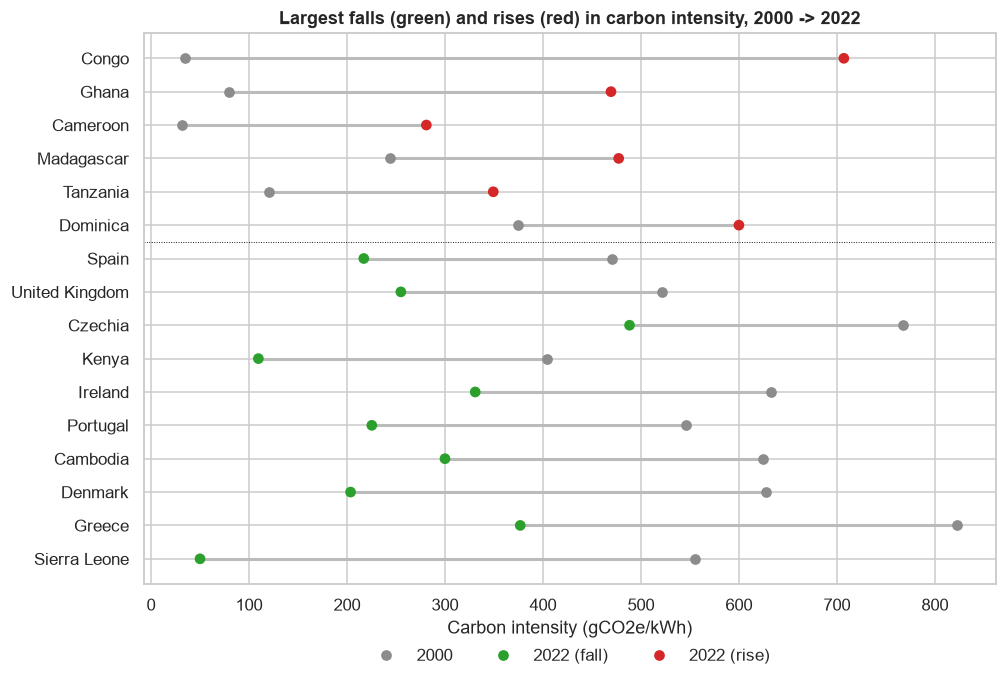

year,2000,2022,change
country,,,
Sierra Leone,556.000,50.000,-506.000
Greece,823.000,377.000,-446.000
Denmark,628.000,204.000,-424.000
Cambodia,625.000,300.000,-325.000
Portugal,546.000,225.000,-321.000
Ireland,633.000,331.000,-302.000
Kenya,404.000,110.000,-294.000
Czechia,767.000,488.000,-279.000
United Kingdom,522.000,255.000,-267.000


In [52]:
# Change in carbon intensity for each country between 2000 and 2022
ci_wide = eda.pivot(index="country", columns="year", values="carbon_intensity_elec")[[2000, 2022]].dropna()
ci_wide["change"] = ci_wide[2022] - ci_wide[2000]
movers = pd.concat([ci_wide.nsmallest(10, "change"), ci_wide.nlargest(6, "change").iloc[::-1]])

fig, ax = plt.subplots(figsize=(10, 6.5))
y = np.arange(len(movers))
ax.hlines(y, movers[2000], movers[2022], color="#BBBBBB", lw=2)
ax.scatter(movers[2000], y, color="#8C8C8C", label="2000", zorder=3)
ax.scatter(movers[2022], y, color=np.where(movers["change"] < 0, "#2CA02C", "#D62728"),
           label="2022", zorder=3)
ax.set_yticks(y); ax.set_yticklabels(movers.index)
ax.axhline(9.5, color="black", lw=0.6, ls=":")
ax.set_xlabel("Carbon intensity (gCO2e/kWh)")
ax.set_title("Largest falls (green) and rises (red) in carbon intensity, 2000 -> 2022")
from matplotlib.lines import Line2D
handles = [Line2D([], [], marker="o", ls="", color=c, label=l)
           for c, l in [("#8C8C8C", "2000"), ("#2CA02C", "2022 (fall)"), ("#D62728", "2022 (rise)")]]
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=3, frameon=False)
save_fig(fig, "fig11_biggest_changers")
plt.show()

movers.round(0)

In [53]:
# The extremes of 2022: cleanest and most carbon-intensive electricity, and highest/lowest demand
y22 = eda[eda["year"] == 2022]
show = ["country", "continent", "dominant_source", "carbon_intensity_elec", "electricity_demand_per_capita"]
print("Cleanest electricity in 2022:")
print(y22.nsmallest(5, "carbon_intensity_elec")[show].to_string(index=False))
print("\nMost carbon-intensive electricity in 2022:")
print(y22.nlargest(5, "carbon_intensity_elec")[show].to_string(index=False))
print("\nHighest and lowest electricity demand per person in 2022:")
print(pd.concat([y22.nlargest(3, "electricity_demand_per_capita"),
                 y22.nsmallest(3, "electricity_demand_per_capita")])[show].to_string(index=False))

Cleanest electricity in 2022:
                 country     continent dominant_source  carbon_intensity_elec  electricity_demand_per_capita
                 Lesotho        Africa           hydro                 20.830                        398.056
                   Nepal          Asia           hydro                 23.360                        376.572
                Ethiopia        Africa           hydro                 23.550                        124.896
Central African Republic        Africa           hydro                 23.770                         27.462
              Costa Rica North America           hydro                 24.120                      2,306.286

Most carbon-intensive electricity in 2022:
   country continent dominant_source  carbon_intensity_elec  electricity_demand_per_capita
   Bahrain      Asia             gas                902.750                     23,287.207
  Botswana    Africa            coal                847.660                      1,786.962

**Unusual patterns found**
* **Fastest decarbonisers** fall into two groups: (1) European countries that replaced coal and oil with
  wind and solar — *Denmark*, *Greece*, *Portugal*, *Ireland*, the *UK*, *Spain*; and (2) low-income
  countries that added a large low-carbon plant to a tiny system — *Sierra Leone* and *Cambodia* (hydro),
  *Kenya* (geothermal).
* **The opposite trend:** several African countries became much **more** carbon-intensive — *Congo*
  (+673 g), *Ghana*, *Cameroon*, *Madagascar*, *Tanzania*. They used to rely almost entirely on
  hydropower and met rising demand with new gas- and oil-fired plants. This is the reverse of the
  transition seen in Europe and is easily missed in global averages.
* **Extremes in 2022:** the cleanest systems (≈ 21–24 g) are all hydro-based (*Lesotho*, *Nepal*,
  *Ethiopia*, *Costa Rica*); the dirtiest (> 810 g) are coal-based (*Botswana*, *Kazakhstan*,
  *Mongolia*) or rely on old gas and oil plants (*Bahrain*, *Libya*). Electricity demand per person
  ranges over three orders of magnitude, from tens of kWh in the poorest countries to more than
  50,000 kWh in *Iceland*.

### 11.7 Q1 – The take-off of wind and solar

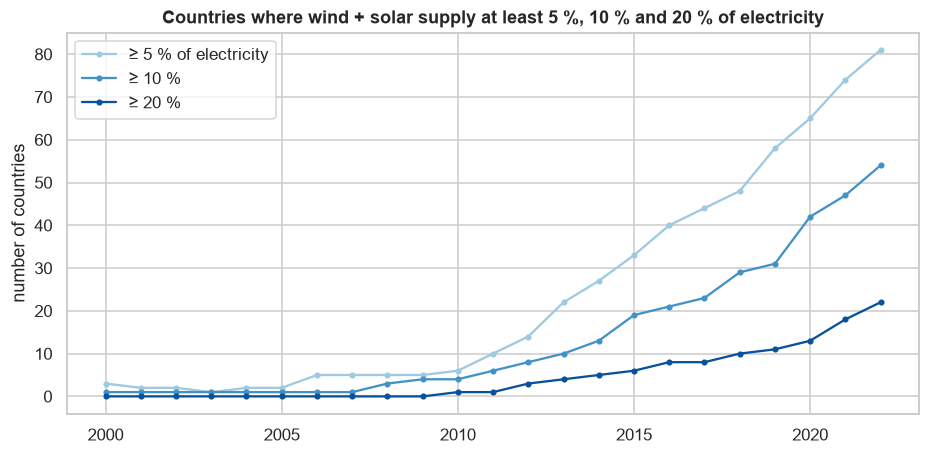

      ≥ 5 % of electricity  ≥ 10 %  ≥ 20 %
year                                      
2000                     3       1       0
2005                     2       1       0
2010                     6       4       1
2015                    33      19       6
2020                    65      42      13
2022                    81      54      22

Largest wind + solar shares in 2022:
   country  wind_share_elec  solar_share_elec  wind_solar
   Denmark           54.100             6.800      60.900
Luxembourg           25.600            23.100      48.800
 Lithuania           37.400             8.400      45.800
   Namibia            1.500            37.900      39.400
  Portugal           28.600             7.600      36.200
   Uruguay           32.200             3.400      35.500


In [54]:
ws = eda.assign(wind_solar=eda["wind_share_elec"] + eda["solar_share_elec"])
adoption = pd.DataFrame({
    "≥ 5 % of electricity": ws.groupby("year")["wind_solar"].apply(lambda s: (s >= 5).sum()),
    "≥ 10 %": ws.groupby("year")["wind_solar"].apply(lambda s: (s >= 10).sum()),
    "≥ 20 %": ws.groupby("year")["wind_solar"].apply(lambda s: (s >= 20).sum())})

fig, ax = plt.subplots(figsize=(10, 4.5))
adoption.plot(ax=ax, marker="o", ms=3, color=["#9ECAE1", "#4292C6", "#08519C"])
ax.set_ylabel("number of countries"); ax.set_xlabel("")
ax.set_title("Countries where wind + solar supply at least 5 %, 10 % and 20 % of electricity")
save_fig(fig, "fig12_wind_solar_adoption")
plt.show()

print(adoption.loc[[2000, 2005, 2010, 2015, 2020, 2022]].to_string())
print("\nLargest wind + solar shares in 2022:")
print(ws[ws["year"] == 2022].nlargest(6, "wind_solar")[["country", "wind_share_elec", "solar_share_elec",
                                                         "wind_solar"]].round(1).to_string(index=False))

The take-off of wind and solar is **very recent and non-linear**: only 3 countries got 5 % of their
electricity from wind and solar in 2000 and just 6 in 2010, but 81 did by 2022. Most of the growth
happened after 2012, which is why it barely shows in averages over the whole period. *Denmark* leads with
more than half of its electricity from wind (61 % from wind and solar together), followed by
*Luxembourg*, *Lithuania*, *Portugal* and *Uruguay*; *Namibia* stands out as a solar leader (38 %).
The number of countries above 20 % rose from 1 in 2010 to 22 in 2022.

### 11.8 Summary of the variation analysis
| Question | Finding |
|---|---|
| Q1 – global mix | Wind + solar rose from 0.2 % to ≈ 12 %, but coal is still the largest source and nuclear's share fell by nearly half; global carbon intensity fell only ≈ 7 % (2000–2022). |
| Q2 – distributions | Carbon intensity is **bimodal** (hydro vs fossil systems) and the low-carbon share is **U-shaped**; size and demand vary over orders of magnitude. |
| Q2 – unusual countries | Fast decarbonisers in Europe and in small hydro/geothermal systems; several African countries moved **away** from low-carbon power; no convergence across countries. |

Part 6 looks at how these features vary **together** (covariation) to explain these patterns.

## 12. Exploratory Data Analysis II – Covariation

**Covariation** is the tendency of two or more variables to vary together in a related way (Wickham,
Çetinkaya-Rundel and Grolemund, 2023). This part looks at pairs and groups of features to explain the
patterns found in Part 5 and to answer:

* **Q3** – Is national wealth associated with cleaner electricity?
* **Q4** – Which continents have decarbonised their electricity fastest?
* **Q5** – Do energy sources substitute for each other?

### 12.1 Correlation structure of the numeric features
**Spearman's rank correlation (ρ)** is used as the main measure because most features are skewed and
the relationships are not always linear; it only assumes a monotonic relationship and is robust to
extreme values. Pearson's r is shown next to it for the strongest pairs.

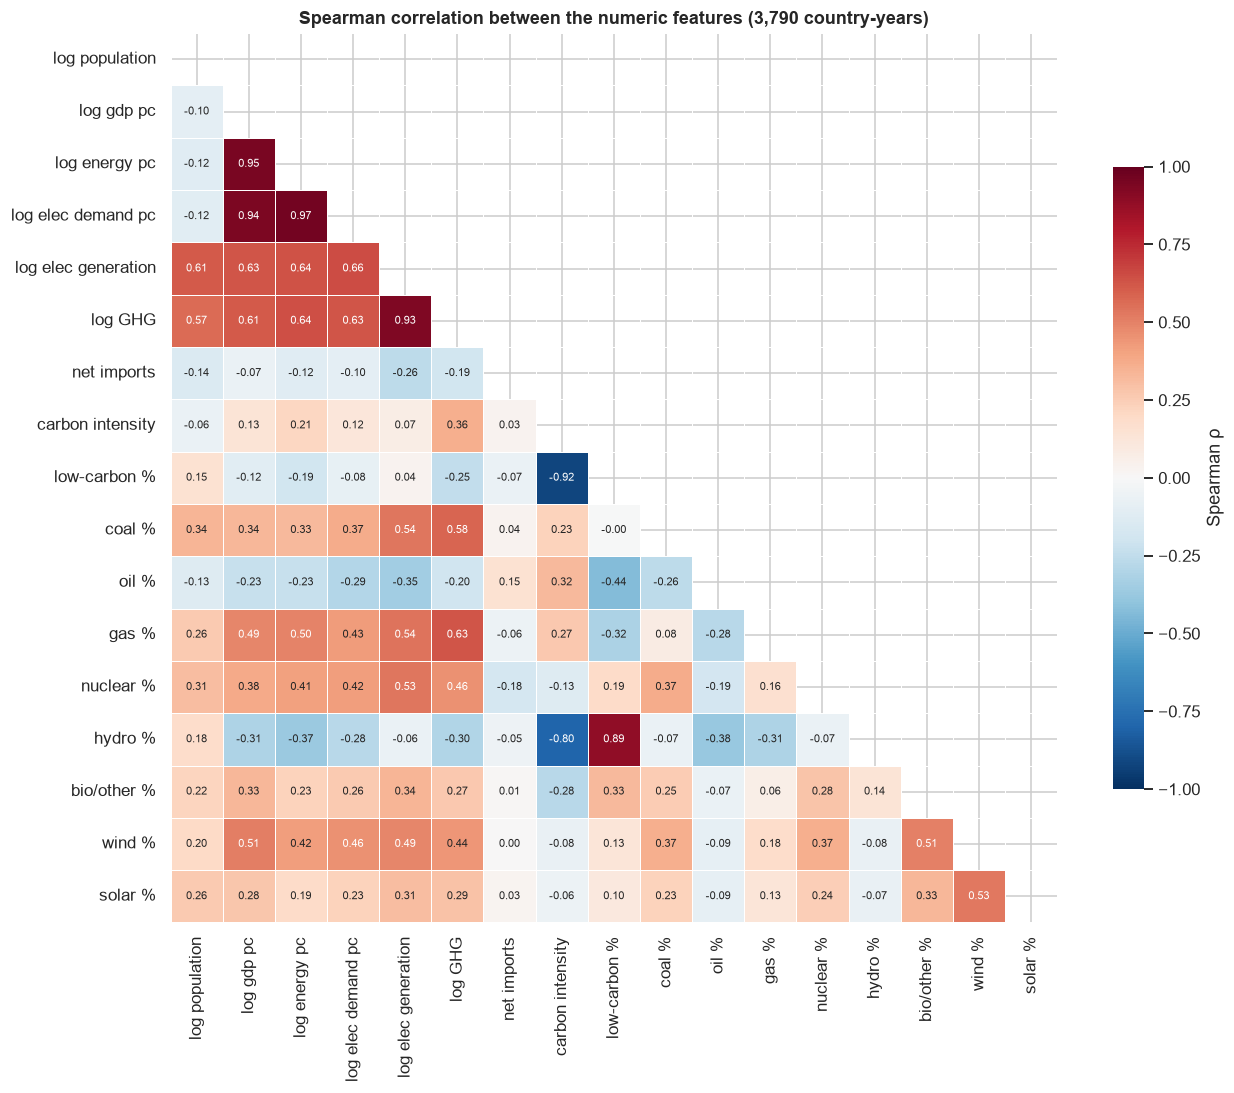

In [55]:
from scipy import stats

CORR_COLS = ["log_population", "log_gdp_per_capita", "log_energy_per_capita",
             "log_electricity_demand_per_capita", "log_electricity_generation",
             "log_greenhouse_gas_emissions", "net_imports_capped", "carbon_intensity_elec",
             "low_carbon_share_elec"] + list(SOURCE_LABELS)
SHORT = {c: c.replace("log_", "log ").replace("_share_elec", " %").replace("electricity_", "elec ")
          .replace("_per_capita", " pc").replace("greenhouse_gas_emissions", "GHG")
          .replace("other_renewables", "bio/other").replace("carbon_intensity_elec", "carbon intensity")
          .replace("net_imports_capped", "net imports").replace("low_carbon %", "low-carbon %")
          .replace("_", " ") for c in CORR_COLS}

spearman = eda[CORR_COLS].corr(method="spearman").rename(index=SHORT, columns=SHORT)
pearson = eda[CORR_COLS].corr(method="pearson").rename(index=SHORT, columns=SHORT)

fig, ax = plt.subplots(figsize=(13, 10.5))
mask = np.triu(np.ones_like(spearman, dtype=bool))          # show the lower triangle only
sns.heatmap(spearman, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=0.5, cbar_kws={"label": "Spearman ρ", "shrink": 0.7}, ax=ax)
ax.set_title("Spearman correlation between the numeric features (3,790 country-years)")
save_fig(fig, "fig13_correlation_heatmap")
plt.show()

In [56]:
# Rank all pairs by the absolute Spearman correlation and show the strongest ones
upper = np.triu(np.ones(spearman.shape, dtype=bool), k=1)
pairs = (spearman.where(upper).stack().rename("spearman").to_frame()
         .join(pearson.where(upper).stack().rename("pearson")))
pairs["abs"] = pairs["spearman"].abs()
pairs.sort_values("abs", ascending=False).drop(columns="abs").head(14).round(2)

spearman  pearson
log energy pc       log elec demand pc      0.970    0.960
log gdp pc          log energy pc           0.950    0.940
                    log elec demand pc      0.940    0.920
log elec generation log GHG                 0.930    0.930
carbon intensity    low-carbon %           -0.920   -0.950
low-carbon %        hydro %                 0.890    0.870
carbon intensity    hydro %                -0.800   -0.830
log elec demand pc  log elec generation     0.660    0.670
log energy pc       log GHG                 0.640    0.660
                    log elec generation     0.640    0.630
log elec demand pc  log GHG                 0.630    0.650
log GHG             gas %                   0.630    0.400
log gdp pc          log elec generation     0.630    0.620
                    log GHG                 0.610    0.630

**Main covariation patterns**
* **A "size" block:** total generation and power-sector emissions are very strongly correlated
  (ρ ≈ 0.93) — large power systems emit more. Population is only moderately linked to them (ρ ≈ 0.6),
  about as strongly as GDP per capita is (ρ ≈ 0.6): the size of a power system depends on **both** how
  many people live in a country and how rich they are.
* **A "development" block:** GDP per capita, energy use and electricity demand per person move together
  almost perfectly (ρ ≈ 0.94–0.97). Richer countries use far more energy per person.
* **A "cleanliness" axis:** carbon intensity is almost the mirror image of the low-carbon share
  (ρ ≈ −0.92) and is strongly linked to the hydro share (ρ ≈ −0.80).
* **Wealth and cleanliness are almost unrelated**: ρ between GDP per capita and carbon intensity is only
  about 0.13. Wealth explains *how much* electricity a country uses, but not *how clean* it is (Q3 below).
* **Shares are negatively related to one another** (e.g. oil vs hydro). Because the eight shares must sum
  to 100 %, part of this is mechanical: compositional data always produce negative correlations
  (Aitchison, 1986). Substitution is therefore studied with *changes* over time in Section 12.5.

These blocks of correlated features suggest that the data have a lower-dimensional structure, which PCA
will summarise in Part 8.

### 12.2 Q3 – Is wealth associated with cleaner electricity?

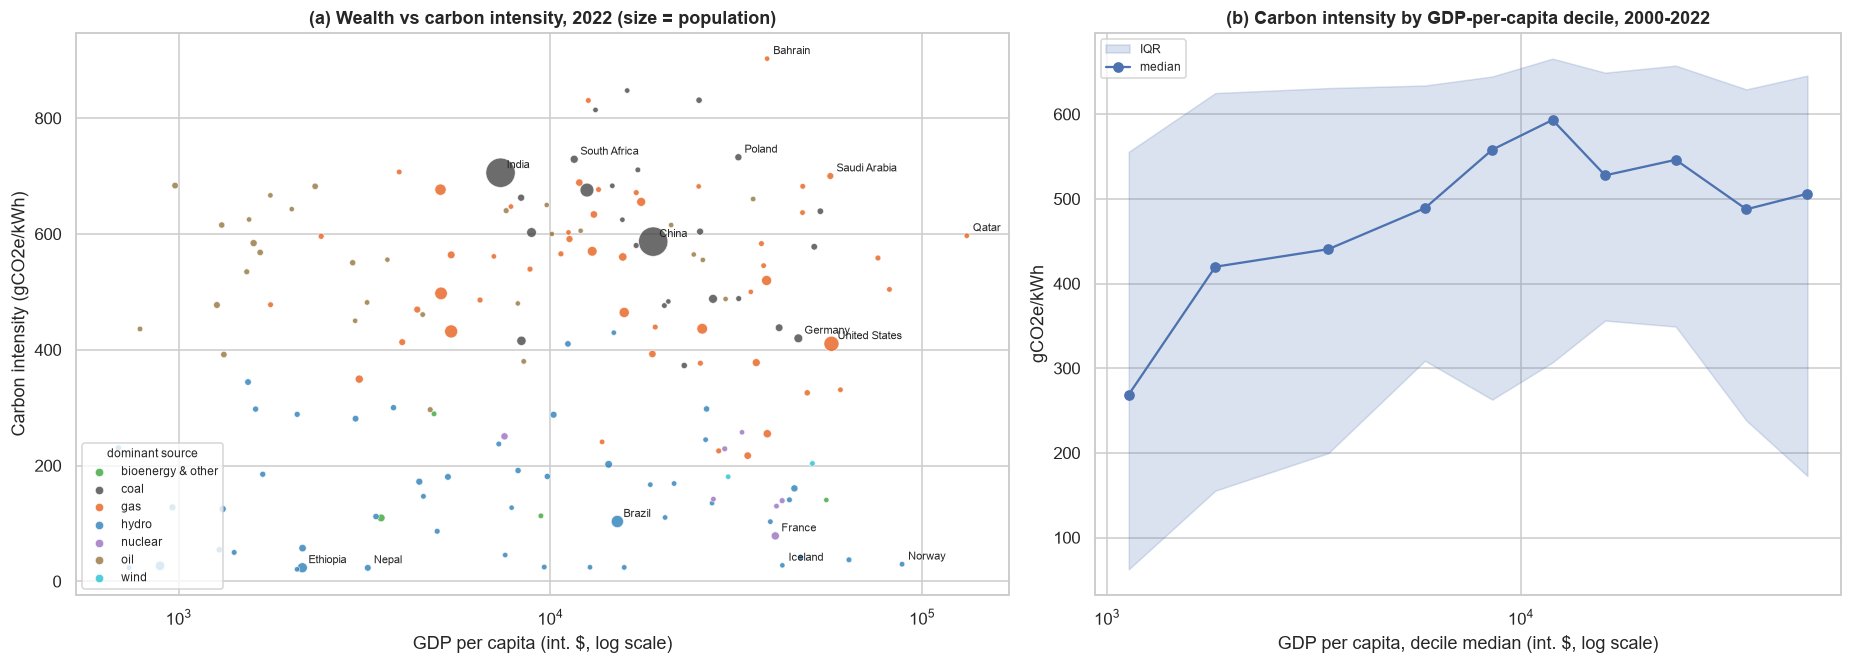

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.2), gridspec_kw={"width_ratios": [1.25, 1]})

# (a) 2022 snapshot: GDP per capita vs carbon intensity, coloured by dominant source, sized by population
y22 = eda[eda["year"] == 2022]
for src, grp in y22.groupby("dominant_source"):
    axes[0].scatter(grp["gdp_per_capita"], grp["carbon_intensity_elec"], s=grp["population"] / 4e6 + 12,
                    color=SOURCE_COLORS[src], alpha=0.75, edgecolor="white", lw=0.5, label=src)
for name in ["China", "India", "United States", "Iceland", "Norway", "Bahrain", "Saudi Arabia",
             "Ethiopia", "Nepal", "Poland", "France", "South Africa", "Brazil", "Germany", "Qatar"]:
    row = y22[y22["country"] == name]
    if len(row):
        axes[0].annotate(name, (row["gdp_per_capita"].iloc[0], row["carbon_intensity_elec"].iloc[0]),
                         fontsize=7.5, xytext=(4, 3), textcoords="offset points")
axes[0].set_xscale("log")
axes[0].set_xlabel("GDP per capita (int. $, log scale)"); axes[0].set_ylabel("Carbon intensity (gCO2e/kWh)")
axes[0].set_title("(a) Wealth vs carbon intensity, 2022 (size = population)")
leg = axes[0].legend(title="dominant source", fontsize=8, title_fontsize=8, loc="lower left")
for handle in leg.legend_handles:          # same marker size for every source in the legend
    handle.set_sizes([30])

# (b) All years: median carbon intensity within each GDP-per-capita decile, with the IQR as a band
eda["gdp_decile"] = pd.qcut(eda["gdp_per_capita"], 10, labels=False) + 1
dec = eda.groupby("gdp_decile").agg(gdp=("gdp_per_capita", "median"),
                                    ci_med=("carbon_intensity_elec", "median"),
                                    ci_q1=("carbon_intensity_elec", lambda s: s.quantile(0.25)),
                                    ci_q3=("carbon_intensity_elec", lambda s: s.quantile(0.75)))
axes[1].fill_between(dec["gdp"], dec["ci_q1"], dec["ci_q3"], alpha=0.2, color="#4C72B0", label="IQR")
axes[1].plot(dec["gdp"], dec["ci_med"], marker="o", color="#4C72B0", label="median")
axes[1].set_xscale("log")
axes[1].set_xlabel("GDP per capita, decile median (int. $, log scale)"); axes[1].set_ylabel("gCO2e/kWh")
axes[1].set_title("(b) Carbon intensity by GDP-per-capita decile, 2000-2022")
axes[1].legend(fontsize=8)
fig.tight_layout()
save_fig(fig, "fig14_wealth_vs_carbon_intensity")
plt.show()

In [58]:
# What makes up the electricity mix in each wealth decile? (mean shares, all years)
decile_mix = eda.groupby("gdp_decile")[list(SOURCE_LABELS)].mean().rename(columns=SOURCE_LABELS)
decile_mix.insert(0, "median GDP pc", dec["gdp"].round(0))
decile_mix.insert(1, "median CI", dec["ci_med"].round(0))
display(decile_mix.round(1))

# Statistical tests
rho, p = stats.spearmanr(eda["gdp_per_capita"], eda["carbon_intensity_elec"])
print(f"Spearman rho (GDP pc vs carbon intensity), all rows: {rho:.2f} (p = {p:.1e})")
by_year = {yr: stats.spearmanr(g["gdp_per_capita"], g["carbon_intensity_elec"])[0]
           for yr, g in eda.groupby("year")}
print(f"Same correlation within a single year: 2000 = {by_year[2000]:.2f}, 2010 = {by_year[2010]:.2f}, "
      f"2022 = {by_year[2022]:.2f}")

# Kruskal-Wallis test: do the four income groups have the same distribution of carbon intensity?
groups = [g["carbon_intensity_elec"].values for _, g in eda.groupby("income_group", observed=True)]
H, p_kw = stats.kruskal(*groups)
print(f"Kruskal-Wallis across income groups: H = {H:.1f}, p = {p_kw:.1e}")
print(eda.groupby("income_group", observed=True)["carbon_intensity_elec"].median().round(0).to_string())

,median GDP pc,median CI,coal,oil,gas,nuclear,hydro,bioenergy & other,wind,solar
gdp_decile,,,,,,,,,,
1,"1,129.000",269.000,4.500,40.500,0.700,0.000,53.100,0.800,0.100,0.400
2,"1,828.000",420.000,4.900,42.700,9.200,0.000,41.200,1.200,0.100,0.600
3,"3,428.000",441.000,6.100,31.300,19.600,0.200,38.500,2.900,0.900,0.500
4,"5,866.000",489.000,11.500,27.300,22.000,1.200,30.800,5.400,1.200,0.700
5,"8,531.000",558.000,17.900,23.300,19.700,3.500,29.500,4.000,0.900,1.300
6,"11,933.000",593.000,21.200,21.100,27.000,3.100,25.700,1.000,0.600,0.300
7,"15,988.000",528.000,19.100,12.500,34.800,5.200,23.800,2.500,1.600,0.400
8,"23,678.000",546.000,23.000,22.300,22.700,9.800,13.700,3.100,4.000,1.300
9,"35,082.000",488.000,17.900,10.400,33.000,16.300,13.500,4.600,2.800,1.400


Spearman rho (GDP pc vs carbon intensity), all rows: 0.13 (p = 7.5e-17)
Same correlation within a single year: 2000 = 0.16, 2010 = 0.18, 2022 = 0.05
Kruskal-Wallis across income groups: H = 159.5, p = 2.3e-34
income_group
Low            365.000
Lower-middle   495.000
Upper-middle   566.000
High           503.000


**Answer to Q3 – an inverted-U, not a straight line**
* Over the whole panel the correlation between wealth and carbon intensity is **weak and positive**
  (ρ ≈ 0.13), and within a single year it has faded to almost zero by 2022 (≈ 0.05).
* The decile plot shows why: the relationship is an **inverted U**. The **poorest** countries have the
  **cleanest** electricity (median ≈ 270 g), the **middle-income** countries (≈ \$7,000–14,000) the
  dirtiest (≈ 560–590 g), and the **richest** countries are cleaner again (≈ 490–510 g in the top two deciles). This shape
  resembles the Environmental Kuznets Curve (Grossman and Krueger, 1995).
* The **mix table explains it**. The poorest decile gets about half its power from **hydro** — it is
  "clean by default", because cheap hydro was the first source of grid electricity, not because of
  climate policy. As countries grow, they add **coal, oil and gas** faster than low-carbon capacity. Only
  in the richest deciles do **nuclear** and **wind/solar** become significant.
* The Kruskal–Wallis test confirms that carbon intensity differs between income groups (p < 0.001), but
  the spread *within* each group is much larger than the difference between them.
* **Unusual cases** stand out in panel (a): rich but carbon-intensive Gulf states (*Bahrain*,
  *Saudi Arabia*, *Qatar*) and *Poland*; poor but very clean *Ethiopia* and *Nepal*; rich and very clean
  *Iceland*, *Norway* and *France* (nuclear).

### 12.3 Wealth and electricity demand

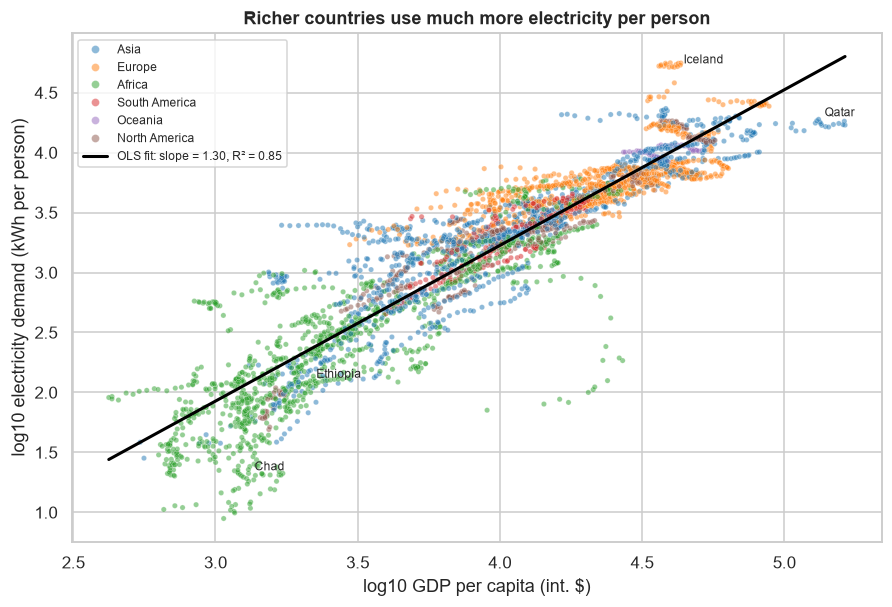

Elasticity (log-log slope): 1.30 -> a country 10x richer uses about 20x more electricity per person


In [59]:
fit = stats.linregress(eda["log_gdp_per_capita"], eda["log_electricity_demand_per_capita"])

fig, ax = plt.subplots(figsize=(9.5, 6))
sns.scatterplot(data=eda, x="log_gdp_per_capita", y="log_electricity_demand_per_capita", hue="continent",
                s=12, alpha=0.5, ax=ax, palette="tab10")
xs = np.linspace(eda["log_gdp_per_capita"].min(), eda["log_gdp_per_capita"].max(), 50)
ax.plot(xs, fit.intercept + fit.slope * xs, color="black", lw=2,
        label=f"OLS fit: slope = {fit.slope:.2f}, R² = {fit.rvalue ** 2:.2f}")
for name in ["Iceland", "Qatar", "Chad", "Ethiopia"]:
    row = eda[(eda["country"] == name) & (eda["year"] == 2022)]
    ax.annotate(name, (row["log_gdp_per_capita"].iloc[0], row["log_electricity_demand_per_capita"].iloc[0]),
                fontsize=8, xytext=(4, 2), textcoords="offset points")
ax.set_xlabel("log10 GDP per capita (int. $)"); ax.set_ylabel("log10 electricity demand (kWh per person)")
ax.set_title("Richer countries use much more electricity per person")
ax.legend(fontsize=8, markerscale=1.5)
save_fig(fig, "fig15_wealth_vs_demand")
plt.show()

print(f"Elasticity (log-log slope): {fit.slope:.2f} -> a country 10x richer uses about "
      f"{10 ** fit.slope:.0f}x more electricity per person")

In contrast with carbon intensity, **demand is tightly linked to wealth** (R² ≈ 0.85 on the log scale).
The slope of ≈ 1.3 is an *elasticity*: a country that is ten times richer uses about twenty times more
electricity per person. *Iceland* lies far above the line (aluminium smelting), while some oil-rich
countries such as *Chad* lie far below it — GDP from resource extraction does not translate into
electrification. Together with Q3, this means that **as countries grow, the volume of electricity rises
predictably, but whether that electricity is clean depends on the choice of sources**.

### 12.4 Q4 – Which continents decarbonised fastest?

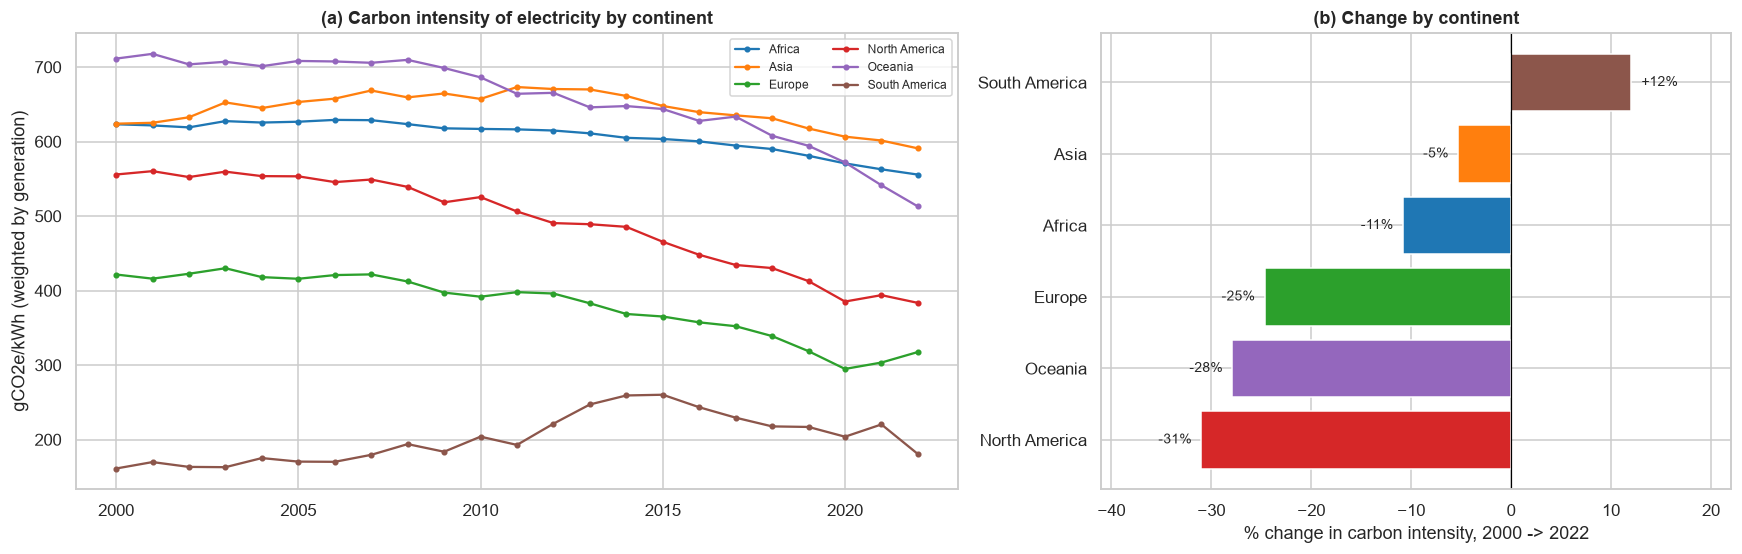

,CI 2000,CI 2022,% change,median_change,share_improved
continent,,,,,
North America,555.800,383.500,-31.000,-38.600,61.100
Oceania,711.400,512.900,-27.900,-154.600,100.000
Europe,421.600,317.500,-24.700,-109.100,82.100
Africa,623.200,555.700,-10.800,-17.200,58.000
Asia,624.000,590.900,-5.300,-13.000,62.200
South America,161.200,180.600,12.000,13.400,30.000


In [60]:
# Generation-weighted carbon intensity of each continent, per year
w = eda.assign(emis=eda["carbon_intensity_elec"] * eda["electricity_generation"]) \
       .groupby(["continent", "year"])[["emis", "electricity_generation"]].sum()
cont_ci = (w["emis"] / w["electricity_generation"]).unstack("continent")

# Country-level change 2000 -> 2022, summarised per continent
wide = eda.pivot(index="country", columns="year", values="carbon_intensity_elec")
change = (wide[2022] - wide[2000]).dropna().rename("change")
country_cont = eda.drop_duplicates("country").set_index("country")["continent"]
by_cont = change.groupby(country_cont).agg(median_change="median",
                                          share_improved=lambda s: (s < 0).mean() * 100)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw={"width_ratios": [1.4, 1]})
palette = dict(zip(sorted(cont_ci.columns), sns.color_palette("tab10", 6)))
for cont in cont_ci.columns:
    axes[0].plot(cont_ci.index, cont_ci[cont], marker="o", ms=3, label=cont, color=palette[cont])
axes[0].set_ylabel("gCO2e/kWh (weighted by generation)")
axes[0].set_title("(a) Carbon intensity of electricity by continent")
axes[0].legend(fontsize=8, ncol=2)

pct = ((cont_ci.loc[2022] / cont_ci.loc[2000] - 1) * 100).sort_values()
axes[1].barh(pct.index, pct.values, color=[palette[c] for c in pct.index])
for i, v in enumerate(pct.values):
    axes[1].text(v + (1 if v >= 0 else -1), i, f"{v:+.0f}%", va="center",
                 ha="left" if v >= 0 else "right", fontsize=9)
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_xlim(pct.min() - 10, pct.max() + 10)
axes[1].set_xlabel("% change in carbon intensity, 2000 -> 2022")
axes[1].set_title("(b) Change by continent")
fig.tight_layout()
save_fig(fig, "fig16_continent_decarbonisation")
plt.show()

summary_q4 = pd.DataFrame({"CI 2000": cont_ci.loc[2000], "CI 2022": cont_ci.loc[2022],
                           "% change": pct}).join(by_cont).sort_values("% change")
summary_q4.round(1)

**Answer to Q4**
* **North America (−31 %), Oceania (−28 %) and Europe (−25 %)** decarbonised fastest. In Europe the change
  is broad-based: about 80 % of European countries reduced their carbon intensity, with a median fall of
  over 100 gCO₂e/kWh. North America and Oceania are driven by large systems (the USA's coal-to-gas switch
  and renewables, Australia's solar and wind).
* **Asia (−5 %) and Africa (−11 %)** barely moved. Asia's intensity actually **rose** until about 2011 as
  coal-fired generation grew in China and India, and Africa's median country got *dirtier*.
* **South America is the outlier: +12 %.** It still has by far the cleanest electricity (≈ 180 g, thanks
  to hydro), but only about 30 % of its countries improved. As in the African cases in Part 5, demand
  growth was partly met with fossil fuels, and droughts have reduced hydro output in some years.
* The continents therefore **diverge**: the regions that started cleanest (South America) or dirtiest
  (Asia, Africa) changed least.

### 12.5 Q5 – Do energy sources substitute for each other?
Because shares are compositional (Section 12.1), the relationship is studied through **changes**: how
much each source's share changed in each country between 2000 and 2022.

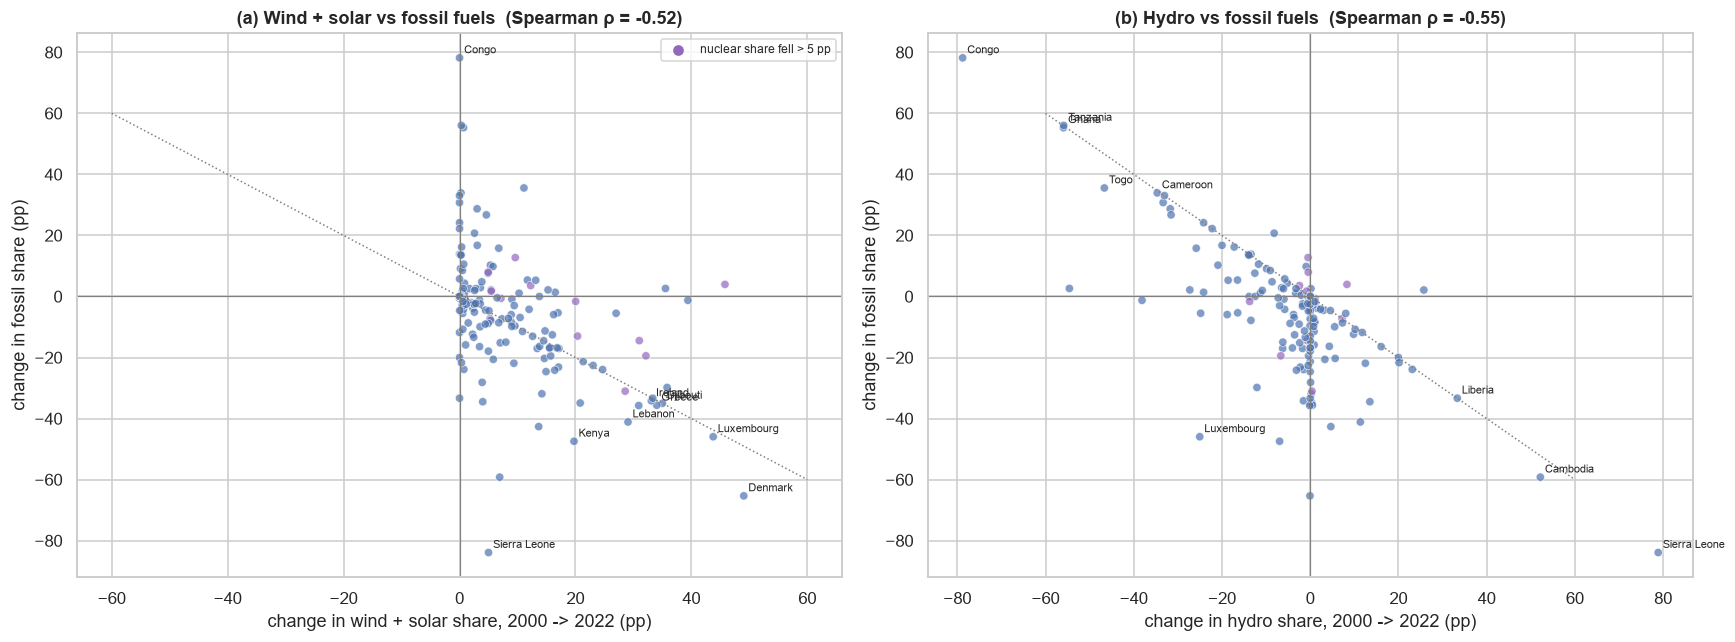

,fossil,coal,gas,oil,nuclear,hydro
wind + solar,-0.520,-0.230,-0.040,-0.250,-0.180,-0.080
hydro,-0.550,-0.030,-0.140,-0.320,0.020,1.000
nuclear,-0.160,0.000,-0.050,-0.070,1.000,0.020
coal,0.290,1.000,-0.240,-0.170,0.000,-0.030


In [61]:
s0 = eda[eda["year"] == 2000].set_index("country")[list(SOURCE_LABELS)]
s1 = eda[eda["year"] == 2022].set_index("country")[list(SOURCE_LABELS)]
delta = (s1 - s0).dropna().rename(columns=SOURCE_LABELS)
delta["wind + solar"] = delta["wind"] + delta["solar"]
delta["fossil"] = delta[["coal", "oil", "gas"]].sum(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
pairs_q5 = [("wind + solar", "fossil", "(a) Wind + solar vs fossil fuels"),
            ("hydro", "fossil", "(b) Hydro vs fossil fuels")]
for ax, (x, yv, title) in zip(axes, pairs_q5):
    colors = np.where(delta["nuclear"] < -5, "#9467BD", "#4C72B0")
    ax.scatter(delta[x], delta[yv], c=colors, alpha=0.7, s=30, edgecolor="white", lw=0.5)
    ax.axhline(0, color="grey", lw=0.8); ax.axvline(0, color="grey", lw=0.8)
    ax.plot([-60, 60], [60, -60], ls=":", color="grey", lw=1)          # perfect 1-for-1 substitution
    r, p = stats.spearmanr(delta[x], delta[yv])
    ax.set_title(f"{title}  (Spearman ρ = {r:.2f})")
    ax.set_xlabel(f"change in {x} share, 2000 -> 2022 (pp)"); ax.set_ylabel("change in fossil share (pp)")
    # label the most extreme countries
    extreme = (delta[x].abs() + delta[yv].abs()).nlargest(9).index
    for name in extreme:
        ax.annotate(name, (delta.at[name, x], delta.at[name, yv]), fontsize=7.5,
                    xytext=(3, 3), textcoords="offset points")
axes[0].scatter([], [], color="#9467BD", label="nuclear share fell > 5 pp")
axes[0].legend(fontsize=8, loc="upper right")
fig.tight_layout()
save_fig(fig, "fig17_source_substitution")
plt.show()

# Spearman correlation between the changes in shares
delta.corr(method="spearman").loc[["wind + solar", "hydro", "nuclear", "coal"],
                                  ["fossil", "coal", "gas", "oil", "nuclear", "hydro"]].round(2)

In [62]:
# Countries where nuclear decline offset the growth of wind and solar
delta.sort_values("nuclear").head(6)[["wind + solar", "nuclear", "fossil", "coal", "gas"]].round(1)

,wind + solar,nuclear,fossil,coal,gas
country,,,,,
Lithuania,45.800,-75.700,4.000,0.000,-1.900
Japan,9.600,-24.000,12.700,12.100,12.900
Germany,31.000,-23.700,-14.500,-20.400,5.300
France,12.300,-15.000,3.600,-4.200,7.600
Taiwan,4.900,-12.600,8.000,-5.900,29.800
Bulgaria,7.100,-12.100,-0.600,1.600,-0.600


**Answer to Q5 – yes, but in different ways**
* **Wind and solar have replaced fossil fuels** where they grew: the correlation between the two
  changes is clearly negative (ρ ≈ −0.5). The strongest examples (*Denmark*, *Greece*, *Portugal*) lie
  close to the 1-for-1 substitution line.
* **Hydro is the other main substitute for fossil fuels** (ρ ≈ −0.55): countries whose hydro share
  *fell* — often because demand outgrew the dams — filled the gap with fossil fuels. This is the
  mechanism behind the African and South American increases in carbon intensity.
* **Coal-to-gas switching** shows as a negative correlation between the changes in coal and gas
  (e.g. Greece, Portugal, the UK).
* **Nuclear decline cancelled out renewables** in some countries (purple points). *Lithuania* closed its
  only nuclear plant (−76 pp) and *Germany* and *Japan* reduced nuclear by about 24 pp. In Japan fossil
  fuels actually **grew** despite +10 pp of wind and solar. Low-carbon sources replaced each other
  instead of replacing fossil fuels — an important and easily overlooked pattern.

### 12.6 Carbon intensity across categorical groups

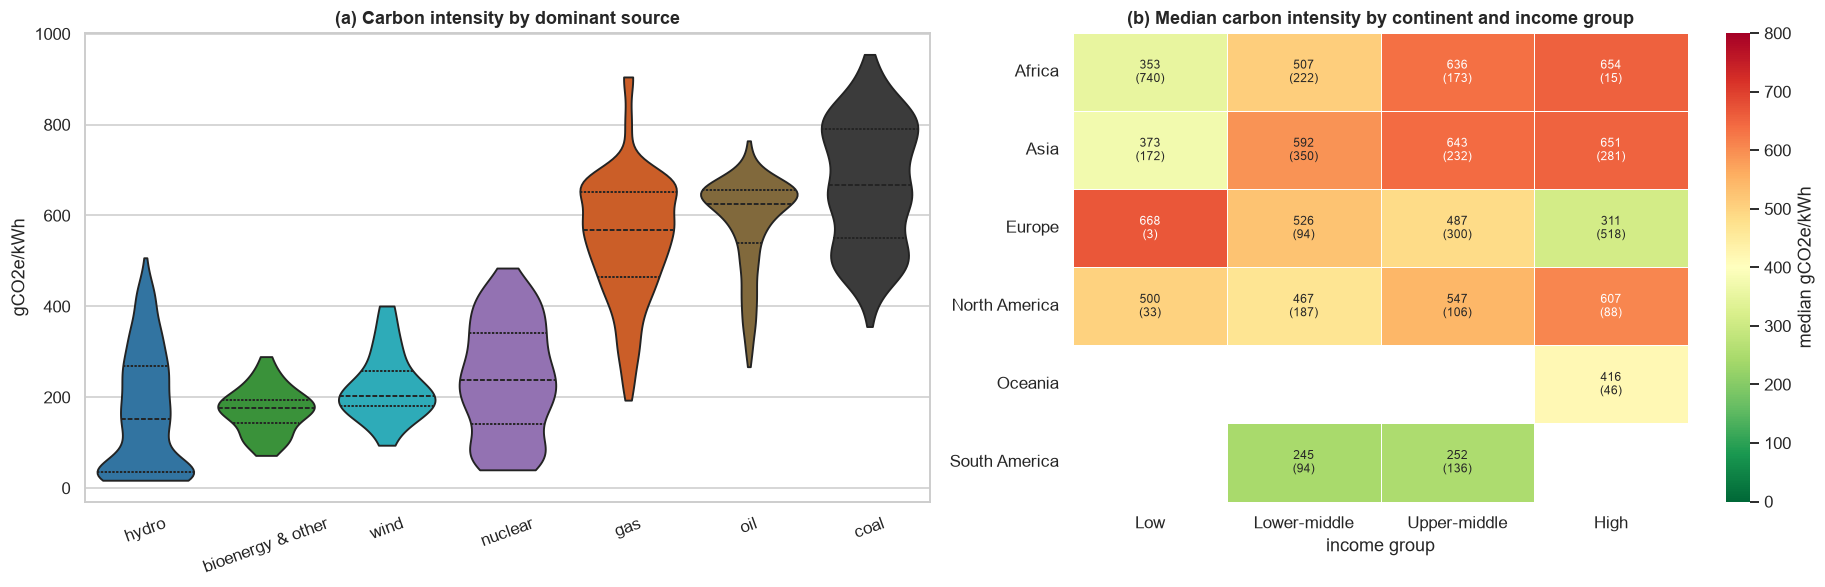

Kruskal-Wallis - continent: H = 423 (p = 3.0e-89); dominant source: H = 2579 (p = 0.0e+00)
Income group (from 12.2): H = 160


In [63]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})

# (a) Carbon intensity by dominant source
order_ci = eda.groupby("dominant_source")["carbon_intensity_elec"].median().sort_values().index
sns.violinplot(data=eda, x="dominant_source", y="carbon_intensity_elec", order=order_ci, ax=axes[0],
               hue="dominant_source", palette=SOURCE_COLORS, legend=False, cut=0, inner="quartile")
axes[0].set_xlabel(""); axes[0].set_ylabel("gCO2e/kWh")
axes[0].set_title("(a) Carbon intensity by dominant source")
axes[0].tick_params(axis="x", rotation=20)

# (b) Median carbon intensity for each continent x income group (number of country-years in brackets)
med = eda.pivot_table(index="continent", columns="income_group", values="carbon_intensity_elec",
                      aggfunc="median", observed=False)
cnt = eda.pivot_table(index="continent", columns="income_group", values="carbon_intensity_elec",
                      aggfunc="size", observed=False)
labels = med.round(0).astype("Int64").astype(str) + "\n(" + cnt.fillna(0).astype(int).astype(str) + ")"
labels = labels.where(cnt.fillna(0) > 0, "")
sns.heatmap(med, annot=labels, fmt="", cmap="RdYlGn_r", vmin=0, vmax=800, ax=axes[1],
            cbar_kws={"label": "median gCO2e/kWh"}, linewidths=0.5, annot_kws={"size": 8})
axes[1].set_title("(b) Median carbon intensity by continent and income group")
axes[1].grid(False)
axes[1].set_xlabel("income group"); axes[1].set_ylabel("")
fig.tight_layout()
save_fig(fig, "fig18_ci_by_category")
plt.show()

H_c, p_c = stats.kruskal(*[g["carbon_intensity_elec"].values for _, g in eda.groupby("continent")])
H_s, p_s = stats.kruskal(*[g["carbon_intensity_elec"].values for _, g in eda.groupby("dominant_source")])
print(f"Kruskal-Wallis - continent: H = {H_c:.0f} (p = {p_c:.1e}); dominant source: H = {H_s:.0f} (p = {p_s:.1e})")
print(f"Income group (from 12.2): H = {H:.0f}")

* **The dominant source is by far the best single predictor of carbon intensity** (largest
  Kruskal–Wallis H): systems led by hydro, bioenergy, wind or nuclear sit around 150–240 g, while gas-,
  oil- and coal-led systems sit around 570–670 g.
* **The effect of income depends on the continent** — an *interaction*. In **Europe**, high-income
  countries have the cleanest electricity (≈ 310 g); in **Africa and Asia**, high-income countries have
  the **dirtiest** (≈ 650 g), because their wealth comes largely from oil and gas (Gulf states, Libya,
  Equatorial Guinea) and they burn those fuels for power. Low-income countries in Africa and Asia are
  the cleanest groups in their continents (hydro). (Cells based on very few rows, such as low-income
  Europe, should be read with caution.)

### 12.7 Pairwise view of the main features

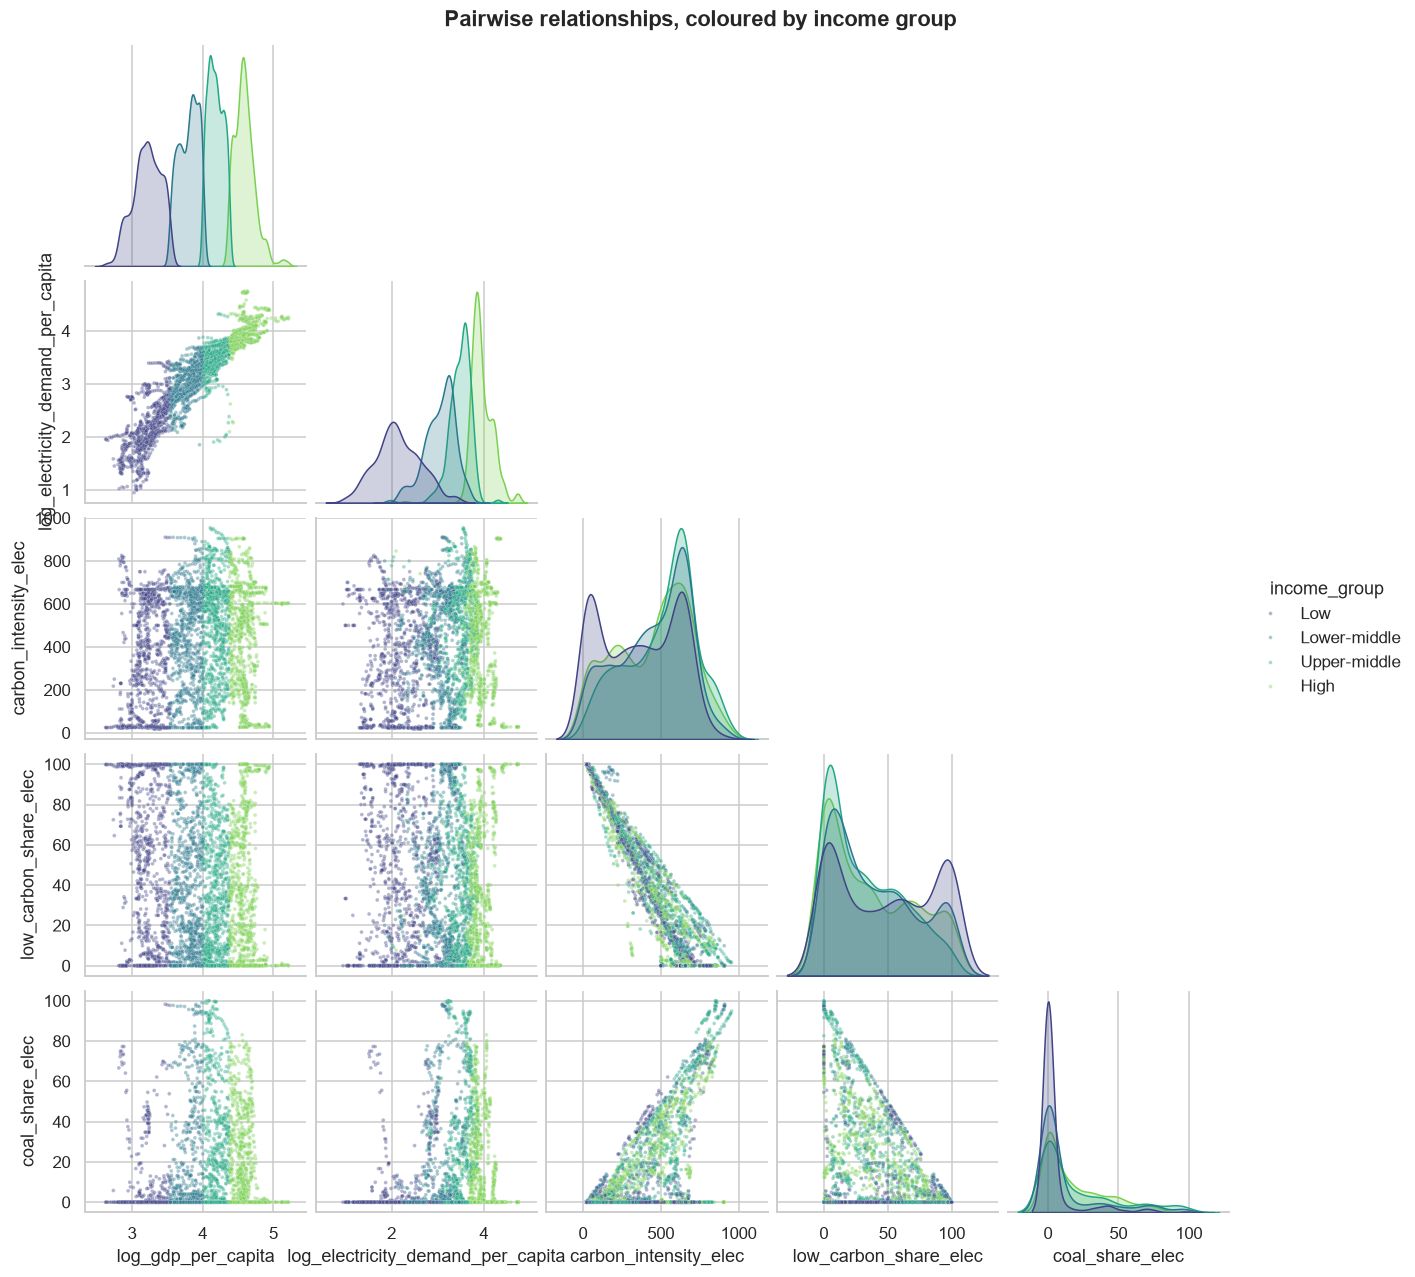

In [64]:
pair_cols = ["log_gdp_per_capita", "log_electricity_demand_per_capita", "carbon_intensity_elec",
             "low_carbon_share_elec", "coal_share_elec"]
g = sns.pairplot(eda[pair_cols + ["income_group"]], hue="income_group", corner=True,
                 plot_kws={"s": 6, "alpha": 0.4}, diag_kind="kde", palette="viridis", height=2.3)
g.figure.suptitle("Pairwise relationships, coloured by income group", y=1.01, fontweight="bold")
save_fig(g.figure, "fig19_pairplot")
plt.show()

The pair plot brings the findings together: income groups separate clearly along GDP and demand (by
construction and through the strong demand–wealth link), but **overlap almost completely** in carbon
intensity and low-carbon share. The carbon-intensity / low-carbon panel shows the near-linear inverse
relationship, and the coal panels show that high coal shares occur at every income level above *Low*.

### 12.8 Summary of the covariation analysis

| Question | Finding |
|---|---|
| Q3 – wealth vs clean power | Weak overall (ρ ≈ 0.13) and fading over time; an **inverted U**: poorest (hydro) and richest (nuclear, wind, solar) countries are cleaner than middle-income ones. Wealth predicts demand (elasticity ≈ 1.3), not cleanliness. |
| Q4 – continents | North America (−31 %), Oceania (−28 %) and Europe (−25 %) improved most; Asia (−5 %) and Africa (−11 %) little; South America got dirtier (+12 %) but remains the cleanest. |
| Q5 – substitution | Wind/solar and hydro substitute for fossil fuels; coal-to-gas switching; in some countries nuclear closures cancelled out renewable growth. |
| Unusual patterns | Rich-but-dirty Gulf states and Poland; poor-but-clean hydro countries; income effect reverses between Europe and Africa/Asia; carbon intensity rose in hydro-dependent African and South American countries. |

The strong blocks of correlated features (size, development, cleanliness) motivate the use of PCA. Part 7
prepares the data for it by encoding the categorical features and scaling the numeric ones.

## 13. Encoding the categorical features

Most statistical and machine-learning methods, including PCA, work only with numbers, so the three
categorical features created in Part 3 must be **encoded**. The right encoding depends on the type of
variable:

| Feature | Type | Levels | Encoding used | Reason |
|---|---|---|---|---|
| `dominant_source` | nominal (no natural order) | 7 | **Label encoding** (demonstrated) and **one-hot** | Shows how label encoding works and why it misleads distance-based methods |
| `income_group` | ordinal (Low < Lower-middle < Upper-middle < High) | 4 | **Ordinal encoding** | The order is meaningful, so integer codes 0–3 keep it |
| `continent` | nominal | 6 | **One-hot encoding** | No order between continents; every continent must be equally far from every other |

All encoders come from scikit-learn (Pedregosa *et al.*, 2011), so the same fitted encoder could be
re-applied to new data.

In [65]:
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, OneHotEncoder, StandardScaler

# Encoded columns are collected in a separate table next to the identifiers
enc = eda[ID_COLS + CAT_COLS].copy()
enc[CAT_COLS].describe()

,continent,dominant_source,income_group
count,3790,3790,3790
unique,6,7,4
top,Africa,hydro,Low
freq,1150,1142,948


### 13.1 Label encoding – `dominant_source`
**Label encoding** replaces each category with an integer `0 … k−1`. scikit-learn's `LabelEncoder`
assigns the codes in alphabetical order.

In [66]:
label_enc = LabelEncoder()
enc["dominant_source_label"] = label_enc.fit_transform(eda["dominant_source"])

# The mapping learned by the encoder
label_map = pd.DataFrame({"dominant_source": label_enc.classes_,
                          "label": range(len(label_enc.classes_))}).set_index("dominant_source")
label_map["rows"] = eda["dominant_source"].value_counts()
display(label_map.T)

# The encoding is reversible: decoding the labels gives back the original categories
decoded = label_enc.inverse_transform(enc["dominant_source_label"])
print("Inverse transform recovers every category:", (decoded == eda["dominant_source"].values).all())
enc[["country", "year", "dominant_source", "dominant_source_label"]].sample(5, random_state=RANDOM_STATE)

dominant_source,bioenergy & other,coal,gas,hydro,nuclear,oil,wind
label,0,1,2,3,4,5,6
rows,35,622,920,1142,198,854,19


Inverse transform recovers every category: True


,country,year,dominant_source,dominant_source_label
1580,Indonesia,2016,coal,1
2257,Mongolia,2003,coal,1
263,Barbados,2010,oil,5
1837,Kuwait,2020,gas,2
3654,Uzbekistan,2002,gas,2


**The problem with label encoding for nominal data.** The integers suggest an order and a distance that
do not exist: *wind* (6) would be "six units" away from *bioenergy & other* (0) but only one unit from
*solar*… and any statistic computed on the codes depends on the arbitrary alphabetical order. The cell
below shows this by correlating the codes with carbon intensity under the alphabetical order and under
a few random re-orderings of the same categories.

In [67]:
r_alpha = np.corrcoef(enc["dominant_source_label"], eda["carbon_intensity_elec"])[0, 1]
print(f"Pearson r (alphabetical codes vs carbon intensity): {r_alpha:+.2f}")

rng = np.random.default_rng(RANDOM_STATE)
for i in range(4):
    perm = rng.permutation(len(label_enc.classes_))          # a different, equally arbitrary order
    codes = perm[enc["dominant_source_label"]]
    r = np.corrcoef(codes, eda["carbon_intensity_elec"])[0, 1]
    print(f"Pearson r with random order #{i + 1}: {r:+.2f}")

Pearson r (alphabetical codes vs carbon intensity): -0.13
Pearson r with random order #1: +0.13
Pearson r with random order #2: +0.44
Pearson r with random order #3: +0.03
Pearson r with random order #4: +0.53


The "correlation" swings in size and even sign depending only on how the categories happen to be
numbered. Label encoding is therefore suitable for **target labels** (e.g. a class to predict) or for
**tree-based models**, which split on thresholds and do not use distances — but **not** as an input to
PCA, regression or clustering.

### 13.2 Ordinal encoding – `income_group`
Here the order is real, so the categories are mapped to 0–3 **in the order we specify**
(not alphabetically, which would put *High* first).

In [68]:
ord_enc = OrdinalEncoder(categories=[INCOME_LEVELS], dtype=int)
enc["income_group_ord"] = ord_enc.fit_transform(eda[["income_group"]].astype(str)).ravel()

# Check: the codes should rise with GDP per capita
check = (pd.DataFrame({"income_group": eda["income_group"], "code": enc["income_group_ord"],
                       "gdp_per_capita": eda["gdp_per_capita"]})
         .groupby(["code", "income_group"], observed=True)["gdp_per_capita"]
         .agg(["min", "median", "max", "size"]))
display(check.round(0))
rho = stats.spearmanr(enc["income_group_ord"], eda["gdp_per_capita"])[0]
print(f"Spearman rho between the ordinal code and GDP per capita: {rho:.3f}")

,,min,median,max,size
code,income_group,,,,
0,Low,422.000,"1,648.000","3,428.000",948
1,Lower-middle,"3,433.000","6,564.000","10,076.000",947
2,Upper-middle,"10,083.000","14,863.000","23,599.000",947
3,High,"23,678.000","37,626.000","163,531.000",948


Spearman rho between the ordinal code and GDP per capita: 0.968


The codes increase with GDP per capita (ρ ≈ 0.97), so the ordinal encoding keeps the meaning of the
categories. The only assumption is that the steps between groups are equal (Low → Lower-middle is
treated like Upper-middle → High), which is acceptable for quartile-based groups.

### 13.3 One-hot encoding – `continent` (and `dominant_source`)
**One-hot encoding** creates one binary (0/1) column per category; exactly one column is 1 in every row.
No order is implied and all categories are equally far apart.

In [69]:
# Full one-hot encoding (one column per continent)
onehot = OneHotEncoder(sparse_output=False, dtype=int)
cont_oh = pd.DataFrame(onehot.fit_transform(eda[["continent"]]),
                       columns=onehot.get_feature_names_out(["continent"]), index=eda.index)

print("Every row has exactly one 1:", (cont_oh.sum(axis=1) == 1).all())
print("Rows per column:")
print(cont_oh.sum().to_string())
pd.concat([eda[["country", "continent"]], cont_oh], axis=1).drop_duplicates("country").head(6)

Every row has exactly one 1: True
Rows per column:
continent_Africa           1150
continent_Asia             1035
continent_Europe            915
continent_North America     414
continent_Oceania            46
continent_South America     230


,country,continent,continent_Africa,continent_Asia,continent_Europe,continent_North America,continent_Oceania,continent_South America
0,Afghanistan,Asia,0,1,0,0,0,0
23,Albania,Europe,0,0,1,0,0,0
46,Algeria,Africa,1,0,0,0,0,0
69,Angola,Africa,1,0,0,0,0,0
92,Argentina,South America,0,0,0,0,0,1
115,Armenia,Asia,0,1,0,0,0,0


In [70]:
# Because the columns always sum to 1, one of them is redundant (the "dummy variable trap"):
# it can be predicted perfectly from the others. drop="first" removes the first category, which
# then becomes the reference level (all zeros).
onehot_drop = OneHotEncoder(sparse_output=False, dtype=int, drop="first")
cont_oh_drop = pd.DataFrame(onehot_drop.fit_transform(eda[["continent"]]),
                            columns=onehot_drop.get_feature_names_out(["continent"]), index=eda.index)
print("Reference (dropped) category:", onehot_drop.categories_[0][0])
print("Columns kept:", cont_oh_drop.columns.tolist())

# pandas offers the same transformation; check that both give identical results
dummies = pd.get_dummies(eda["continent"], prefix="continent", drop_first=True, dtype=int)
print("pd.get_dummies gives the same matrix:", (dummies.values == cont_oh_drop.values).all())

# One-hot encoding of dominant_source, for comparison with the label encoding
src_onehot = OneHotEncoder(sparse_output=False, dtype=int)
src_oh = pd.DataFrame(src_onehot.fit_transform(eda[["dominant_source"]]),
                      columns=src_onehot.get_feature_names_out(["dominant_source"]), index=eda.index)

enc = pd.concat([enc, cont_oh_drop, src_oh], axis=1)
print(f"\nEncoded table: {enc.shape[0]:,} rows x {enc.shape[1]} columns")

Reference (dropped) category: Africa
Columns kept: ['continent_Asia', 'continent_Europe', 'continent_North America', 'continent_Oceania', 'continent_South America']
pd.get_dummies gives the same matrix: True

Encoded table: 3,790 rows x 20 columns


### 13.4 Label versus one-hot: what the encoding does to distances
PCA and most other multivariate methods are based on distances between rows. The figure compares the
distance between every pair of `dominant_source` categories under the two encodings.

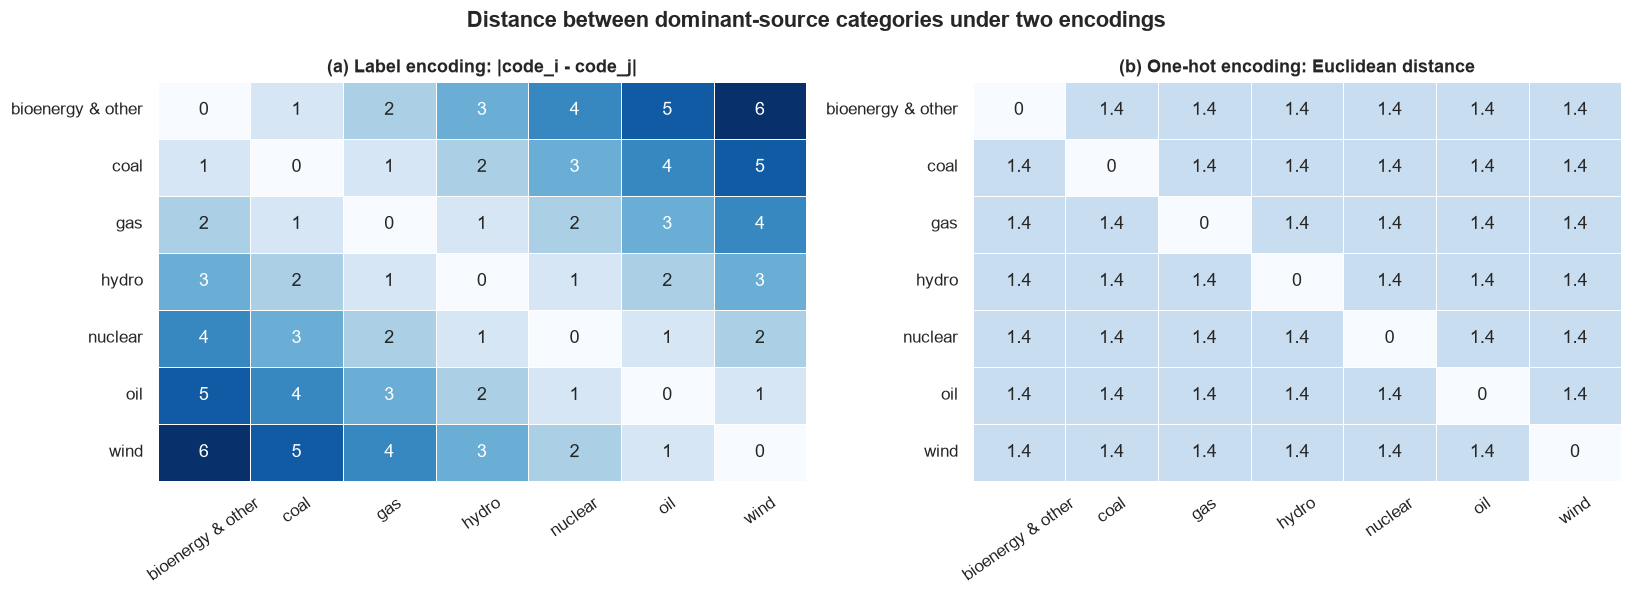

In [71]:
cats = label_enc.classes_
label_dist = pd.DataFrame(np.abs(np.subtract.outer(np.arange(len(cats)), np.arange(len(cats)))),
                          index=cats, columns=cats)
onehot_vectors = np.eye(len(cats))
onehot_dist = pd.DataFrame(np.sqrt(((onehot_vectors[:, None, :] - onehot_vectors[None, :, :]) ** 2).sum(-1)),
                           index=cats, columns=cats)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, (dist, title) in zip(axes, [(label_dist, "(a) Label encoding: |code_i - code_j|"),
                                    (onehot_dist, "(b) One-hot encoding: Euclidean distance")]):
    sns.heatmap(dist, annot=True, fmt=".2g", cmap="Blues", cbar=False, ax=ax, linewidths=0.5,
                vmin=0, vmax=6)
    ax.set_title(title); ax.tick_params(axis="x", rotation=35); ax.tick_params(axis="y", rotation=0)
fig.suptitle("Distance between dominant-source categories under two encodings", fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig20_label_vs_onehot")
plt.show()

Under label encoding, *bioenergy & other* and *wind* are six times further apart than *coal* and *gas*,
purely because of their position in the alphabet. Under one-hot encoding every pair of different
categories is the same distance (√2 ≈ 1.41) apart, which correctly reflects that the categories are
simply *different*. The cost is dimensionality: one column becomes seven.

### 13.5 Summary of the encodings

| Encoding | Applied to | Columns created | Keeps order? | Suitable for PCA? |
|---|---|---|---|---|
| Label | `dominant_source` | 1 (`dominant_source_label`, 0–6) | invents a false order | No – shown for illustration |
| Ordinal | `income_group` | 1 (`income_group_ord`, 0–3) | yes (real order) | Yes |
| One-hot (drop first) | `continent` | 5 (Africa = reference) | no order implied | Yes |
| One-hot (full) | `dominant_source` | 7 | no order implied | Yes, but used here for colouring only |

## 14. Preparing the feature matrix for PCA

### 14.1 Choosing the features
PCA is run on continuous features that describe each country-year, avoiding features that are exact
functions of others:
* the **log** versions of the six skewed size variables (Part 4), so that a few very large countries do
  not dominate;
* the **eight source shares**, carbon intensity and capped net imports;
* **excluded:** `gdp` (= GDP per capita × population), `low_carbon_share_elec` (the sum of five shares),
  the raw skewed columns, and the identifiers.

A second, **extended** matrix adds the encoded categorical features (ordinal income group and one-hot
continent) so that Part 8 can test whether they change the PCA result.

In [72]:
PCA_FEATURES = ["log_population", "log_gdp_per_capita", "log_energy_per_capita",
                "log_electricity_demand_per_capita", "log_electricity_generation",
                "log_greenhouse_gas_emissions", "net_imports_capped", "carbon_intensity_elec",
                "coal_share_elec", "gas_share_elec", "oil_share_elec", "hydro_share_elec",
                "nuclear_share_elec", "wind_share_elec", "solar_share_elec", "other_renewables_share_elec"]
X = eda[PCA_FEATURES]

# Why scaling is needed: each feature's share of the total variance on its original scale
raw_var = X.var().sort_values(ascending=False)
pd.DataFrame({"std (original units)": X.std()[raw_var.index],
              "% of total variance": raw_var / raw_var.sum() * 100}).round(2)

,std (original units),% of total variance
carbon_intensity_elec,239.570,92.630
oil_share_elec,33.190,1.780
hydro_share_elec,32.360,1.690
gas_share_elec,30.150,1.470
net_imports_capped,26.280,1.110
coal_share_elec,23.610,0.900
nuclear_share_elec,13.020,0.270
other_renewables_share_elec,7.380,0.090
wind_share_elec,5.070,0.040
solar_share_elec,2.480,0.010


PCA finds the directions of **largest variance**. On the original scales, carbon intensity (measured in
hundreds of g/kWh) holds about 93 % of the total variance and the log-scaled features almost none, so an
unscaled PCA would simply rediscover carbon intensity. Each feature is therefore **standardised** to a
mean of 0 and a standard deviation of 1 (z-score), so that all features count equally and PCA works on
the correlation matrix.

### 14.2 Standardisation

In [73]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=PCA_FEATURES, index=X.index)

# Check: every column now has mean 0 and standard deviation 1
pd.DataFrame({"mean": X_scaled.mean(), "std": X_scaled.std(ddof=0)}).round(3).T

,log_population,log_gdp_per_capita,log_energy_per_capita,log_electricity_demand_per_capita,log_electricity_generation,log_greenhouse_gas_emissions,net_imports_capped,carbon_intensity_elec,coal_share_elec,gas_share_elec,oil_share_elec,hydro_share_elec,nuclear_share_elec,wind_share_elec,solar_share_elec,other_renewables_share_elec
mean,-0.000,0.000,0.000,0.000,-0.000,-0.000,-0.000,0.000,-0.000,0.000,-0.000,-0.000,0.000,0.000,-0.000,0.000
std,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000


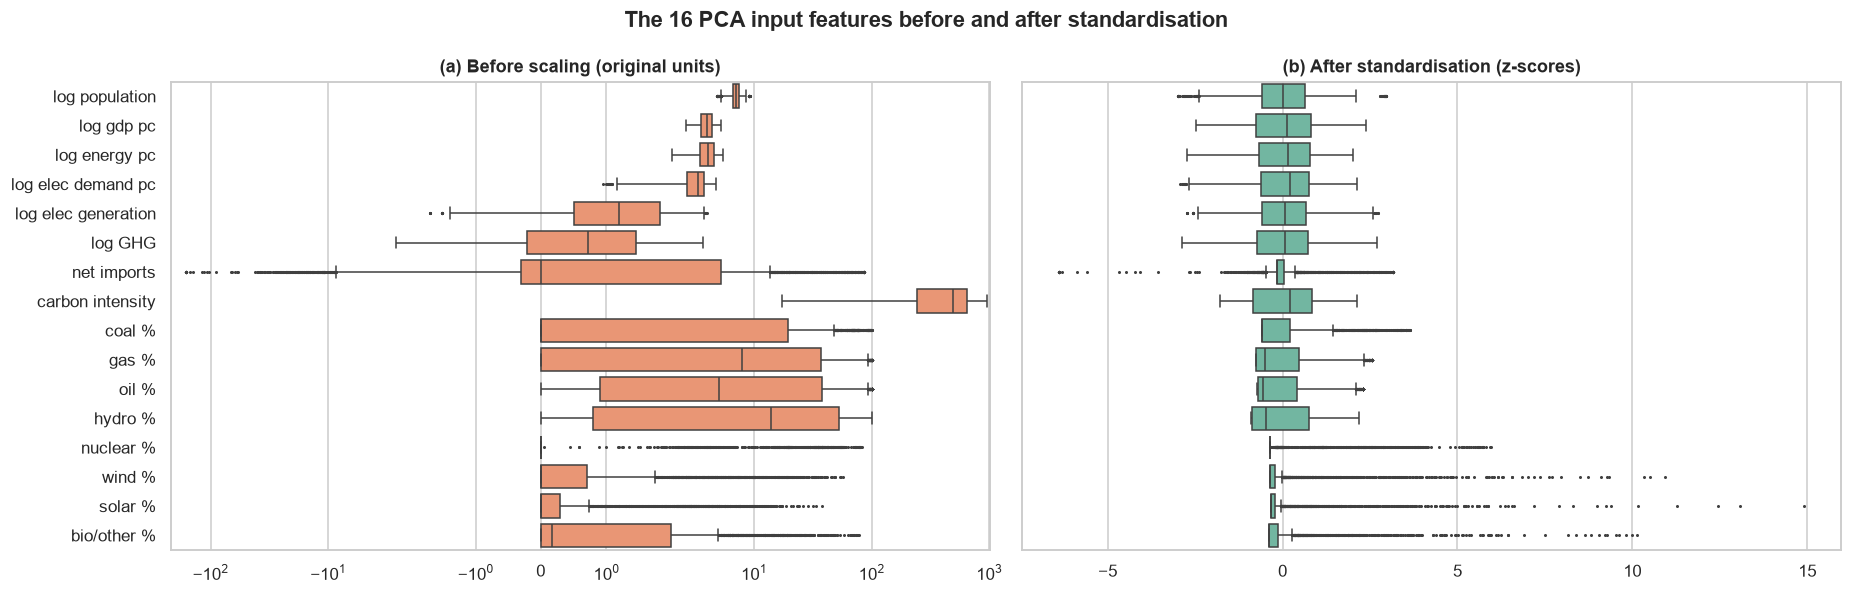

In [74]:
fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))
short = [SHORT.get(c, c) for c in PCA_FEATURES]
sns.boxplot(data=X.set_axis(short, axis=1), orient="h", ax=axes[0], color="#FC8D62", fliersize=1)
axes[0].set_title("(a) Before scaling (original units)"); axes[0].set_xscale("symlog")
sns.boxplot(data=X_scaled.set_axis(short, axis=1), orient="h", ax=axes[1], color="#66C2A5", fliersize=1)
axes[1].set_title("(b) After standardisation (z-scores)"); axes[1].set_yticklabels([])
fig.suptitle("The 16 PCA input features before and after standardisation", fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig21_scaling")
plt.show()

After standardisation all features share a common scale centred on 0, while the *shape* of each
distribution (including the long right tails of the wind, solar and nuclear shares) is unchanged.
Standardisation changes units, not information.

### 14.3 Extended matrix with encoded categorical features

In [75]:
# Numeric features + ordinal income group + one-hot continent, all standardised together
X_ext_raw = pd.concat([X, enc[["income_group_ord"]], cont_oh_drop], axis=1)
EXT_FEATURES = X_ext_raw.columns.tolist()
X_ext = pd.DataFrame(StandardScaler().fit_transform(X_ext_raw), columns=EXT_FEATURES, index=X.index)
print(f"Numeric matrix : {X_scaled.shape[0]:,} rows x {X_scaled.shape[1]} features")
print(f"Extended matrix: {X_ext.shape[0]:,} rows x {X_ext.shape[1]} features "
      f"(+ income_group_ord + {cont_oh_drop.shape[1]} continent dummies)")

Numeric matrix : 3,790 rows x 16 features
Extended matrix: 3,790 rows x 22 features (+ income_group_ord + 5 continent dummies)


### 14.4 Is the data suitable for PCA?
Two standard checks tell whether there is enough shared correlation for PCA to be useful:
* **Bartlett's test of sphericity** tests the null hypothesis that the correlation matrix is an identity
  matrix (no correlations at all). A small p-value means PCA can find structure.
* **Kaiser–Meyer–Olkin (KMO) measure** compares the size of the correlations with the size of the
  partial correlations. Kaiser (1974) describes values of 0.9+ as marvellous, 0.8+ meritorious,
  0.7+ middling, 0.6+ mediocre, 0.5+ miserable and below 0.5 unacceptable.

Because the eight shares sum to 100 %, the correlation matrix of all 16 features is singular (its
determinant is zero), which both tests need to invert. The tests are therefore run with one share
(`other_renewables_share_elec`) left out; this removes the exact dependency without losing information.

In [76]:
R_full = np.corrcoef(X_scaled.T)
print(f"Smallest eigenvalue of the 16-feature correlation matrix: {np.linalg.eigvalsh(R_full).min():.2e} "
      "(~0 -> exact linear dependency among the shares)")

test_cols = [c for c in PCA_FEATURES if c != "other_renewables_share_elec"]
R = np.corrcoef(X_scaled[test_cols].T)
n, p = X_scaled.shape[0], len(test_cols)

# Bartlett's test of sphericity
chi2 = -(n - 1 - (2 * p + 5) / 6) * np.log(np.linalg.det(R))
dof = p * (p - 1) / 2
p_value = stats.chi2.sf(chi2, dof)
print(f"Bartlett's test: chi2 = {chi2:,.0f}, df = {dof:.0f}, p = {p_value:.1e}")

# Kaiser-Meyer-Olkin measure of sampling adequacy
R_inv = np.linalg.inv(R)
partial = -R_inv / np.sqrt(np.outer(np.diag(R_inv), np.diag(R_inv)))
off = ~np.eye(p, dtype=bool)
kmo = (R[off] ** 2).sum() / ((R[off] ** 2).sum() + (partial[off] ** 2).sum())
print(f"Overall KMO = {kmo:.2f}")

# KMO for each feature (measure of sampling adequacy, MSA)
r2, p2 = R ** 2, partial ** 2
np.fill_diagonal(r2, 0); np.fill_diagonal(p2, 0)
msa = pd.Series(r2.sum(axis=0) / (r2.sum(axis=0) + p2.sum(axis=0)), index=test_cols, name="MSA")
msa.sort_values().round(2).to_frame().T

Smallest eigenvalue of the 16-feature correlation matrix: 8.78e-11 (~0 -> exact linear dependency among the shares)
Bartlett's test: chi2 = 84,598, df = 105, p = 0.0e+00
Overall KMO = 0.48


,net_imports_capped,wind_share_elec,nuclear_share_elec,gas_share_elec,coal_share_elec,log_population,solar_share_elec,oil_share_elec,hydro_share_elec,carbon_intensity_elec,log_electricity_generation,log_electricity_demand_per_capita,log_greenhouse_gas_emissions,log_energy_per_capita,log_gdp_per_capita
MSA,0.100,0.210,0.240,0.240,0.260,0.300,0.310,0.310,0.410,0.530,0.570,0.580,0.880,0.890,0.900


**Interpreting the two tests**
* **Bartlett's test** strongly rejects the hypothesis of no correlation (p ≈ 0): the features are far
  from independent, so PCA can find shared structure.
* The **overall KMO is low (≈ 0.48)**, below Kaiser's (1974) "mediocre" threshold of 0.6. The per-feature
  values explain why. The features with high MSA (GDP per capita, energy per capita, emissions ≈ 0.9)
  belong to the strong "development" block. The low values belong to features that are **almost exact
  functions of other features**:
  * the source **shares** are compositional — given seven of them, the eighth is fixed, and carbon
    intensity is largely determined by the mix;
  * `log generation ≈ log population + log demand per person` and
    `log emissions = log carbon intensity + log generation` (identities checked in Part 4);
  * net imports link generation and demand.

  Such identities make the **partial** correlations very large, which is exactly what pulls KMO down.
* KMO was designed for **factor analysis**, which models shared latent factors. PCA is a variance-
  summarising rotation and does not require it. Here the low KMO is a sign of **redundancy** — several
  features carry the same information — which is precisely what PCA is meant to compress. The result is
  noted as a limitation and the PCA is interpreted with this in mind.

The near-zero eigenvalue also tells us in advance that the **last principal component will have
(almost) no variance**: it will simply recover the rule that the shares add up to 100 %.

In [77]:
# Save the model-ready data (identifiers + encoded categoricals + standardised features)
pca_ready = pd.concat([eda[ID_COLS + CAT_COLS],
                       enc[["dominant_source_label", "income_group_ord"]],
                       X_ext.add_suffix("_z")], axis=1)
PCA_READY_PATH = os.path.join(DATA_DIR, "pca_ready.csv")
pca_ready.to_csv(PCA_READY_PATH, index=False)
print(f"Saved {PCA_READY_PATH}: {pca_ready.shape[0]:,} rows x {pca_ready.shape[1]} columns")

Saved data\pca_ready.csv: 3,790 rows x 30 columns


## 15. Principal Component Analysis (PCA)

**PCA** (Pearson, 1901; Jolliffe, 2002) replaces a set of correlated features with a smaller set of new,
**uncorrelated** variables — the *principal components* (PCs). Each PC is a weighted sum of the
standardised features:

$$PC_k = w_{k,1} z_1 + w_{k,2} z_2 + \dots + w_{k,16} z_{16}$$

The weights $w_k$ are the eigenvectors of the correlation matrix, and the variance of each PC is the
matching eigenvalue $\lambda_k$. PC1 is the direction of greatest variance, PC2 the greatest remaining
variance at right angles to PC1, and so on. Because the inputs were standardised in Part 7, each
feature contributes a variance of 1, so the 16 eigenvalues add up to 16.

This answers **Q6**: *can the many correlated indicators be summarised by a few components, and what do
they represent?*

### 15.1 Fitting PCA and the explained variance

In [78]:
from sklearn.decomposition import PCA

pca = PCA(random_state=RANDOM_STATE)
scores_all = pca.fit_transform(X_scaled)
n_pc = len(PCA_FEATURES)
PC_NAMES = [f"PC{i + 1}" for i in range(n_pc)]

# Sign convention: the sign of a principal component is arbitrary. Fix it so that the results read the
# same way on every run: PC1 rises with GDP per capita, PC2 with carbon intensity, PC3 with population.
anchor = {0: "log_gdp_per_capita", 1: "carbon_intensity_elec", 2: "log_population"}
for k, feat in anchor.items():
    if pca.components_[k, PCA_FEATURES.index(feat)] < 0:
        pca.components_[k] *= -1
        scores_all[:, k] *= -1

explained = pd.DataFrame({
    "eigenvalue": pca.explained_variance_,
    "% variance": pca.explained_variance_ratio_ * 100,
    "cumulative %": np.cumsum(pca.explained_variance_ratio_) * 100}, index=PC_NAMES)
print(f"Sum of eigenvalues = {pca.explained_variance_.sum():.2f} (number of standardised features = {n_pc})")
explained.round(3)

Sum of eigenvalues = 16.00 (number of standardised features = 16)


,eigenvalue,% variance,cumulative %
PC1,5.072,31.691,31.691
PC2,2.383,14.888,46.579
PC3,1.937,12.105,58.683
PC4,1.431,8.940,67.624
PC5,1.192,7.449,75.073
PC6,0.974,6.087,81.159
PC7,0.881,5.506,86.665
PC8,0.821,5.132,91.797
PC9,0.628,3.927,95.724
PC10,0.536,3.352,99.076


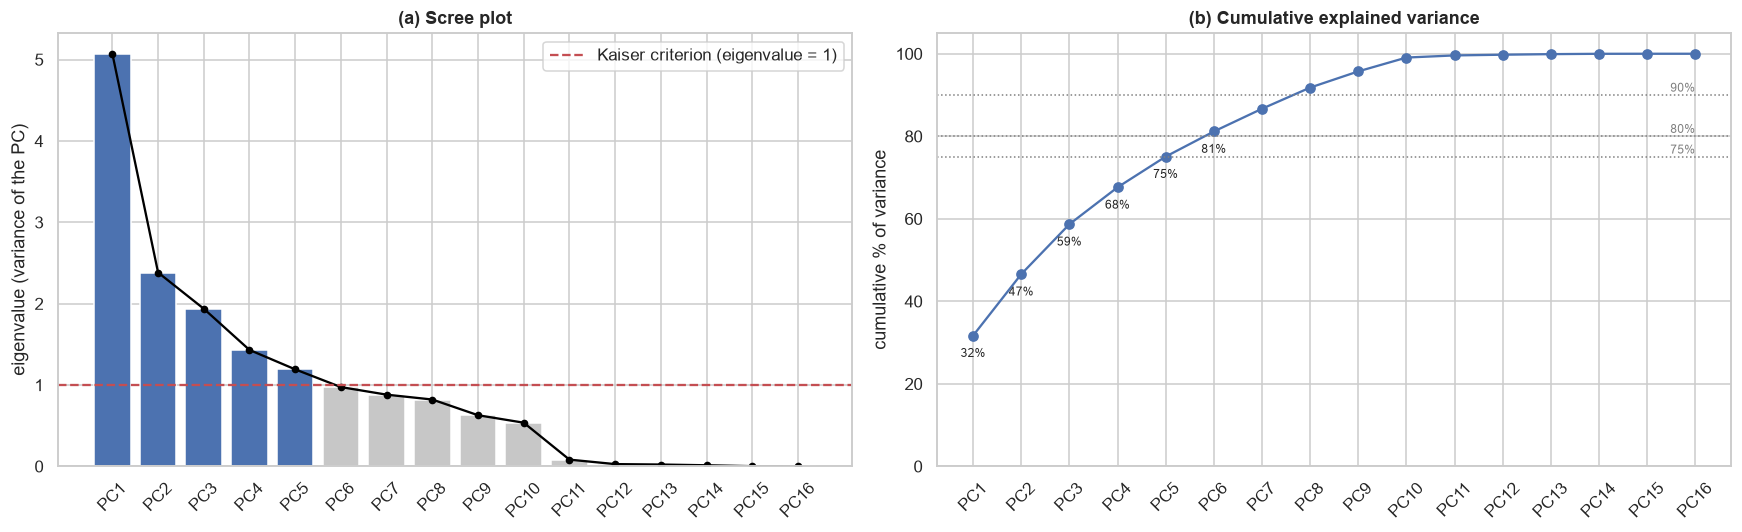

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# (a) Scree plot with the Kaiser criterion (eigenvalue = 1)
axes[0].bar(PC_NAMES, explained["eigenvalue"], color=np.where(explained["eigenvalue"] > 1, "#4C72B0", "#C7C7C7"))
axes[0].plot(PC_NAMES, explained["eigenvalue"], color="black", marker="o", ms=4)
axes[0].axhline(1, color="#C44E52", ls="--", label="Kaiser criterion (eigenvalue = 1)")
axes[0].set_ylabel("eigenvalue (variance of the PC)"); axes[0].set_title("(a) Scree plot")
axes[0].tick_params(axis="x", rotation=45); axes[0].legend()

# (b) Cumulative explained variance
axes[1].plot(PC_NAMES, explained["cumulative %"], marker="o", color="#4C72B0")
for thr in (75, 80, 90):
    axes[1].axhline(thr, color="grey", ls=":", lw=1)
    axes[1].text(n_pc - 1, thr + 0.8, f"{thr}%", ha="right", fontsize=8, color="grey")
for i in range(6):
    axes[1].annotate(f"{explained['cumulative %'].iloc[i]:.0f}%", (i, explained["cumulative %"].iloc[i]),
                     xytext=(0, -14), textcoords="offset points", ha="center", fontsize=8)
axes[1].set_ylim(0, 105); axes[1].set_ylabel("cumulative % of variance")
axes[1].set_title("(b) Cumulative explained variance"); axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout()
save_fig(fig, "fig22_scree_plot")
plt.show()

### 15.2 How many components to keep?
Three common rules are compared:

| Rule | Components | Variance retained |
|---|---|---|
| **Kaiser criterion** – keep PCs with eigenvalue > 1, i.e. that explain more than one original feature (Kaiser, 1960) | 5 | ≈ 75 % |
| **Cumulative variance ≥ 80 %** | 6 | ≈ 81 % |
| **Scree "elbow"** – where the curve flattens | 3 | ≈ 59 % |

**Five components** are retained (Kaiser criterion). They reduce 16 features to 5 (−69 %) while keeping
about three-quarters of the information. The sixth component has an eigenvalue just below 1 and would
add only about 6 %. The first three components carry most of the interpretable structure and are
analysed in detail.

Note also the **last eigenvalues**: PC11–PC15 are close to zero and **PC16 is exactly zero**, as
predicted in Section 14.4. These components capture the identities between the features (the shares
sum to 100 %; generation ≈ population × demand; emissions = intensity × generation). PCA has
automatically discovered the redundancy that lowered the KMO value.

### 15.3 Loadings: what does each component represent?
A **loading** is the correlation between an original feature and a component
($\text{loading}_{jk} = w_{kj}\sqrt{\lambda_k}$). Values near ±1 mean the feature is strongly
represented by that component.

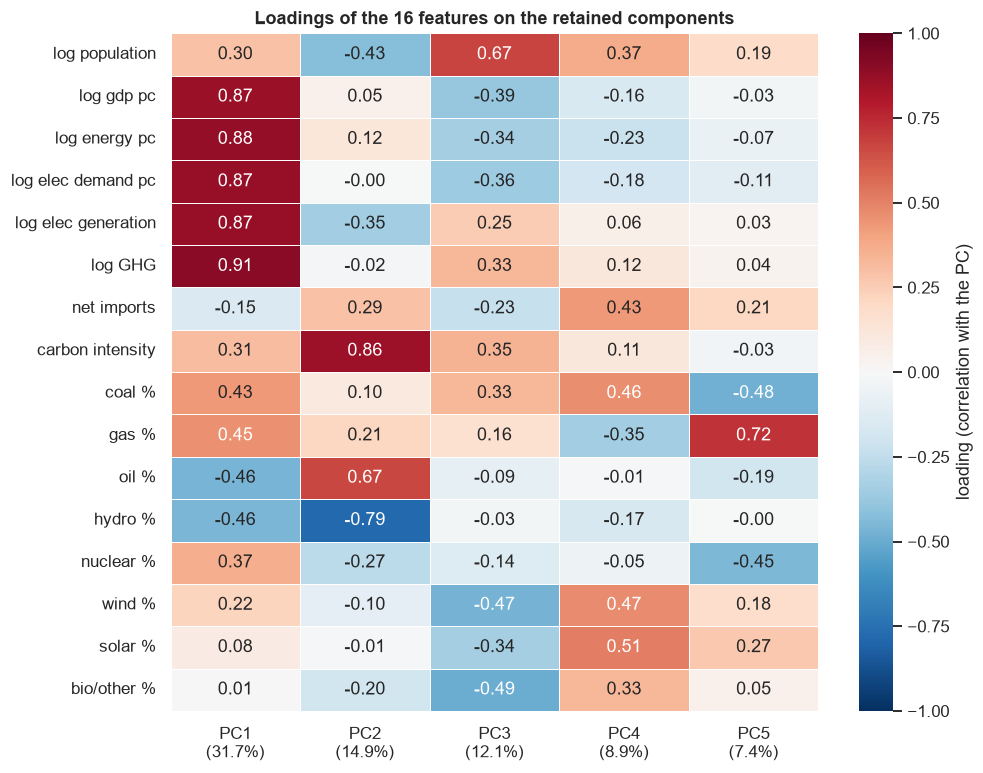

,PC1,PC2,PC3,PC4,PC5,communality
net_imports_capped,-0.150,0.290,-0.230,0.430,0.210,0.390
other_renewables_share_elec,0.010,-0.200,-0.490,0.330,0.050,0.400
nuclear_share_elec,0.370,-0.270,-0.140,-0.050,-0.450,0.430
solar_share_elec,0.080,-0.010,-0.340,0.510,0.270,0.460
wind_share_elec,0.220,-0.100,-0.470,0.470,0.180,0.540
oil_share_elec,-0.460,0.670,-0.090,-0.010,-0.190,0.700
coal_share_elec,0.430,0.100,0.330,0.460,-0.480,0.750
hydro_share_elec,-0.460,-0.790,-0.030,-0.170,-0.000,0.860
log_population,0.300,-0.430,0.670,0.370,0.190,0.900
gas_share_elec,0.450,0.210,0.160,-0.350,0.720,0.910


In [80]:
N_KEEP = 5
KEEP = PC_NAMES[:N_KEEP]
loadings = pd.DataFrame(pca.components_.T * np.sqrt(pca.explained_variance_),
                        index=PCA_FEATURES, columns=PC_NAMES)

# Communality: share of each feature's variance reproduced by the retained components
communality = (loadings[KEEP] ** 2).sum(axis=1).rename("communality")

fig, ax = plt.subplots(figsize=(9.5, 8))
plot_df = loadings[KEEP].rename(index=SHORT)
sns.heatmap(plot_df, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, linewidths=0.5,
            cbar_kws={"label": "loading (correlation with the PC)"}, ax=ax)
ax.set_xticklabels([f"{pc}\n({v:.1f}%)" for pc, v in zip(KEEP, explained["% variance"][:N_KEEP])])
ax.set_title("Loadings of the 16 features on the retained components")
save_fig(fig, "fig23_loadings")
plt.show()

pd.concat([loadings[KEEP], communality], axis=1).round(2).sort_values("communality")

**Interpreting the components**

| PC | Variance | Strongest loadings | Interpretation |
|---|---|---|---|
| **PC1** | 31.7 % | GDP per capita, energy per capita, electricity demand, generation, emissions (all ≈ +0.87 to +0.91); oil and hydro shares negative | **Economic development and system size.** Rich, high-consumption countries with large power systems (and coal, gas or nuclear) score high; poor countries relying on oil generators or a single dam score low. |
| **PC2** | 14.9 % | carbon intensity (+0.86), oil share (+0.67) **vs** hydro share (−0.79), population (−0.43) | **How dirty the electricity is: oil-fired vs hydro systems.** Independent of wealth — the "cleanliness" axis found in Part 6. |
| **PC3** | 12.1 % | population (+0.67), carbon intensity, coal, emissions **vs** wind (−0.47), bioenergy/other (−0.49), solar (−0.34), GDP per capita (−0.39) | **Large emerging fossil systems vs small renewable-led systems.** Populous, developing, coal-heavy countries score high; small countries with high wind/solar shares score low. This is the **transition axis**. |
| **PC4** | 8.9 % | solar (+0.51), wind (+0.47), coal (+0.46), net imports (+0.43) **vs** gas (−0.35) | **Mix diversity / interconnection vs gas dependence** – countries combining coal with new renewables and imports versus gas-based systems. |
| **PC5** | 7.4 % | gas (+0.72) **vs** coal (−0.48) and nuclear (−0.45) | **Gas versus coal and nuclear** – the choice among large-scale thermal technologies (the coal-to-gas switch of Part 6). |

The **communalities** show how much of each feature's variance the five components reproduce. They
are high (≥ 0.85) for GDP, energy and demand per person, generation, emissions, carbon intensity,
population, gas and hydro; moderate for coal and oil (≈ 0.7–0.75); and low (≈ 0.4–0.55) for net
imports, nuclear, wind, solar and bioenergy. These last features carry information specific to a few
countries, which is spread over the discarded components.

### 15.4 Where do countries sit on the components?

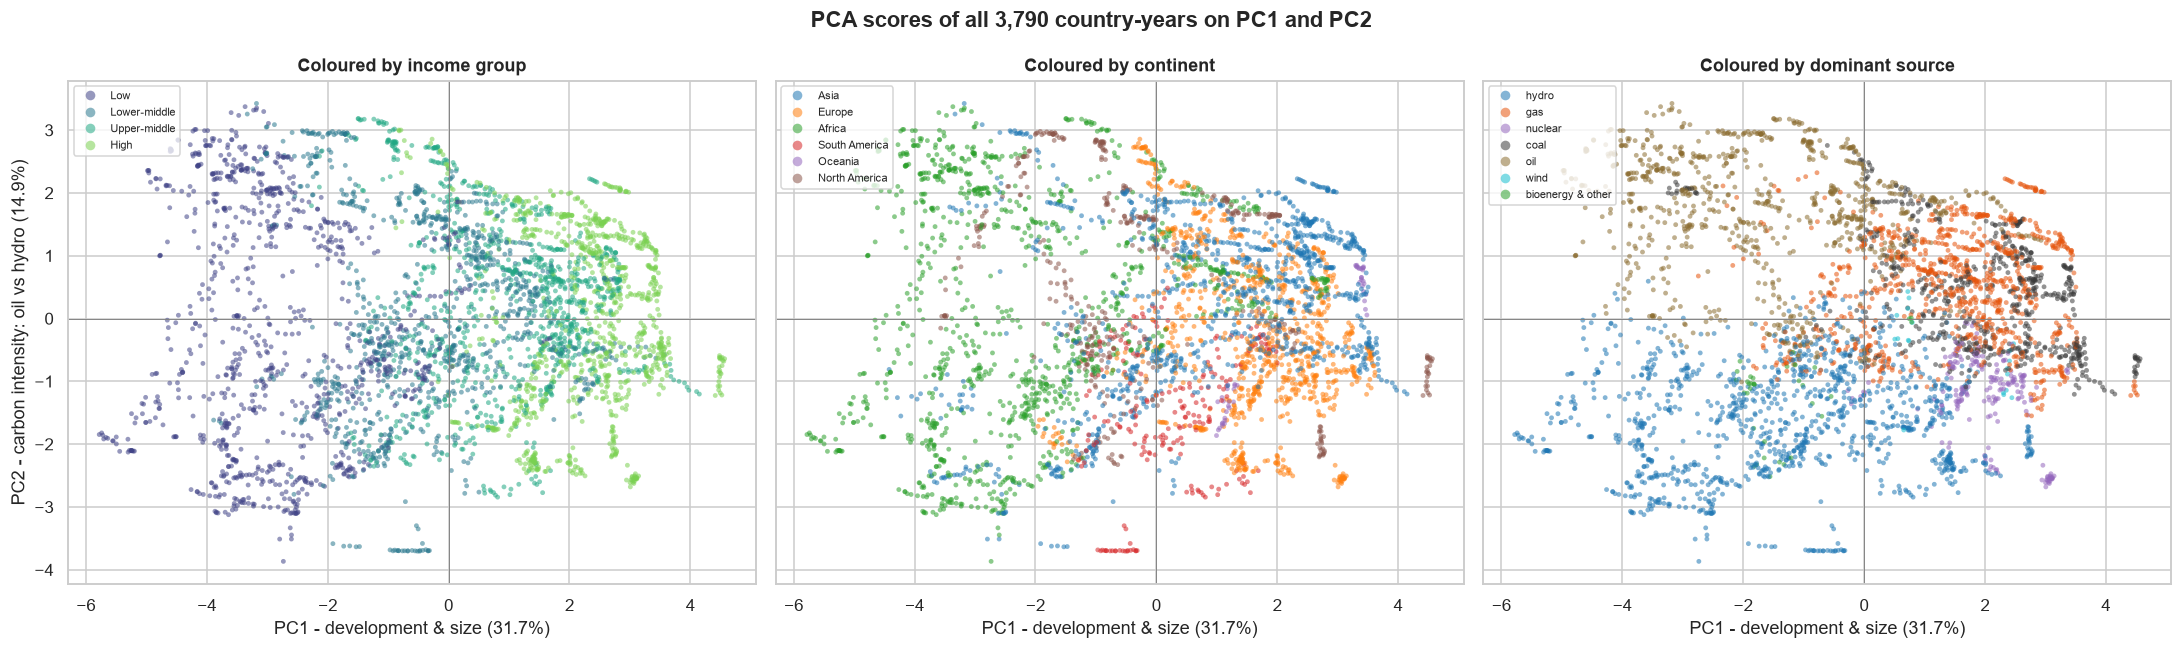

Mean scores by income group:


,PC1,PC2,PC3
income_group,,,
Low,-2.870,-0.160,0.630
Lower-middle,-0.360,-0.010,0.180
Upper-middle,0.950,0.230,0.010
High,2.270,-0.050,-0.820


Mean scores by dominant source:


,PC1,PC2,PC3
dominant_source,,,
hydro,-1.310,-1.620,-0.170
nuclear,2.040,-1.240,-1.010
bioenergy & other,-1.350,-1.230,-3.880
wind,1.480,-0.540,-5.410
coal,1.940,0.390,0.900
gas,1.470,0.460,0.350
oil,-1.700,1.730,-0.290


In [81]:
scores = pd.DataFrame(scores_all[:, :N_KEEP], columns=KEEP, index=eda.index)
pc_df = pd.concat([eda[ID_COLS + CAT_COLS], scores], axis=1)

fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharex=True, sharey=True)
hue_specs = [("income_group", "viridis", INCOME_LEVELS), ("continent", "tab10", None),
             ("dominant_source", SOURCE_COLORS, None)]
for ax, (hue, pal, order) in zip(axes, hue_specs):
    sns.scatterplot(data=pc_df, x="PC1", y="PC2", hue=hue, hue_order=order, palette=pal,
                    s=10, alpha=0.55, linewidth=0, ax=ax)
    ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6)
    ax.set_title(f"Coloured by {hue.replace('_', ' ')}")
    ax.set_xlabel(f"PC1 - development & size ({explained['% variance'].iloc[0]:.1f}%)")
    ax.set_ylabel(f"PC2 - carbon intensity: oil vs hydro ({explained['% variance'].iloc[1]:.1f}%)")
    ax.legend(fontsize=7.5, markerscale=2, loc="upper left")
fig.suptitle("PCA scores of all 3,790 country-years on PC1 and PC2", fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig24_pca_scores")
plt.show()

print("Mean scores by income group:")
display(pc_df.groupby("income_group", observed=True)[KEEP[:3]].mean().round(2))
print("Mean scores by dominant source:")
display(pc_df.groupby("dominant_source")[KEEP[:3]].mean().round(2).sort_values("PC2"))

* **Income groups separate along PC1** (Low ≈ −2.9, High ≈ +2.3) but **not along PC2** (all near 0).
  This confirms, in a single picture, the main result of the EDA: wealth determines the *size and
  intensity of use* of a power system, but not how clean it is.
* **Dominant sources separate along PC2:** hydro-led systems sit at the bottom, oil-led systems at the
  top, with coal and gas in between. Nuclear systems are high on PC1 (rich) and low on PC2 (clean).
* **Continents** overlap but have different centres: Africa lies on the left of PC1, Europe and Oceania
  on the right, and South America at the bottom of PC2 (hydro).

### 15.5 Biplot – countries and features together (2022)

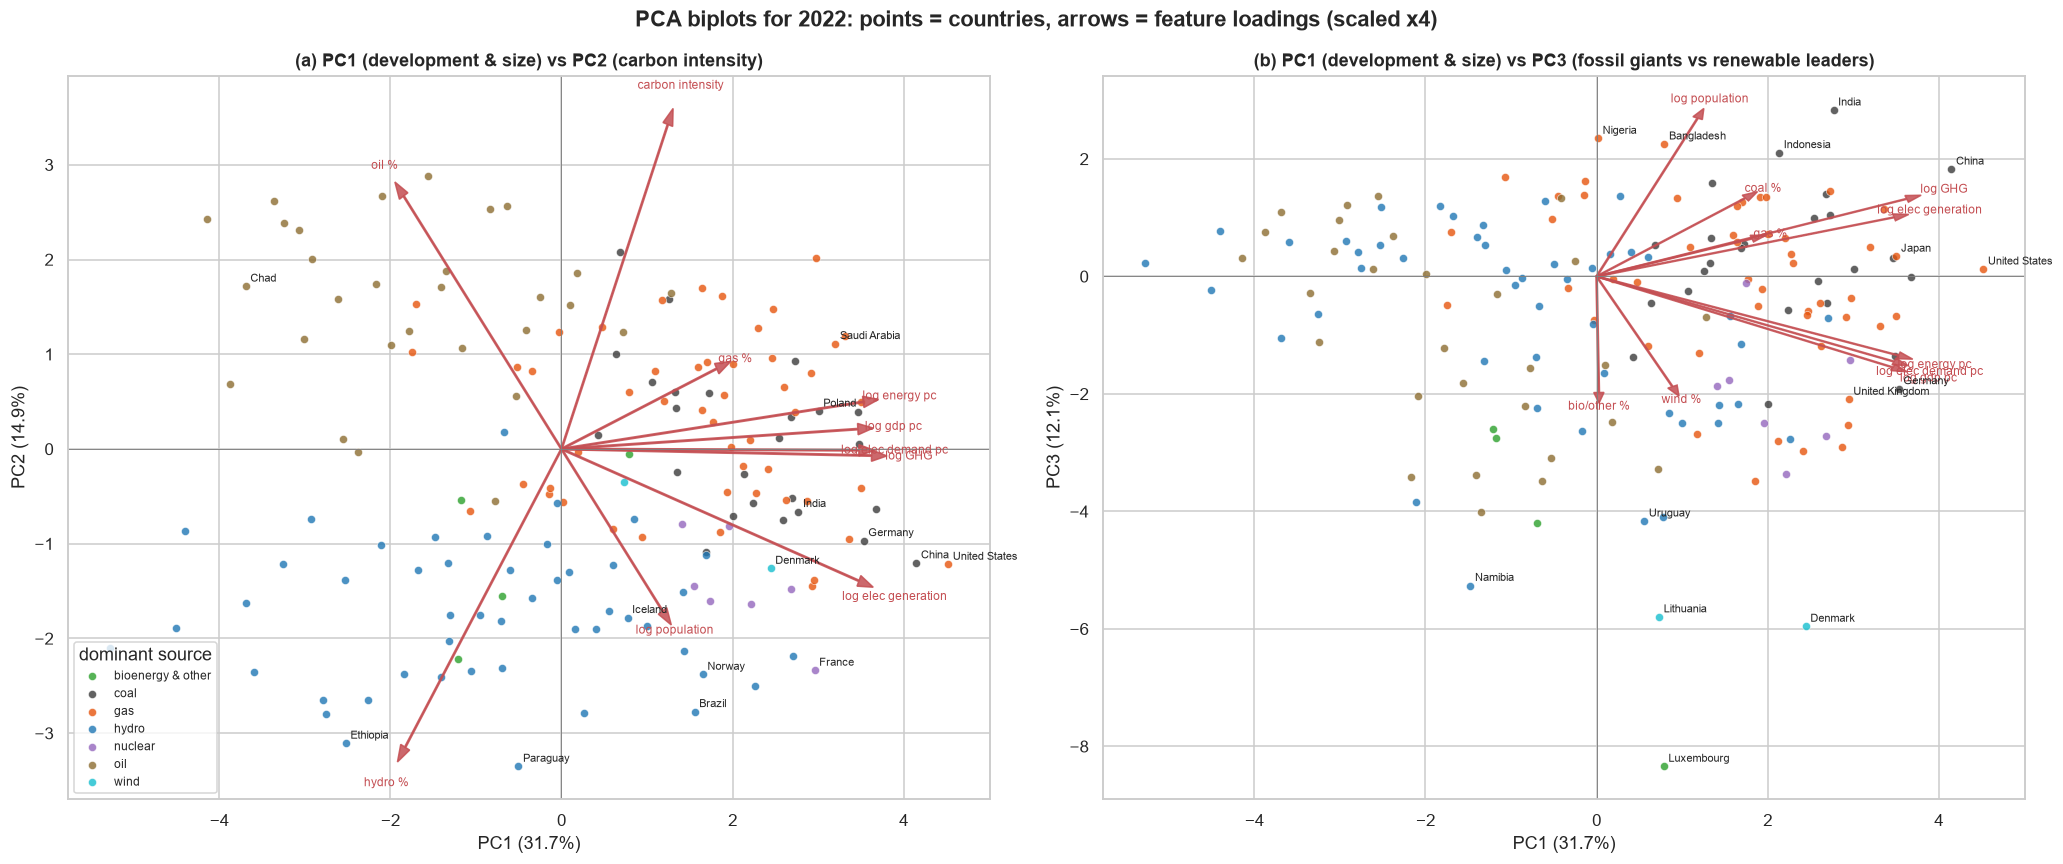

PC1: highest = ['United States', 'China', 'South Korea', 'Germany'] | lowest = ['Central African Republic', 'Sierra Leone', 'Burundi', 'Guinea-Bissau']
PC2: highest = ['Saint Lucia', 'Dominica', 'Comoros', 'Seychelles'] | lowest = ['Paraguay', 'Ethiopia', 'Democratic Republic of Congo', 'Laos']
PC3: highest = ['India', 'Nigeria', 'Bangladesh', 'Indonesia'] | lowest = ['Luxembourg', 'Denmark', 'Lithuania', 'Namibia']


In [82]:
def biplot(ax, xpc, ypc, year=2022, label_countries=(), n_arrows=10, arrow_scale=4.0):
    # Scatter the countries of one year on two PCs and draw the strongest feature loadings as arrows
    sub = pc_df[pc_df["year"] == year]
    for src, grp in sub.groupby("dominant_source"):
        ax.scatter(grp[xpc], grp[ypc], s=28, color=SOURCE_COLORS[src], alpha=0.8, label=src,
                   edgecolor="white", lw=0.4)
    strength = (loadings[xpc] ** 2 + loadings[ypc] ** 2).sort_values(ascending=False)
    for feat in strength.index[:n_arrows]:
        x, y = loadings.at[feat, xpc] * arrow_scale, loadings.at[feat, ypc] * arrow_scale
        ax.arrow(0, 0, x, y, color="#C44E52", alpha=0.85, width=0.015, head_width=0.12)
        ax.text(x * 1.12, y * 1.12, SHORT[feat], color="#C44E52", fontsize=8, ha="center", va="center")
    for name in label_countries:
        row = sub[sub["country"] == name]
        if len(row):
            ax.annotate(name, (row[xpc].iloc[0], row[ypc].iloc[0]), fontsize=7.5,
                        xytext=(3, 3), textcoords="offset points")
    ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6)
    ax.set_xlabel(f"{xpc} ({explained.loc[xpc, '% variance']:.1f}%)")
    ax.set_ylabel(f"{ypc} ({explained.loc[ypc, '% variance']:.1f}%)")


fig, axes = plt.subplots(1, 2, figsize=(19, 8))
biplot(axes[0], "PC1", "PC2", label_countries=["United States", "China", "India", "Germany", "France",
       "Norway", "Iceland", "Paraguay", "Ethiopia", "Saudi Arabia", "Chad", "Brazil", "Poland", "Denmark"])
axes[0].set_title("(a) PC1 (development & size) vs PC2 (carbon intensity)")
axes[0].legend(title="dominant source", fontsize=8, loc="lower left")
biplot(axes[1], "PC1", "PC3", label_countries=["United States", "China", "India", "Germany", "Denmark",
       "Lithuania", "Luxembourg", "Bangladesh", "Nigeria", "Indonesia", "United Kingdom", "Namibia",
       "Uruguay", "Japan"])
axes[1].set_title("(b) PC1 (development & size) vs PC3 (fossil giants vs renewable leaders)")
fig.suptitle("PCA biplots for 2022: points = countries, arrows = feature loadings (scaled x4)",
             fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig25_biplot")
plt.show()

y22 = pc_df[pc_df["year"] == 2022]
for pc in KEEP[:3]:
    print(f"{pc}: highest = {y22.nlargest(4, pc)['country'].tolist()} | "
          f"lowest = {y22.nsmallest(4, pc)['country'].tolist()}")

**Reading the biplots.** Arrows show the direction in which each feature increases; arrows pointing the
same way are positively correlated, opposite arrows negatively correlated, and arrows at right angles
are unrelated.
* In panel (a) the block of development arrows (GDP, energy, demand, generation, emissions) points to
  the right, while carbon intensity and oil point up and hydro points down — at roughly **right angles**
  to the development block. Wealth and cleanliness are separate dimensions.
* The **USA, China and Germany** lie far right on PC1 (large, developed systems); **Chad** and other
  small, poor oil-based systems lie upper left; **Paraguay** and **Ethiopia** (hydro) lie at the bottom;
  **France** and **Norway** are rich *and* clean (right and low).
* In panel (b) PC3 separates the **populous, coal-heavy emerging economies** (*India*, *Bangladesh*,
  *Indonesia*, *Nigeria*) at the top from the **wind and solar leaders** (*Denmark*, *Lithuania*,
  *Luxembourg*, *Namibia*) at the bottom.

### 15.6 The transition over time in PCA space

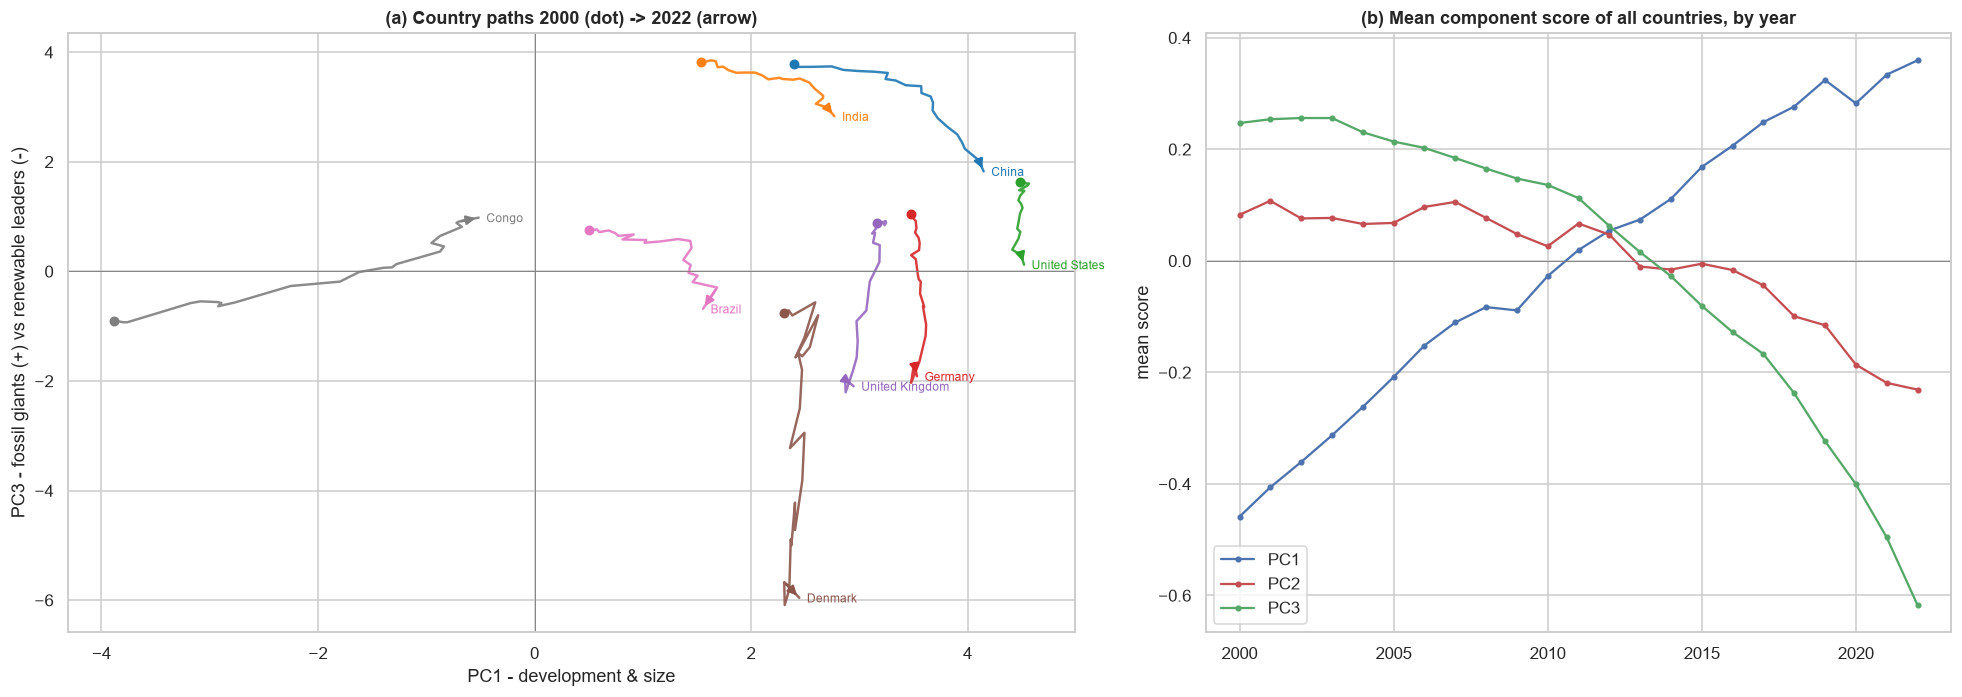

PC1           PC2           PC3       
year             2000   2022   2000   2022   2000   2022
country                                                 
Brazil          0.500  1.560 -2.760 -2.770  0.750 -0.680
China           2.400  4.150 -0.400 -1.200  3.790  1.830
Congo          -3.890 -0.520 -1.620  0.860 -0.900  0.980
Denmark         2.310  2.450  0.870 -1.260 -0.760 -5.960
Germany         3.480  3.530 -0.460 -0.970  1.060 -1.910
India           1.540  2.770 -0.390 -0.660  3.810  2.830
United Kingdom  3.170  2.950 -0.230 -1.380  0.890 -2.090
United States   4.480  4.520 -0.620 -1.220  1.630  0.120

In [83]:
TRACK = ["China", "India", "United States", "Germany", "United Kingdom", "Denmark", "Brazil", "Congo"]
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5), gridspec_kw={"width_ratios": [1.35, 1]})

# (a) Country trajectories on PC1 vs PC3, 2000 -> 2022
pal_t = dict(zip(TRACK, sns.color_palette("tab10", len(TRACK))))
for name in TRACK:
    t = pc_df[pc_df["country"] == name].sort_values("year")
    axes[0].plot(t["PC1"], t["PC3"], color=pal_t[name], lw=1.6, alpha=0.9)
    axes[0].scatter(t["PC1"].iloc[0], t["PC3"].iloc[0], color=pal_t[name], marker="o", s=30)
    axes[0].annotate("", xy=(t["PC1"].iloc[-1], t["PC3"].iloc[-1]),
                     xytext=(t["PC1"].iloc[-2], t["PC3"].iloc[-2]),
                     arrowprops=dict(arrowstyle="-|>", color=pal_t[name], lw=1.6))
    axes[0].annotate(name, (t["PC1"].iloc[-1], t["PC3"].iloc[-1]), fontsize=8, color=pal_t[name],
                     xytext=(5, -3), textcoords="offset points")
axes[0].axhline(0, color="grey", lw=0.6); axes[0].axvline(0, color="grey", lw=0.6)
axes[0].set_xlabel("PC1 - development & size"); axes[0].set_ylabel("PC3 - fossil giants (+) vs renewable leaders (-)")
axes[0].set_title("(a) Country paths 2000 (dot) -> 2022 (arrow)")

# (b) Average score of all countries on PC1-PC3, per year
yearly = pc_df.groupby("year")[KEEP[:3]].mean()
for pc, col in zip(KEEP[:3], ["#4C72B0", "#C44E52", "#55A868"]):
    axes[1].plot(yearly.index, yearly[pc], marker="o", ms=3, label=pc, color=col)
axes[1].axhline(0, color="grey", lw=0.6)
axes[1].set_title("(b) Mean component score of all countries, by year")
axes[1].set_ylabel("mean score"); axes[1].legend()
fig.tight_layout()
save_fig(fig, "fig26_pca_trajectories")
plt.show()

pc_df[pc_df["country"].isin(TRACK) & pc_df["year"].isin([2000, 2022])] \
    .pivot(index="country", columns="year", values=KEEP[:3]).round(2)

* **On average, countries moved right on PC1 and down on PC2 and PC3** between 2000 and 2022: they got
  richer and used more electricity, and their mixes became slightly cleaner, with most of the change
  coming after about 2012 (the wind/solar take-off seen in Part 5).
* **European paths point straight down on PC3** (*Denmark*, *Germany*, the *UK*) at an almost constant
  PC1: they changed the *mix* without changing the *size* of their systems.
* **China and India move right** (rapid development) and only later turn down on PC3 — growth came
  first, the shift towards renewables second.
* **Congo moves up-right**: development was powered by new fossil plants, the reverse of the European
  path (its PC2 score rose from about −1.6 to +0.9, as seen in Part 5).

### 15.7 The component with zero variance

In [84]:
last = pd.Series(pca.components_[-1], index=PCA_FEATURES, name=f"{PC_NAMES[-1]} weights")
print(f"Eigenvalue of {PC_NAMES[-1]}: {pca.explained_variance_[-1]:.2e}")
print("Weights of the last component (eigenvector), largest in absolute value:")
last.reindex(last.abs().sort_values(ascending=False).index).round(3).to_frame().T

Eigenvalue of PC16: 8.79e-11
Weights of the last component (eigenvector), largest in absolute value:


,oil_share_elec,hydro_share_elec,gas_share_elec,coal_share_elec,nuclear_share_elec,other_renewables_share_elec,wind_share_elec,solar_share_elec,log_electricity_generation,log_greenhouse_gas_emissions,log_electricity_demand_per_capita,log_population,log_energy_per_capita,log_gdp_per_capita,carbon_intensity_elec,net_imports_capped
PC16 weights,0.533,0.520,0.485,0.379,0.209,0.119,0.081,0.040,-0.000,0.000,0.000,0.000,0.000,-0.000,0.000,-0.000


The last component puts weight on the eight source **shares** (each weighted by its standard deviation,
since the inputs are z-scores) and none on the other features. Its variance is zero because this
combination is simply the constant *coal + gas + oil + hydro + nuclear + wind + solar + other = 100 %*.
PCA has rediscovered the compositional constraint from the data alone.

### 15.8 Does adding the encoded categorical features change the result?
The same PCA is now run on the **extended matrix** from Part 7 (16 numeric features + ordinal income
group + 5 one-hot continent columns, all standardised).

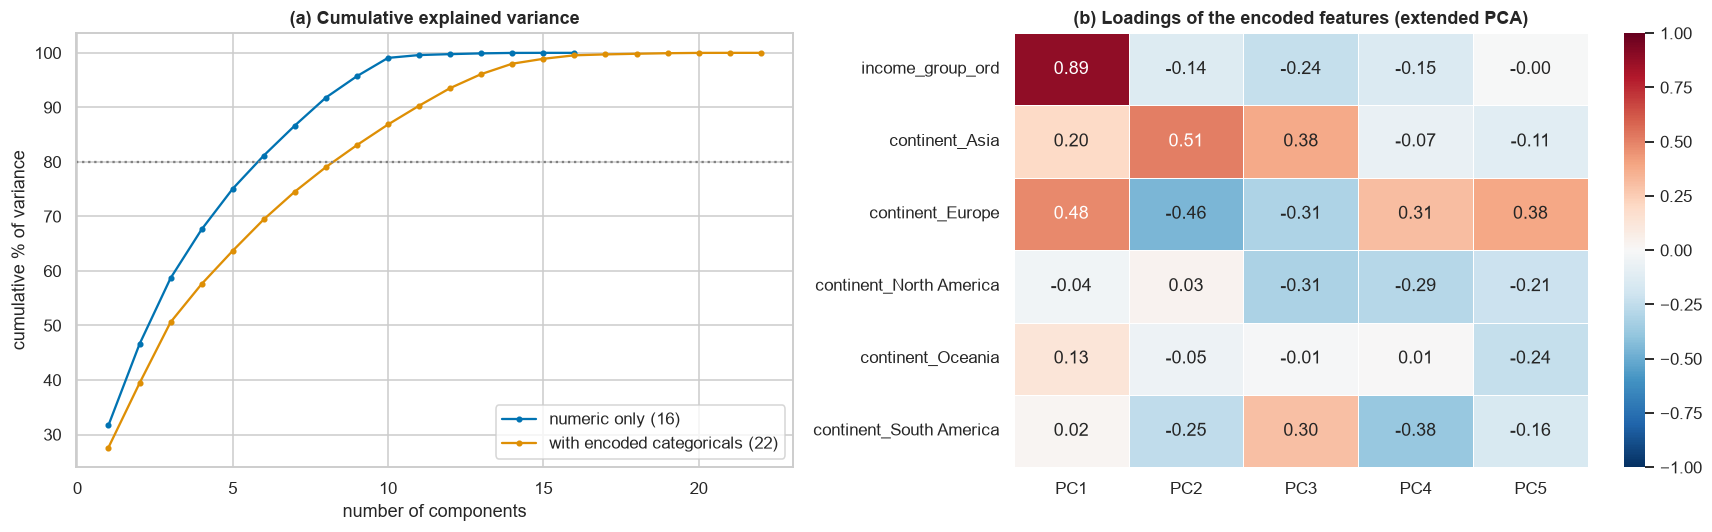

Components with eigenvalue > 1: numeric = 5, extended = 7
Components for 80% variance: numeric = 6, extended = 9
PC1 variance: numeric = 31.7%, extended = 27.6%


In [85]:
pca_ext = PCA(random_state=RANDOM_STATE).fit(X_ext)
ext_var = pd.DataFrame({"numeric only (16)": np.cumsum(pca.explained_variance_ratio_) * 100},
                       index=range(1, n_pc + 1))
ext_var = ext_var.join(pd.DataFrame({"with encoded categoricals (22)":
                                     np.cumsum(pca_ext.explained_variance_ratio_) * 100},
                                    index=range(1, len(EXT_FEATURES) + 1)), how="outer")

ext_load = pd.DataFrame(pca_ext.components_.T * np.sqrt(pca_ext.explained_variance_),
                        index=EXT_FEATURES, columns=[f"PC{i + 1}" for i in range(len(EXT_FEATURES))])

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
ext_var.plot(ax=axes[0], marker="o", ms=3)
axes[0].axhline(80, color="grey", ls=":")
axes[0].set_xlabel("number of components"); axes[0].set_ylabel("cumulative % of variance")
axes[0].set_title("(a) Cumulative explained variance")
enc_rows = ["income_group_ord"] + cont_oh_drop.columns.tolist()
sns.heatmap(ext_load.loc[enc_rows, [f"PC{i}" for i in range(1, 6)]], annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, center=0, ax=axes[1], linewidths=0.5)
axes[1].set_title("(b) Loadings of the encoded features (extended PCA)")
fig.tight_layout()
save_fig(fig, "fig27_pca_with_encoded")
plt.show()

k80 = lambda s: int((s >= 80).idxmax())
print(f"Components with eigenvalue > 1: numeric = {(pca.explained_variance_ > 1).sum()}, "
      f"extended = {(pca_ext.explained_variance_ > 1).sum()}")
print(f"Components for 80% variance: numeric = {k80(ext_var.iloc[:, 0].dropna())}, "
      f"extended = {k80(ext_var.iloc[:, 1].dropna())}")
print(f"PC1 variance: numeric = {pca.explained_variance_ratio_[0] * 100:.1f}%, "
      f"extended = {pca_ext.explained_variance_ratio_[0] * 100:.1f}%")

* The **ordinal income group loads ≈ 0.9 on PC1**: it fits naturally onto the development axis, which
  confirms that PC1 really measures economic development.
* The **one-hot continent columns** load only moderately and are spread over several components. Each
  dummy is a mostly independent 0/1 variable, so together they **add dimensions** instead of reinforcing
  the existing ones. More components are needed for the same share of variance (see the table printed
  above), and PC1 explains a smaller share.
* For this reason the **numeric-only PCA is preferred for interpretation**, and the categorical
  features are more useful as **labels for colouring** the PCA results (Section 15.4). This is a
  general lesson: one-hot encoding is the correct way to encode nominal data, but binary dummies are a
  poor fit for a variance-based method like PCA.

### 15.9 Answer to Q6 – what PCA tells us

* **Yes, the 16 indicators can be summarised compactly.** Five components keep about 75 % of the
  variance (69 % fewer dimensions), and the first three alone keep about 59 %.
* The components have a clear meaning: **PC1 = development and size**, **PC2 = carbon intensity
  (oil vs hydro)**, **PC3 = fossil-heavy emerging giants vs renewable leaders (the transition axis)**,
  **PC4 = mix diversity and interconnection**, **PC5 = gas vs coal/nuclear**.
* PC1 and PC2 are uncorrelated by construction, and the income groups separate only on PC1. **Economic
  development and clean electricity are distinct dimensions**, which is the central finding of this
  project.
* The near-zero last components show that several indicators are exact or near-exact combinations of
  others. PCA removes this redundancy automatically.
* **Limitations of the PCA:** it captures only *linear* structure (the inverted-U between wealth and
  carbon intensity in Part 6 is non-linear); the zero-inflated shares (nuclear, wind, solar) are far
  from normal; and the panel mixes 23 years per country, so rows are not independent observations.

## 16. Conclusions

**Problem.** This project explored how national electricity systems changed between 2000 and 2022, and
how wealth, population and demand relate to the carbon intensity and fuel mix of electricity, using the
Our World in Data energy dataset.

**Data preparation.** The raw table (23,377 × 130) was reduced to a clean, consistent panel of
**3,790 country-years × 31 columns** (165 countries) by removing regional aggregates, choosing a window
with complete coverage, selecting non-redundant indicators, treating missing values according to their
cause (dropping countries without GDP, filling 429 structural zeros, interpolating 7 values), correcting
67 physically implausible carbon intensities, and log-transforming or capping skewed features.

**Main findings**
1. **Global mix (Q1):** wind and solar grew from 0.2 % to about 12 % of global electricity, but coal is
   still the largest source and nuclear's share almost halved. Global carbon intensity fell by only
   about 7 %, and only after 2014.
2. **Distributions and unusual countries (Q2):** carbon intensity is bimodal (hydro vs fossil systems)
   and countries are not converging. Some European countries more than halved their intensity, while
   several hydro-dependent African countries became far more carbon-intensive.
3. **Wealth (Q3):** wealth strongly predicts electricity demand (elasticity ≈ 1.3) but hardly predicts
   carbon intensity. The relationship is an inverted U: the poorest (hydro) and richest (nuclear,
   renewables) countries are cleaner than middle-income ones.
4. **Continents (Q4):** North America, Oceania and Europe cut carbon intensity by 25–31 %; Asia and
   Africa barely changed; South America got dirtier but remains the cleanest.
5. **Substitution (Q5):** wind, solar and hydro substitute for fossil fuels, but in some countries
   nuclear closures cancelled out renewable growth.
6. **PCA (Q6):** five components summarise 75 % of the variance; development (PC1) and carbon intensity
   (PC2) are independent dimensions, and a third "transition" axis separates fossil-heavy emerging
   economies from renewable leaders.

**Overall conclusion.** Getting richer does not, by itself, make electricity cleaner. Cleanliness depends
on the **choice of sources**, and the countries that decarbonised fastest did so by adding wind and solar
while keeping (or adding) other low-carbon capacity. As demand grows fastest in developing countries,
whether that growth is met by fossil or low-carbon sources will decide the global trend.

**Challenges faced:** separating overlapping aggregates from countries; sources with different time
coverage; distinguishing "missing" from "zero"; deciding which extreme values were real and which were
errors (domain rules were needed, not just statistics); statistical outlier rules that over-flag skewed
and zero-inflated data; compositional shares and accounting identities that create redundancy (low KMO).

**Limitations and future work:** the 54 countries without GDP (mostly small island states) are excluded;
GDP data end in 2022, so the most recent solar growth (2023–2025) is outside the panel; income groups
are relative quartiles rather than official World Bank groups. Future work could add official income
classifications and policy variables (e.g. carbon prices), use compositional methods such as log-ratio
transforms for the shares (Aitchison, 1986), or apply clustering on the PCA scores to group countries
into transition pathways.

## 17. References

Aitchison, J. (1986) *The statistical analysis of compositional data*. London: Chapman and Hall.

Bolt, J. and van Zanden, J.L. (2024) 'Maddison style estimates of the evolution of the world economy:
a new 2023 update', *Journal of Economic Surveys*, 38(2), pp. 631–671.

Ember (2025) *Yearly electricity data*. London: Ember. Available at:
https://ember-energy.org/data/yearly-electricity-data/ (Accessed: 27 November 2026).

Energy Institute (2025) *Statistical review of world energy 2025*. 74th edn. London: Energy Institute.
Available at: https://www.energyinst.org/statistical-review (Accessed: 27 November 2026).

Grossman, G.M. and Krueger, A.B. (1995) 'Economic growth and the environment', *The Quarterly Journal of
Economics*, 110(2), pp. 353–377.

International Energy Agency (IEA) (2024) *World energy outlook 2024*. Paris: IEA. Available at:
https://www.iea.org/reports/world-energy-outlook-2024 (Accessed: 27 November 2026).

Jolliffe, I.T. (2002) *Principal component analysis*. 2nd edn. New York: Springer.

Kaiser, H.F. (1960) 'The application of electronic computers to factor analysis', *Educational and
Psychological Measurement*, 20(1), pp. 141–151.

Kaiser, H.F. (1974) 'An index of factorial simplicity', *Psychometrika*, 39(1), pp. 31–36.

Our World in Data (2026) *Data on energy by Our World in Data* [Data set]. GitHub. Available at:
https://github.com/owid/energy-data (Accessed: 27 November 2026).

Pearson, K. (1901) 'On lines and planes of closest fit to systems of points in space', *The London,
Edinburgh, and Dublin Philosophical Magazine and Journal of Science*, 2(11), pp. 559–572.

Pedregosa, F. *et al.* (2011) 'Scikit-learn: machine learning in Python', *Journal of Machine Learning
Research*, 12, pp. 2825–2830.

Ritchie, H., Rosado, P. and Roser, M. (2023) 'Energy', *Our World in Data*. Available at:
https://ourworldindata.org/energy (Accessed: 27 November 2026).

Schlömer, S. *et al.* (2014) 'Annex III: Technology-specific cost and performance parameters', in
Edenhofer, O. *et al.* (eds.) *Climate change 2014: mitigation of climate change. Contribution of Working
Group III to the Fifth Assessment Report of the Intergovernmental Panel on Climate Change*. Cambridge:
Cambridge University Press, pp. 1329–1356.

United Nations (2015) *Transforming our world: the 2030 Agenda for Sustainable Development*
(A/RES/70/1). New York: United Nations.

United Nations Framework Convention on Climate Change (UNFCCC) (2015) *Paris Agreement*. Bonn: UNFCCC.
Available at: https://unfccc.int/sites/default/files/english_paris_agreement.pdf (Accessed:
27 November 2026).

Wickham, H., Çetinkaya-Rundel, M. and Grolemund, G. (2023) *R for data science*. 2nd edn. Sebastopol,
CA: O'Reilly Media.